# Results for the paper

### Evaluation of SWOT-Derived Surface Geostrophic Currents Using HF Radar Observations in the Southern Agulhas Current

For submission to GRL Call for Papers: [Science from the Surface Water and Ocean Topography Satellite Mission](https://agupubs.onlinelibrary.wiley.com/hub/journal/19448007/homepage/call-for-papers/si-2023-001028)

Submission deadline: Thursday, 31 December 2026

## Download data

### SWOT

#### AVISO+ authentication

Protected AVISO products require credentials. The downloader stores them in `~/.altimetry/.netrc` and configures the environment used by `requests` and `netCDF4`; credentials are never written to the notebook.

In [1]:
from altimetry_downloader_aviso.auth import NETRC_PATH, ensure_credentials

# This prompts once if credentials are not already configured.
ensure_credentials('tds-odatis.aviso.altimetry.fr')
print(f'AVISO+ credentials configured through {NETRC_PATH}')

AVISO+ credentials configured through ~/.altimetry/.netrc


In [2]:
# Catalogue discovery for the one product used in this notebook:
# SWOT L3 LR SSH Expert, version 3.0.
import altimetry_downloader_aviso as dl_aviso
import requests
import xml.etree.ElementTree as ET

PRODUCT_SHORT_NAME = 'SWOT_L3_LR_SSH_Expert'
TDS_L3_CATALOG = (
    'https://tds-odatis.aviso.altimetry.fr/thredds/catalog/'
    'dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/catalog.xml'
)

try:
    aviso_catalogue = dl_aviso.summary()
    matching_products = [
        product for product in aviso_catalogue.products
        if product.short_name == PRODUCT_SHORT_NAME
    ]
    print('Selected product:')
    for product in matching_products:
        print(f'  {product.short_name} -> {product.title}')
    if not matching_products:
        print(f'Product not found in GeoNetwork catalogue: {PRODUCT_SHORT_NAME}')
except Exception as error:
    print(f'GeoNetwork catalogue unavailable: {error}')

try:
    response = requests.get(TDS_L3_CATALOG, timeout=30)
    response.raise_for_status()
    root = ET.fromstring(response.content)
    namespace = {'thredds': 'http://www.unidata.ucar.edu/namespaces/thredds/InvCatalog/v1.0'}
    references = root.findall('.//thredds:catalogRef', namespace)
    versions = [
        ref.attrib.get('{http://www.w3.org/1999/xlink}title')
        for ref in references
    ]
    print(f'\nL3 Expert catalogue: {TDS_L3_CATALOG}')
    print(f'Available versions: {versions}')
    print('Selected version: v3_0')
except (requests.RequestException, ET.ParseError) as error:
    print(f'L3 Expert catalogue unavailable: {type(error).__name__}: {error}')

Selected product:
  SWOT_L3_LR_SSH_Expert -> Altimetry product SWOT Level-3 Low Rate SSH - Expert

L3 Expert catalogue: https://tds-odatis.aviso.altimetry.fr/thredds/catalog/dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/catalog.xml
Available versions: ['v2_0_1', 'v3_0']
Selected version: v3_0


In [3]:
# Configuration for the requested SWOT L3 download selection.
from pathlib import Path
import pandas as pd

repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SWOT_START_DATE = pd.Timestamp('2024-11-10')
SWOT_END_DATE = pd.Timestamp('2026-04-21')
SWOT_L3_DIR = repo_root / 'data/raw/swot_l3_expert'
DOWNLOAD = True

In [4]:
# Discover catalogue granules and download only the requested SWOT L3 Expert passes.
from concurrent.futures import ThreadPoolExecutor, as_completed
from netrc import netrc
from urllib.parse import urljoin
import re
import time
import pandas as pd
import requests
import xml.etree.ElementTree as ET

DOWNLOAD_HOST = 'tds-odatis.aviso.altimetry.fr'
credentials = netrc(NETRC_PATH).authenticators(DOWNLOAD_HOST)
if credentials is None:
    raise RuntimeError(f'No AVISO+ credentials found for {DOWNLOAD_HOST} in {NETRC_PATH}')
TDS_AUTH = (credentials[0], credentials[2])

TDS_ROOT = 'https://tds-odatis.aviso.altimetry.fr/thredds'
TDS_VERSION_ROOT = f'{TDS_ROOT}/catalog/dataset-l3-swot-karin-nadir-validated/l3_lr_ssh/v3_0/Expert'
TDS_PARENT_CATALOG = f'{TDS_VERSION_ROOT}/catalog.xml'
TDS_FILESERVER_ROOT = f'{TDS_ROOT}/fileServer'
XML_NAMESPACE = {'thredds': 'http://www.unidata.ucar.edu/namespaces/thredds/InvCatalog/v1.0'}
XLINK_HREF = '{http://www.w3.org/1999/xlink}href'

# Explicitly requested passes. No spatial verification or probe downloads are run.
COVERING_PASS_NUMBERS = [
    430, 443, 458, 471, 486, 499,
    514, 527, 542, 555, 570, 583,
]
MAX_WORKERS = 8
DOWNLOAD_WORKERS = 4


def read_catalog(catalog_url):
    response = requests.get(catalog_url, auth=TDS_AUTH, timeout=30)
    response.raise_for_status()
    return ET.fromstring(response.content)


def download_granule(url_path, local_file, max_retries=3, backoff_seconds=5):
    http_url = f'{TDS_FILESERVER_ROOT}/{url_path}'
    for attempt in range(1, max_retries + 1):
        try:
            response_download = requests.get(http_url, auth=TDS_AUTH, timeout=120, stream=True)
            response_download.raise_for_status()
            with open(local_file, 'wb') as output_file:
                for chunk in response_download.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        output_file.write(chunk)
            return
        except (requests.exceptions.RequestException, OSError) as error:
            local_file.unlink(missing_ok=True)
            if attempt == max_retries:
                raise
            print(f'    Retry {attempt}/{max_retries} after {type(error).__name__}: {error}')
            time.sleep(backoff_seconds * attempt)


# Walk the parent catalogue so reprocessed and forward branches are both included.
pending_catalogs = [TDS_PARENT_CATALOG]
visited_catalogs = set()
cycle_catalogs = {}
while pending_catalogs:
    catalog_url = pending_catalogs.pop()
    if catalog_url in visited_catalogs:
        continue
    visited_catalogs.add(catalog_url)
    try:
        root = read_catalog(catalog_url)
    except (requests.RequestException, ET.ParseError) as error:
        print(f'Catalogue unavailable: {catalog_url} ({type(error).__name__})')
        continue

    for reference in root.findall('.//thredds:catalogRef', XML_NAMESPACE):
        child_catalog = urljoin(catalog_url, reference.attrib.get(XLINK_HREF, ''))
        cycle_match = re.search(r'/cycle_(\d+)/catalog\.xml$', child_catalog)
        if cycle_match:
            cycle_catalogs[child_catalog] = int(cycle_match.group(1))
        elif child_catalog.endswith('.xml'):
            pending_catalogs.append(child_catalog)

print(f'Catalogue branches visited: {len(visited_catalogs)}')
print(f'Cycle catalogues discovered: {len(cycle_catalogs)}')


# Fetch each cycle listing once and reuse it to build the download manifest.
def fetch_cycle_granules(cycle_catalog):
    try:
        root = read_catalog(cycle_catalog)
        return cycle_catalog, [
            (dataset.attrib['name'], dataset.attrib.get('urlPath'))
            for dataset in root.findall('.//thredds:dataset[@name]', XML_NAMESPACE)
        ]
    except (requests.RequestException, ET.ParseError) as error:
        print(f'Cycle {cycle_catalogs[cycle_catalog]}: catalogue unavailable ({type(error).__name__})')
        return cycle_catalog, []


cycle_granules = {}
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(fetch_cycle_granules, catalog) for catalog in cycle_catalogs]
    for future in as_completed(futures):
        catalog, granules = future.result()
        cycle_granules[catalog] = granules

print(f'Requested pass numbers: {COVERING_PASS_NUMBERS}')

# Build a date-filtered, de-duplicated manifest before starting downloads.
download_manifest = []
manifest_paths = set()
for cycle_catalog, cycle in sorted(cycle_catalogs.items(), key=lambda item: (item[1], item[0])):
    for granule_name, url_path in cycle_granules.get(cycle_catalog, []):
        pass_match = re.search(r'_(\d{3})_(\d{3})_', granule_name)
        date_match = re.search(r'_(\d{8})T\d{6}_', granule_name)
        if pass_match is None or date_match is None or not url_path:
            continue
        if int(pass_match.group(2)) not in COVERING_PASS_NUMBERS:
            continue
        granule_date = pd.Timestamp(date_match.group(1))
        if not (SWOT_START_DATE <= granule_date <= SWOT_END_DATE):
            continue
        local_file = SWOT_L3_DIR / granule_name
        if local_file in manifest_paths:
            continue
        manifest_paths.add(local_file)
        download_manifest.append((granule_name, url_path, local_file))

L3_TEST_FILES = []
FAILED_DOWNLOADS = []
NOT_DOWNLOADED = []
pending_downloads = []
for granule_name, url_path, local_file in download_manifest:
    if local_file.exists():
        L3_TEST_FILES.append(str(local_file))
    elif DOWNLOAD:
        pending_downloads.append((granule_name, url_path, local_file))
    else:
        NOT_DOWNLOADED.append(granule_name)

print(f'Download manifest: {len(download_manifest)} files')
print(f'Already present: {len(L3_TEST_FILES)}')
print(f'Remaining to download: {len(pending_downloads)}')


def download_one(entry):
    granule_name, url_path, local_file = entry
    try:
        download_granule(url_path, local_file)
        return granule_name, local_file, None
    except Exception as error:
        return granule_name, local_file, f'{type(error).__name__}: {error}'


if pending_downloads:
    completed_count = len(L3_TEST_FILES)
    started_at = time.monotonic()
    with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as executor:
        futures = [executor.submit(download_one, entry) for entry in pending_downloads]
        for future in as_completed(futures):
            granule_name, local_file, error = future.result()
            completed_count += 1
            if error is None and local_file.exists():
                L3_TEST_FILES.append(str(local_file))
                status = 'complete'
            else:
                FAILED_DOWNLOADS.append(granule_name)
                status = f'failed ({error})'
            elapsed_minutes = (time.monotonic() - started_at) / 60
            print(f'Download progress: {completed_count}/{len(download_manifest)} '
                  f'({100 * completed_count / len(download_manifest):.1f}%) - '
                  f'{status}: {granule_name} - {elapsed_minutes:.1f} min elapsed')
else:
    print('No new downloads required.')

print(f'\nSelected local files: {len(L3_TEST_FILES)}')
if FAILED_DOWNLOADS:
    print(f'Failed downloads (re-run this cell to retry): {len(FAILED_DOWNLOADS)}')
    for name in FAILED_DOWNLOADS:
        print(f'  {name}')
if NOT_DOWNLOADED:
    print(f'Download disabled for {len(NOT_DOWNLOADED)} missing files.')

Catalogue branches visited: 3
Cycle catalogues discovered: 161
Requested pass numbers: [430, 443, 458, 471, 486, 499, 514, 527, 542, 555, 570, 583]
Download manifest: 301 files
Already present: 301
Remaining to download: 0
No new downloads required.

Selected local files: 301


### HF Radar

HF radar sea surface velocity off the South African coast and processed with HYDDOA v.2 are available for download from: [https://odp.saeon.ac.za/mims/catalog/10.15493/DEA.MIMS.20250406](https://odp.saeon.ac.za/mims/catalog/10.15493/DEA.MIMS.20250406)

## Methods and results

In [5]:
# This notebook processes HF-radar NetCDF files, extracts eastward and northward velocity components,
# and stores the cleaned data in a Zarr archive, avoiding duplicate time steps.
from pathlib import Path
import shutil
import numpy as np
import xarray as xr

# Use the repository root explicitly so the paths are stable when the notebook
# is run from VS Code, Jupyter, or the terminal.
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
raw_dir = repo_root / "data/raw/hf_radar"
years = ("2024", "2025", "2026")
zarr_path = repo_root / "data/processed/hf_radar.zarr"
rebuild_hf_radar_zarr = False
skipped_log_path = repo_root / "data/processed/hf_radar_skipped_files.txt"
zarr_path.parent.mkdir(parents=True, exist_ok=True)

files = []
for year in years:
    year_dir = raw_dir / year
    year_files = sorted(year_dir.rglob("*.nc")) if year_dir.exists() else []
    print(f"{year}: found {len(year_files)} NetCDF files in {year_dir}")
    files.extend(year_files)

files = sorted(files)
print(f"total files found: {len(files)}")

if not files:
    raise FileNotFoundError(
        f"No .nc files found below {raw_dir} for years {', '.join(years)}."
    )

velocity_vars = ("ewct", "nsct")  # eastward and northward velocity components


def prep(ds, source_path):
    """Keep eastward/northward velocities and ensure a sorted time axis."""
    missing = [name for name in velocity_vars if name not in ds.data_vars]
    if missing:
        raise KeyError(f"{source_path} is missing variables: {missing}")
    if "time" not in ds.dims:
        raise KeyError(f"{source_path} does not contain a time dimension")

    return ds[list(velocity_vars)].sortby("time")


def open_prepared_dataset(file_path):
    """Open one NetCDF file and return a loaded, safe dataset."""
    try:
        with xr.open_dataset(file_path) as ds:
            prepared = prep(ds, file_path).load()
    except Exception as exc:
        return None, f"{file_path}\t{type(exc).__name__}: {exc}"

    return prepared.chunk({"time": 1, "latitude": 75, "longitude": 150}), None


# Inspect the first readable file to confirm variable and dimension names.
for first_file in files:
    ds0, error = open_prepared_dataset(first_file)
    if ds0 is not None:
        print(ds0)
        ds0.close()
        break
else:
    raise OSError("No readable HF-radar NetCDF files were found.")

if zarr_path.exists() and not rebuild_hf_radar_zarr:
    print(f"Using existing HF-radar archive: {zarr_path}")
    ds_all = xr.open_zarr(zarr_path, consolidated=True)
    skipped_files = []
    skipped_duplicate_times = 0
    written = ds_all.sizes["time"]
else:
    if zarr_path.exists():
        if zarr_path.is_dir():
            shutil.rmtree(zarr_path)
        else:
            zarr_path.unlink()

    seen_times = set()
    written = 0
    skipped_duplicate_times = 0
    skipped_files = []

    for i, file_path in enumerate(files, start=1):
        ds, error = open_prepared_dataset(file_path)

        if ds is None:
            skipped_files.append(error)
            if len(skipped_files) <= 10:
                print(f"skipping unreadable file: {error}")
            continue

        time_values = np.asarray(ds.time.values).ravel()
        time_keys = [np.datetime_as_string(t, unit="ns") for t in time_values]
        keep = np.array([key not in seen_times for key in time_keys], dtype=bool)

        if not keep.any():
            skipped_duplicate_times += len(time_keys)
            ds.close()
            continue

        if not keep.all():
            skipped_duplicate_times += int((~keep).sum())
            ds = ds.isel(time=keep)
            time_keys = [key for key, keep_one in zip(time_keys, keep) if keep_one]

        mode = "w" if written == 0 else "a"
        kwargs = {} if written == 0 else {"append_dim": "time"}
        ds.to_zarr(
            zarr_path,
            mode=mode,
            consolidated=True,
            zarr_format=2,
            **kwargs,
        )
        ds.close()

        seen_times.update(time_keys)
        written += len(time_keys)

        if i == 1 or i % 500 == 0 or i == len(files):
            print(f"processed {i}/{len(files)} files; written {written} time steps")

    if skipped_files:
        skipped_log_path.write_text("\n".join(skipped_files) + "\n")
        print(
            f"skipped {len(skipped_files)} unreadable files; "
            f"details written to {skipped_log_path}"
        )
    else:
        skipped_log_path.unlink(missing_ok=True)

    if written == 0:
        raise OSError("No readable, non-duplicate HF-radar time steps were written to Zarr.")

    ds_all = xr.open_zarr(zarr_path, consolidated=True)

print(ds_all)
print("variables:", list(ds_all.data_vars))
print("time range:", ds_all.time.values[0], "to", ds_all.time.values[-1])
print("time steps:", ds_all.sizes["time"])
print("unreadable files skipped:", len(skipped_files))
print("duplicate timestamps skipped:", skipped_duplicate_times)
print("duplicate timestamps in Zarr:", int(ds_all.time.to_index().duplicated().sum()))

2024: found 719 NetCDF files in <repo>/data/raw/hf_radar/2024
2025: found 17430 NetCDF files in <repo>/data/raw/hf_radar/2025
2026: found 6459 NetCDF files in <repo>/data/raw/hf_radar/2026
total files found: 24608
<xarray.Dataset> Size: 92kB
Dimensions:    (time: 1, latitude: 75, longitude: 150)
Coordinates:
  * time       (time) datetime64[ns] 8B 2024-11-10T15:30:00
  * latitude   (latitude) float64 600B -33.73 -33.78 -33.84 ... -37.67 -37.73
  * longitude  (longitude) float64 1kB 19.0 19.07 19.13 ... 28.79 28.86 28.93
Data variables:
    ewct       (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
    nsct       (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
Attributes: (12/35)
    max_gdop:                  -1.0
    max_err:                   -1.0
    max_dist:                  -1.0
    smooth:                    0
    id:                        South_Africa_HF_Radar_20201231
    naming_authorit

In [6]:
# Process SWOT L3 filtered velocities and store one representative pass time per file.
import shutil

import numpy as np
import pandas as pd
import xarray as xr
from scipy.interpolate import RegularGridInterpolator

swot_raw_dir = repo_root / "data/raw/swot_l3_expert"
radar_zarr_path = repo_root / "data/processed/hf_radar.zarr"
swot_out_zarr_path = repo_root / "data/processed/swot_filtered_velocity.zarr"
overwrite_swot_zarr = False
lon_min, lon_max = 20.0, 28.0
lat_min, lat_max = -38.0, -33.0
swot_velocity_vars = ("ugos_filtered", "vgos_filtered")

skipped_swot_files = []
if swot_out_zarr_path.exists() and not overwrite_swot_zarr:
    print(f"Using existing SWOT filtered-velocity archive: {swot_out_zarr_path}")
else:
    swot_files_all = sorted(swot_raw_dir.rglob("*.nc"))
    print(f"found {len(swot_files_all)} SWOT L3 files in {swot_raw_dir}")
    if not swot_files_all:
        raise FileNotFoundError(f"No .nc files found below {swot_raw_dir}")

    with xr.open_zarr(radar_zarr_path, consolidated=True, chunks=None) as hf_radar_archive:
        hf_lat_order = np.argsort(hf_radar_archive.latitude.values)
        hf_latitude = np.asarray(hf_radar_archive.latitude.values, dtype=float)[hf_lat_order]
        hf_longitude = np.asarray(hf_radar_archive.longitude.values, dtype=float)
        hf_footprint = (
            np.isfinite(hf_radar_archive["ewct"].isel(latitude=hf_lat_order).values).any(axis=0)
            & np.isfinite(hf_radar_archive["nsct"].isel(latitude=hf_lat_order).values).any(axis=0)
        )
        hf_time_start = pd.Timestamp(hf_radar_archive.time.values.min())
        hf_time_end = pd.Timestamp(hf_radar_archive.time.values.max())

    hf_footprint_interp = RegularGridInterpolator(
        (hf_latitude, hf_longitude), hf_footprint,
        method="nearest", bounds_error=False, fill_value=False,
    )


    def representative_pass_time(ds, file_path):
        missing = [name for name in swot_velocity_vars if name not in ds.data_vars]
        if missing:
            raise KeyError(f"{file_path} is missing variables: {missing}")
        if "time" not in ds.variables:
            raise KeyError(f"{file_path} has no measurement time variable")

        time_dim = ds["time"].dims[0]
        source_times = pd.DatetimeIndex(pd.to_datetime(ds["time"].values))
        latitude = np.asarray(ds["latitude"].values, dtype=float)
        longitude = np.asarray(ds["longitude"].values, dtype=float)
        u_velocity = np.asarray(ds["ugos_filtered"].values, dtype=float)
        v_velocity = np.asarray(ds["vgos_filtered"].values, dtype=float)
        region_mask = (
            np.isfinite(latitude) & np.isfinite(longitude)
            & (latitude >= lat_min) & (latitude <= lat_max)
            & (longitude >= lon_min) & (longitude <= lon_max)
        )
        footprint_mask = np.asarray(
            hf_footprint_interp(np.column_stack((latitude.ravel(), longitude.ravel()))),
            dtype=bool,
        ).reshape(latitude.shape)
        valid = region_mask & footprint_mask & np.isfinite(u_velocity) & np.isfinite(v_velocity)
        spatial_axes = tuple(axis for axis, dim in enumerate(ds["latitude"].dims) if dim != time_dim)
        line_valid = valid.any(axis=spatial_axes)
        valid_line_indices = np.flatnonzero(line_valid)
        if valid_line_indices.size == 0:
            raise ValueError(f"No valid SWOT measurements overlap the HF-radar footprint in {file_path}")
        valid_time_ns = np.sort(source_times.asi8[valid_line_indices])
        middle = valid_time_ns.size // 2
        if valid_time_ns.size % 2:
            median_time_ns = valid_time_ns[middle]
        else:
            median_time_ns = (valid_time_ns[middle - 1] + valid_time_ns[middle]) // 2
        return pd.Timestamp(median_time_ns, unit="ns")


    def prep_swot(ds, file_path):
        pass_time = representative_pass_time(ds, file_path)
        latitude = ds["latitude"]
        longitude = ds["longitude"]
        region_mask = (
            (latitude >= lat_min) & (latitude <= lat_max)
            & (longitude >= lon_min) & (longitude <= lon_max)
        )
        prepared = ds[list(swot_velocity_vars)].where(region_mask).astype("float32")
        pass_time_value = pass_time.to_datetime64()
        prepared = prepared.expand_dims(time=[pass_time_value])
        prepared = prepared.assign_coords(
            latitude=latitude.expand_dims(time=[pass_time_value]),
            longitude=longitude.expand_dims(time=[pass_time_value]),
        )
        for variable in prepared.variables:
            prepared[variable].encoding = {}
        prepared["time"].encoding = {
            "dtype": "int64",
            "units": "nanoseconds since 1970-01-01 00:00:00",
            "calendar": "standard",
        }
        for variable in swot_velocity_vars:
            prepared[variable].encoding = {"dtype": "float32", "_FillValue": np.float32(np.nan)}
        return prepared.load()


    filtered_swot_files = []
    for file_path in swot_files_all:
        try:
            with xr.open_dataset(file_path) as ds:
                pass_time = representative_pass_time(ds, file_path)
        except Exception as exc:
            skipped_swot_files.append(f"{file_path}\t{type(exc).__name__}: {exc}")
            continue
        if not (hf_time_start <= pass_time <= hf_time_end):
            skipped_swot_files.append(f"{file_path}\toutside HF period")
            continue
        filtered_swot_files.append(file_path)
    swot_files_all = filtered_swot_files
    print(f"selected {len(swot_files_all)} SWOT files within HF period {hf_time_start} to {hf_time_end}")

    if swot_out_zarr_path.exists():
        shutil.rmtree(swot_out_zarr_path)

    written_passes = 0
    for i, file_path in enumerate(swot_files_all, start=1):
        try:
            with xr.open_dataset(file_path) as ds:
                prepared = prep_swot(ds, file_path)
        except Exception as exc:
            skipped_swot_files.append(f"{file_path}\t{type(exc).__name__}: {exc}")
            continue
        if not np.isfinite(prepared["ugos_filtered"].values).any():
            prepared.close()
            continue
        mode = "w" if written_passes == 0 else "a"
        kwargs = {} if written_passes == 0 else {"append_dim": "time"}
        prepared.to_zarr(swot_out_zarr_path, mode=mode, consolidated=True, zarr_format=2, **kwargs)
        prepared.close()
        written_passes += 1
        if i == 1 or i % 50 == 0 or i == len(swot_files_all):
            print(f"processed {i}/{len(swot_files_all)} files; written {written_passes} passes")

    if written_passes == 0:
        raise OSError("No SWOT passes with data inside the bounding box were written.")
swot_out_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)
written_passes = swot_out_ds.sizes["time"]
print(swot_out_ds)
print("variables:", list(swot_out_ds.data_vars))
print("passes written:", swot_out_ds.sizes["time"])
print("time range:", swot_out_ds.time.values[0], "to", swot_out_ds.time.values[-1])
print("files skipped:", len(skipped_swot_files))

Using existing SWOT filtered-velocity archive: <repo>/data/processed/swot_filtered_velocity.zarr
<xarray.Dataset> Size: 2GB
Dimensions:         (grid_y: 97, grid_x: 126, time: 141, num_lines: 9860,
                     num_pixels: 69)
Coordinates:
  * grid_y          (grid_y) int64 776B 0 1 2 3 4 5 6 7 ... 90 91 92 93 94 95 96
  * grid_x          (grid_x) int64 1kB 0 1 2 3 4 5 6 ... 120 121 122 123 124 125
    grid_latitude   (grid_y, grid_x) float64 98kB dask.array<chunksize=(97, 126), meta=np.ndarray>
    grid_longitude  (grid_y, grid_x) float64 98kB dask.array<chunksize=(97, 126), meta=np.ndarray>
  * time            (time) datetime64[ns] 1kB 2024-11-11T01:22:32.249915776 ....
    latitude        (time, num_lines, num_pixels) float64 767MB dask.array<chunksize=(1, 2465, 18), meta=np.ndarray>
    longitude       (time, num_lines, num_pixels) float64 767MB dask.array<chunksize=(1, 2465, 18), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels
Data variables:
    eke

In [7]:
# Generate matched SWOT-HF-radar comparison datasets from the processed zarr archives.
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import binned_statistic_2d
import xarray as xr

# Keep this cell self-contained so it can run from a fresh kernel.
repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
HF_RADAR_ZARR = globals().get('zarr_path', processed_dir / 'hf_radar.zarr')
SWOT_FILTERED_ZARR_CANDIDATES = [
    processed_dir / 'swot_filtered_velocities.zarr',
    globals().get('swot_out_zarr_path', processed_dir / 'swot_filtered_velocity.zarr'),
    processed_dir / 'swot_filtered_velocity.zarr',
]
SWOT_FILTERED_ZARR = next(
    (path for path in SWOT_FILTERED_ZARR_CANDIDATES if path.exists()),
    SWOT_FILTERED_ZARR_CANDIDATES[-1],
)
ZARR_MATCHED_OUTPUT = processed_dir / 'swot_hfradar_zarr_matches.zarr'
DOMAIN_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)
MAX_RADAR_TIME_GAP = pd.Timedelta(minutes=30)
MIN_SWOT_PIXELS_PER_RADAR_CELL = 7


def zarr_centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


def finite_velocity_mask(*arrays, velocity_limit=10.0):
    mask = np.ones_like(np.asarray(arrays[0], dtype=float), dtype=bool)
    for array in arrays:
        values = np.asarray(array, dtype=float)
        mask &= np.isfinite(values) & (np.abs(values) < velocity_limit)
    return mask


def process_zarr_matched_overpasses(overwrite=False):
    if not HF_RADAR_ZARR.exists():
        raise FileNotFoundError(f'HF-radar zarr archive not found: {HF_RADAR_ZARR}')
    if not SWOT_FILTERED_ZARR.exists():
        raise FileNotFoundError(f'SWOT filtered-velocity zarr archive not found: {SWOT_FILTERED_ZARR}')
    if ZARR_MATCHED_OUTPUT.exists() and not overwrite:
        print(f'Using existing zarr comparison archive: {ZARR_MATCHED_OUTPUT}')
        return xr.open_zarr(ZARR_MATCHED_OUTPUT, consolidated=True)

    swot_ds = xr.open_zarr(SWOT_FILTERED_ZARR, consolidated=True, chunks=None)
    radar_ds = xr.open_zarr(HF_RADAR_ZARR, consolidated=True, chunks=None)

    raw_radar_latitude = np.asarray(radar_ds['latitude'].values, dtype=float)
    raw_radar_longitude = np.asarray(radar_ds['longitude'].values, dtype=float)
    radar_lat_order = np.argsort(raw_radar_latitude)
    radar_lon_order = np.argsort(raw_radar_longitude)
    radar_latitude = raw_radar_latitude[radar_lat_order]
    radar_longitude = raw_radar_longitude[radar_lon_order]
    radar_lat_edges = zarr_centre_edges(radar_latitude)
    radar_lon_edges = zarr_centre_edges(radar_longitude)

    swot_times = pd.DatetimeIndex(pd.to_datetime(swot_ds['time'].values))
    radar_times = pd.DatetimeIndex(pd.to_datetime(radar_ds['time'].values))
    if radar_times.empty:
        raise ValueError('HF-radar zarr archive has no time records.')

    matched_swot_u = []
    matched_swot_v = []
    matched_swot_count = []
    matched_radar_u = []
    matched_radar_v = []
    matched_comparison_mask = []
    matched_radar_valid_mask = []
    matched_swot_times = []
    matched_radar_times = []
    matched_time_gaps = []
    matched_swot_indices = []
    matched_radar_indices = []
    matched_native_overlap_pixels = []

    for swot_index, swot_time in enumerate(swot_times):
        radar_index = int(np.argmin(np.abs(radar_times - swot_time)))
        radar_time = radar_times[radar_index]
        time_gap = abs(radar_time - swot_time)
        if time_gap > MAX_RADAR_TIME_GAP:
            continue

        u_swot = np.asarray(swot_ds['ugos_filtered'].isel(time=swot_index).values, dtype=float)
        v_swot = np.asarray(swot_ds['vgos_filtered'].isel(time=swot_index).values, dtype=float)
        lon_swot = np.asarray(swot_ds['longitude'].isel(time=swot_index).values, dtype=float)
        lat_swot = np.asarray(swot_ds['latitude'].isel(time=swot_index).values, dtype=float)
        swot_valid = (
            finite_velocity_mask(u_swot, v_swot)
            & np.isfinite(lon_swot) & np.isfinite(lat_swot)
            & (lon_swot >= DOMAIN_BBOX[0]) & (lon_swot <= DOMAIN_BBOX[1])
            & (lat_swot >= DOMAIN_BBOX[2]) & (lat_swot <= DOMAIN_BBOX[3])
        )
        if not swot_valid.any():
            continue

        ru = np.asarray(radar_ds['ewct'].isel(time=radar_index).values, dtype=float)
        rv = np.asarray(radar_ds['nsct'].isel(time=radar_index).values, dtype=float)
        ru = ru[np.ix_(radar_lat_order, radar_lon_order)]
        rv = rv[np.ix_(radar_lat_order, radar_lon_order)]
        radar_valid = (
            finite_velocity_mask(ru, rv)
            & (radar_latitude[:, None] >= DOMAIN_BBOX[2])
            & (radar_latitude[:, None] <= DOMAIN_BBOX[3])
            & (radar_longitude[None, :] >= DOMAIN_BBOX[0])
            & (radar_longitude[None, :] <= DOMAIN_BBOX[1])
        )
        if not radar_valid.any():
            continue

        swot_lat_flat = lat_swot[swot_valid]
        swot_lon_flat = lon_swot[swot_valid]
        swot_u_flat = u_swot[swot_valid]
        swot_v_flat = v_swot[swot_valid]
        swot_u_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_u_flat,
            statistic='mean', bins=(radar_lat_edges, radar_lon_edges),
        )
        swot_v_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_v_flat,
            statistic='mean', bins=(radar_lat_edges, radar_lon_edges),
        )
        swot_count_radar, _, _, _ = binned_statistic_2d(
            swot_lat_flat, swot_lon_flat, swot_u_flat,
            statistic='count', bins=(radar_lat_edges, radar_lon_edges),
        )
        native_swot_radar_mask = swot_count_radar >= MIN_SWOT_PIXELS_PER_RADAR_CELL
        radar_comparison_mask = native_swot_radar_mask & radar_valid

        radar_interp = RegularGridInterpolator(
            (radar_latitude, radar_longitude), radar_valid,
            method='nearest', bounds_error=False, fill_value=False,
        )
        native_points = np.column_stack((lat_swot.ravel(), lon_swot.ravel()))
        swot_on_radar_footprint = np.asarray(
            radar_interp(native_points), dtype=bool,
        ).reshape(lat_swot.shape)
        native_swot_overlap_mask = swot_valid & swot_on_radar_footprint
        if not radar_comparison_mask.any() or not native_swot_overlap_mask.any():
            continue

        matched_swot_u.append(np.where(radar_comparison_mask, swot_u_radar, np.nan).astype(np.float32))
        matched_swot_v.append(np.where(radar_comparison_mask, swot_v_radar, np.nan).astype(np.float32))
        matched_swot_count.append(swot_count_radar.astype(np.int16))
        matched_radar_u.append(np.where(radar_comparison_mask, ru, np.nan).astype(np.float32))
        matched_radar_v.append(np.where(radar_comparison_mask, rv, np.nan).astype(np.float32))
        matched_comparison_mask.append(radar_comparison_mask)
        matched_radar_valid_mask.append(radar_valid)
        matched_swot_times.append(swot_time.to_datetime64())
        matched_radar_times.append(radar_time.to_datetime64())
        matched_time_gaps.append(time_gap.total_seconds())
        matched_swot_indices.append(swot_index)
        matched_radar_indices.append(radar_index)
        matched_native_overlap_pixels.append(int(native_swot_overlap_mask.sum()))

    swot_ds.close()
    radar_ds.close()

    if not matched_swot_u:
        raise ValueError('No zarr-based SWOT/HF-radar matches passed the time and footprint filters.')

    matched_swot_u = np.stack(matched_swot_u)
    matched_swot_v = np.stack(matched_swot_v)
    matched_radar_u = np.stack(matched_radar_u)
    matched_radar_v = np.stack(matched_radar_v)
    matched_ds = xr.Dataset(
        data_vars={
            'ugos_coarsened_masked': (('match', 'latitude', 'longitude'), matched_swot_u),
            'vgos_coarsened_masked': (('match', 'latitude', 'longitude'), matched_swot_v),
            'swot_speed_coarsened_masked': (('match', 'latitude', 'longitude'), np.hypot(matched_swot_u, matched_swot_v).astype(np.float32)),
            'ewct_masked': (('match', 'latitude', 'longitude'), matched_radar_u),
            'nsct_masked': (('match', 'latitude', 'longitude'), matched_radar_v),
            'radar_speed_masked': (('match', 'latitude', 'longitude'), np.hypot(matched_radar_u, matched_radar_v).astype(np.float32)),
            'swot_pixel_count': (('match', 'latitude', 'longitude'), np.stack(matched_swot_count)),
            'comparison_mask': (('match', 'latitude', 'longitude'), np.stack(matched_comparison_mask)),
            'radar_valid_mask': (('match', 'latitude', 'longitude'), np.stack(matched_radar_valid_mask)),
            'time_gap_seconds': (('match',), np.asarray(matched_time_gaps, dtype=np.float32)),
            'source_swot_index': (('match',), np.asarray(matched_swot_indices, dtype=np.int32)),
            'source_radar_index': (('match',), np.asarray(matched_radar_indices, dtype=np.int32)),
            'native_swot_overlap_pixels': (('match',), np.asarray(matched_native_overlap_pixels, dtype=np.int32)),
        },
        coords={
            'match': np.arange(len(matched_swot_indices), dtype=np.int32),
            'swot_time': (('match',), np.asarray(matched_swot_times, dtype='datetime64[ns]')),
            'radar_time': (('match',), np.asarray(matched_radar_times, dtype='datetime64[ns]')),
            'latitude': radar_latitude,
            'longitude': radar_longitude,
        },
        attrs={
            'title': 'Matched SWOT filtered geostrophic velocity and HF-radar surface current velocity from processed zarr archives',
            'swot_source_zarr': str(SWOT_FILTERED_ZARR),
            'hf_radar_source_zarr': str(HF_RADAR_ZARR),
            'time_matching_method': 'nearest HF-radar zarr snapshot to SWOT zarr overpass time',
            'maximum_time_gap': str(MAX_RADAR_TIME_GAP),
            'minimum_swot_pixels_per_radar_cell': MIN_SWOT_PIXELS_PER_RADAR_CELL,
            'domain_bbox': str(DOMAIN_BBOX),
        },
    )

    if ZARR_MATCHED_OUTPUT.exists():
        shutil.rmtree(ZARR_MATCHED_OUTPUT)
    matched_ds.to_zarr(ZARR_MATCHED_OUTPUT, mode='w', consolidated=True, zarr_format=2)
    print(f'Wrote {matched_ds.sizes["match"]} matched overpasses to {ZARR_MATCHED_OUTPUT}')
    return matched_ds


zarr_matched_ds = process_zarr_matched_overpasses(overwrite=False)

Using existing zarr comparison archive: <repo>/data/processed/swot_hfradar_zarr_matches.zarr


In [8]:
# Rebuild matches after updating representative SWOT measurement times.
# The append step uses Zarr v3, so force the base archive to the same format.
original_to_zarr = xr.Dataset.to_zarr


def to_zarr_v3(self, *args, **kwargs):
    kwargs["zarr_format"] = 3
    return original_to_zarr(self, *args, **kwargs)


xr.Dataset.to_zarr = to_zarr_v3
try:
    zarr_matched_ds = process_zarr_matched_overpasses(overwrite=True)
finally:
    xr.Dataset.to_zarr = original_to_zarr

Wrote 35 matched overpasses to <repo>/data/processed/swot_hfradar_zarr_matches.zarr


<env>/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [29]:
# Mean surface currents: data prep (SWOT native-grid means + HF-radar mean, trimmed to
# HF_MIN_SNAPSHOTS). Run this cell once; re-run only if the inputs or domain change. The
# figure-style cell below reads the variables produced here, so iterate on the plot there.
from pathlib import Path
import warnings

import geopandas as gpd
import numpy as np
import xarray as xr
from scipy.interpolate import RegularGridInterpolator, griddata
from scipy.spatial import cKDTree
from shapely.geometry import box

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
swot_mean_current_path = repo_root / 'data/processed/swot_filtered_velocity.zarr'
hf_mean_current_path = repo_root / 'data/processed/hf_radar.zarr'
map_lon_min = globals().get('lon_min', 20.0)
map_lon_max = globals().get('lon_max', 28.0)
map_lat_min = globals().get('lat_min', -38.0)
map_lat_max = globals().get('lat_max', -33.0)
TRACK_MATCH_TOLERANCE_DEG = 0.01
HF_MIN_SNAPSHOTS = 50

# Native SWOT means, one per repeat track.
swot_native_tracks = []
with xr.open_zarr(swot_mean_current_path, consolidated=True) as swot_native_ds:
    centre_pixel = swot_native_ds.sizes['num_pixels'] // 2
    centre_lon = swot_native_ds['longitude'].isel(num_pixels=centre_pixel).values
    centre_lat = swot_native_ds['latitude'].isel(num_pixels=centre_pixel).values

    # Assign each overpass to a repeat track by matching its swath-centre ground track.
    track_reference_index = []
    track_of_overpass = np.empty(centre_lon.shape[0], dtype=int)
    for time_index in range(centre_lon.shape[0]):
        for track_id, reference_index in enumerate(track_reference_index):
            both = np.isfinite(centre_lon[time_index]) & np.isfinite(centre_lon[reference_index])
            if both.any() and (
                np.max(np.abs(centre_lon[time_index, both] - centre_lon[reference_index, both]))
                < TRACK_MATCH_TOLERANCE_DEG
                and np.max(np.abs(centre_lat[time_index, both] - centre_lat[reference_index, both]))
                < TRACK_MATCH_TOLERANCE_DEG
            ):
                track_of_overpass[time_index] = track_id
                break
        else:
            track_of_overpass[time_index] = len(track_reference_index)
            track_reference_index.append(time_index)

    for track_id, reference_index in enumerate(track_reference_index):
        # Keep only swath lines that fall inside the map domain.
        reference_lon = swot_native_ds['longitude'].isel(time=reference_index).values
        reference_lat = swot_native_ds['latitude'].isel(time=reference_index).values
        in_domain = (
            (reference_lon >= map_lon_min) & (reference_lon <= map_lon_max)
            & (reference_lat >= map_lat_min) & (reference_lat <= map_lat_max)
        ).any(axis=1)
        if not in_domain.any():
            continue
        line_indices = np.flatnonzero(in_domain)
        line_slice = slice(max(line_indices[0] - 1, 0), line_indices[-1] + 2)
        track_times = np.flatnonzero(track_of_overpass == track_id)
        track_ds = swot_native_ds[['longitude', 'latitude', 'ugos_filtered', 'vgos_filtered']].isel(
            time=track_times, num_lines=line_slice,
        ).compute()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=RuntimeWarning)
            swot_native_tracks.append({
                'longitude': np.nanmean(track_ds['longitude'].values, axis=0),
                'latitude': np.nanmean(track_ds['latitude'].values, axis=0),
                'u': np.nanmean(track_ds['ugos_filtered'].values, axis=0),
                'v': np.nanmean(track_ds['vgos_filtered'].values, axis=0),
                'n_overpasses': track_times.size,
            })

print(
    f'SWOT native means from {len(track_of_overpass)} overpasses on '
    f'{len(swot_native_tracks)} repeat tracks '
    f'(overpasses per track: {[track["n_overpasses"] for track in swot_native_tracks]})'
)

with xr.open_zarr(hf_mean_current_path, consolidated=True) as hf_mean_current_ds:
    hf_mc_lon, hf_mc_lat = np.meshgrid(
        np.asarray(hf_mean_current_ds['longitude'].values, dtype=float),
        np.asarray(hf_mean_current_ds['latitude'].values, dtype=float),
    )
    hf_mc_grid_lon = np.asarray(hf_mean_current_ds['longitude'].values, dtype=float)
    hf_mc_grid_lat = np.asarray(hf_mean_current_ds['latitude'].values, dtype=float)
    hf_mc_u = np.asarray(hf_mean_current_ds['ewct'].mean('time', skipna=True).compute().values, dtype=float)
    hf_mc_v = np.asarray(hf_mean_current_ds['nsct'].mean('time', skipna=True).compute().values, dtype=float)
    hf_mc_snapshot_count = (
        (hf_mean_current_ds['ewct'].notnull() & hf_mean_current_ds['nsct'].notnull())
        .sum('time')
        .compute()
        .values
    )

hf_mc_footprint = hf_mc_snapshot_count >= HF_MIN_SNAPSHOTS
hf_mc_u[~hf_mc_footprint] = np.nan
hf_mc_v[~hf_mc_footprint] = np.nan
hf_mc_speed = np.hypot(hf_mc_u, hf_mc_v)
print(
    f'HF-radar cells kept: {hf_mc_footprint.sum()} of {(hf_mc_snapshot_count > 0).sum()} '
    f'with any data (minimum {HF_MIN_SNAPSHOTS} valid snapshots)'
)

mean_current_land = gpd.read_file(repo_root / 'data/raw/basemaps/ne_10m_land.zip').clip(
    box(map_lon_min, map_lat_min, map_lon_max, map_lat_max)
)


def regularise_mean_current_vectors(longitude, latitude, u_velocity, v_velocity):
    """Interpolate mean vectors to an 80 x 60 regular grid, masking points away from data."""
    valid = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & np.isfinite(u_velocity)
        & np.isfinite(v_velocity)
    )
    regular_longitude = np.linspace(map_lon_min, map_lon_max, 80)
    regular_latitude = np.linspace(map_lat_min, map_lat_max, 60)
    regular_lon2d, regular_lat2d = np.meshgrid(regular_longitude, regular_latitude)
    points = np.column_stack((longitude[valid], latitude[valid]))
    regular_u = griddata(points, u_velocity[valid], (regular_lon2d, regular_lat2d), method='linear')
    regular_v = griddata(points, v_velocity[valid], (regular_lon2d, regular_lat2d), method='linear')
    # Linear interpolation fills the convex hull, including gaps between SWOT swaths;
    # keep only plotting points within one plotting-grid spacing of an observation.
    max_distance = max(np.diff(regular_longitude)[0], np.diff(regular_latitude)[0])
    distance, _ = cKDTree(points).query(np.column_stack((regular_lon2d.ravel(), regular_lat2d.ravel())))
    far_from_data = distance.reshape(regular_lon2d.shape) > max_distance
    regular_u[far_from_data] = np.nan
    regular_v[far_from_data] = np.nan
    return regular_longitude, regular_latitude, regular_u, regular_v


swot_mc_streamlines = regularise_mean_current_vectors(
    *(np.concatenate([track[key].ravel() for track in swot_native_tracks])
      for key in ('longitude', 'latitude', 'u', 'v'))
)
# Blank SWOT streamlines inside the (trimmed) HF-radar footprint.
hf_footprint_lookup = RegularGridInterpolator(
    (hf_mc_grid_lat, hf_mc_grid_lon),
    hf_mc_footprint.astype(float),
    method='nearest',
    bounds_error=False,
    fill_value=0.0,
)
swot_stream_lon2d, swot_stream_lat2d = np.meshgrid(swot_mc_streamlines[0], swot_mc_streamlines[1])
inside_hf_footprint = hf_footprint_lookup((swot_stream_lat2d, swot_stream_lon2d)) > 0.5
swot_mc_streamlines[2][inside_hf_footprint] = np.nan
swot_mc_streamlines[3][inside_hf_footprint] = np.nan
hf_mc_streamlines = regularise_mean_current_vectors(hf_mc_lon, hf_mc_lat, hf_mc_u, hf_mc_v)


SWOT native means from 141 overpasses on 6 repeat tracks (overpasses per track: [22, 24, 25, 24, 23, 23])
HF-radar cells kept: 2272 of 3143 with any data (minimum 50 valid snapshots)


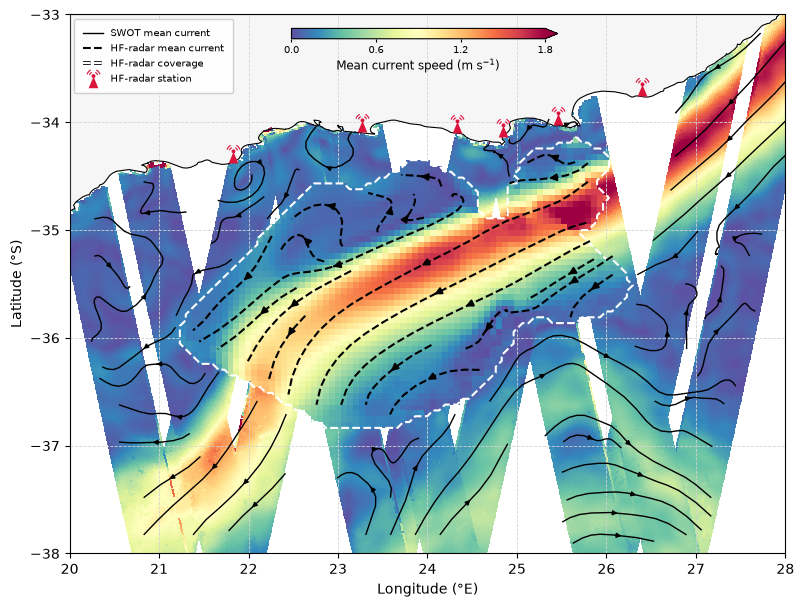

In [13]:
# Mean surface currents: figure style. Uses the variables produced by the data-prep cell
# above (swot_native_tracks, hf_mc_*, mean_current_land, *_streamlines); re-run this cell
# only to iterate on colours, widths and layout without repeating the data prep.
import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
from matplotlib.path import Path as MarkerPath
import numpy as np

MEAN_CURRENT_SPEED_LIMITS = (0.0, 1.8)  # m s-1
MEAN_CURRENT_CMAP = plt.get_cmap('Spectral_r')
SWOT_STREAMLINE_COLOUR = 'black'
HF_STREAMLINE_COLOUR = 'black'
SWOT_STREAMLINE_STYLE = '-'
HF_STREAMLINE_STYLE = '--'
SWOT_STREAMLINE_WIDTH = 1.0
HF_STREAMLINE_WIDTH = 1.5
HF_OUTLINE_WIDTH = 1.5
HF_OUTLINE_COLOUR = 'white'
# HF-radar sites: positions from the station_name/latitude_s/longitude_s variables in the
# raw HYDDOA files.
HF_RADAR_SITES = [
    # (site number, name, longitude, latitude)
    (1, 'EcoMarine', 21.8281, -34.3736),
    (2, 'Cairnbrogie', 23.2650, -34.0887),
    (3, 'Oudewerf', 24.3328, -34.1000),
    (4, 'Osbosch', 24.84851, -34.13207),
    (5, 'Bushy Park', 25.46102, -34.02765),
    (6, 'Woody Cape', 26.39658, -33.75679),
]
HF_SITE_COLOUR = 'black'
HF_SITE_LEGEND_MARKER_SIZE = 14


def make_antenna_marker(anchor_at_base=False):
    """Radio-mast symbol: filled triangular tower, round head and radio-wave arcs on each side.

    With anchor_at_base=True the bottom of the tower sits on the plotted point.
    """
    head_x, head_y = 0.0, 0.25
    pieces = [
        # Solid triangular tower.
        MarkerPath([(-0.5, -1.0), (0.5, -1.0), (0.0, 0.2), (-0.5, -1.0)], closed=True),
        MarkerPath.circle((head_x, head_y), 0.2),
    ]
    arc_half_width = 0.06
    for radius in (0.42, 0.68):
        for start_deg, end_deg in ((115, 165), (15, 65)):
            angles = np.deg2rad(np.linspace(start_deg, end_deg, 16))
            outer = np.column_stack((np.cos(angles), np.sin(angles))) * (radius + arc_half_width)
            inner = np.column_stack((np.cos(angles), np.sin(angles)))[::-1] * (radius - arc_half_width)
            ring = np.vstack((outer, inner, outer[:1])) + (head_x, head_y)
            pieces.append(MarkerPath(ring, closed=True))
    marker = MarkerPath.make_compound_path(*pieces)
    if anchor_at_base:
        marker = MarkerPath(marker.vertices + (0.0, 1.0), marker.codes)
    return marker


HF_SITE_MARKER = make_antenna_marker(anchor_at_base=True)
HF_SITE_LEGEND_MARKER = make_antenna_marker()
# Matplotlib scales a custom marker by its largest |vertex|. Anchoring the base at the
# origin enlarges that extent, so scale the map size to draw the icon at legend size.
HF_SITE_MARKER_SIZE = HF_SITE_LEGEND_MARKER_SIZE * (
    np.abs(HF_SITE_MARKER.vertices).max() / np.abs(HF_SITE_LEGEND_MARKER.vertices).max()
)

mean_current_figure, mean_current_axis = plt.subplots(figsize=(10, 7))
mean_current_land.plot(ax=mean_current_axis, color='gainsboro', alpha=0.25, zorder=3)
mean_current_land.boundary.plot(ax=mean_current_axis, color='black', linewidth=0.8, zorder=4)

speed_norm = plt.Normalize(vmin=MEAN_CURRENT_SPEED_LIMITS[0], vmax=MEAN_CURRENT_SPEED_LIMITS[1])
for track in swot_native_tracks:
    speed_mesh = mean_current_axis.pcolormesh(
        track['longitude'], track['latitude'], np.hypot(track['u'], track['v']),
        cmap=MEAN_CURRENT_CMAP, norm=speed_norm, shading='auto', zorder=1,
    )
mean_current_axis.pcolormesh(
    hf_mc_lon, hf_mc_lat, hf_mc_speed,
    cmap=MEAN_CURRENT_CMAP, norm=speed_norm, shading='auto', zorder=2,
)
# Outline the HF-radar coverage so the overlay boundary remains visible.
mean_current_axis.contour(
    hf_mc_lon, hf_mc_lat, np.isfinite(hf_mc_speed).astype(float),
    levels=[0.5], colors=HF_OUTLINE_COLOUR, linewidths=HF_OUTLINE_WIDTH, linestyles='--', zorder=2.5,
)

for (stream_lon, stream_lat, stream_u_mc, stream_v_mc), stream_colour, stream_style, stream_width, stream_arrow in (
    (swot_mc_streamlines, SWOT_STREAMLINE_COLOUR, SWOT_STREAMLINE_STYLE, SWOT_STREAMLINE_WIDTH, 0.7),
    (hf_mc_streamlines, HF_STREAMLINE_COLOUR, HF_STREAMLINE_STYLE, HF_STREAMLINE_WIDTH, 1.0),
):
    mean_current_streamplot = mean_current_axis.streamplot(
        stream_lon,
        stream_lat,
        np.ma.masked_invalid(stream_u_mc),
        np.ma.masked_invalid(stream_v_mc),
        color=stream_colour,
        linewidth=stream_width,
        density=1.0,
        arrowsize=stream_arrow,
        zorder=5,
    )
    mean_current_streamplot.lines.set_linestyle(stream_style)

for site_number, site_name, site_lon, site_lat in HF_RADAR_SITES:
    mean_current_axis.plot(
        site_lon,
        site_lat,
        marker=HF_SITE_MARKER,
        markersize=HF_SITE_MARKER_SIZE,
        color=HF_SITE_COLOUR,
        markeredgewidth=0,
        linestyle='none',
        zorder=6,
    )

def legend_line_edge(line_width):
    return [path_effects.Stroke(linewidth=line_width + 1.2, foreground='black'), path_effects.Normal()]

mean_current_axis.legend(
    handles=[
        plt.Line2D([], [], color=SWOT_STREAMLINE_COLOUR, linestyle=SWOT_STREAMLINE_STYLE, linewidth=SWOT_STREAMLINE_WIDTH, label='SWOT mean current'),
        plt.Line2D([], [], color=HF_STREAMLINE_COLOUR, linestyle=HF_STREAMLINE_STYLE, linewidth=HF_STREAMLINE_WIDTH, label='HF-radar mean current'),
        plt.Line2D([], [], color=HF_OUTLINE_COLOUR, linewidth=HF_OUTLINE_WIDTH, linestyle='--', label='HF-radar coverage', path_effects=legend_line_edge(HF_STREAMLINE_WIDTH)),
        plt.Line2D(
            [], [], marker=HF_SITE_LEGEND_MARKER, markersize=HF_SITE_LEGEND_MARKER_SIZE, color=HF_SITE_COLOUR,
            markeredgewidth=0, linestyle='none', label='HF-radar station',
        ),
    ],
    loc='upper left',
    fontsize=7,
    borderpad=0.9,
    framealpha=0.9,
)
mean_current_axis.set_xlim(map_lon_min, map_lon_max)
mean_current_axis.set_ylim(map_lat_min, map_lat_max)
#mean_current_axis.set_title('Mean surface current speed: SWOT (all overpasses, native grid) with HF-radar overlaid')
mean_current_axis.set_xlabel('Longitude (°E)')
mean_current_axis.set_ylabel('Latitude (°S)')
mean_current_axis.grid(color='lightgrey', linestyle='--', linewidth=0.6)
# Align the colourbar centre with the first legend label.
mean_current_figure.canvas.draw()
legend_label_box = mean_current_axis.get_legend().get_texts()[0].get_window_extent(
    mean_current_figure.canvas.get_renderer()
)
colourbar_centre_y = mean_current_axis.transAxes.inverted().transform(
    (legend_label_box.x0, (legend_label_box.y0 + legend_label_box.y1) / 2)
)[1]
speed_colourbar_axis = mean_current_axis.inset_axes([0.31, colourbar_centre_y - 0.0096, 0.372, 0.0192])
speed_colourbar = mean_current_figure.colorbar(
    speed_mesh,
    cax=speed_colourbar_axis,
    orientation='horizontal',
    ticks=np.linspace(*MEAN_CURRENT_SPEED_LIMITS, 4),
    extend='max',
)
speed_colourbar.set_label(r'Mean current speed (m s$^{-1}$)', fontsize=8.4, labelpad=2.4)
speed_colourbar.ax.tick_params(labelsize=7.2, length=2.4, pad=2.4)
plt.show()


Figure X. Mean surface current speed (colour) and flow direction from SWOT geostrophic currents (141 overpasses; solid black streamlines) and HF-radar surface currents (dashed black streamlines), November 2024–April 2026. HF-radar means are overlaid within the white dashed footprint, retaining cells with at least 50 valid snapshots. Black antenna symbols mark HF-radar stations.

Loading existing snapshot_count from <repo>/data/processed/hf_radar.zarr
Loading existing overpass_count from <repo>/data/processed/swot_filtered_velocity.zarr


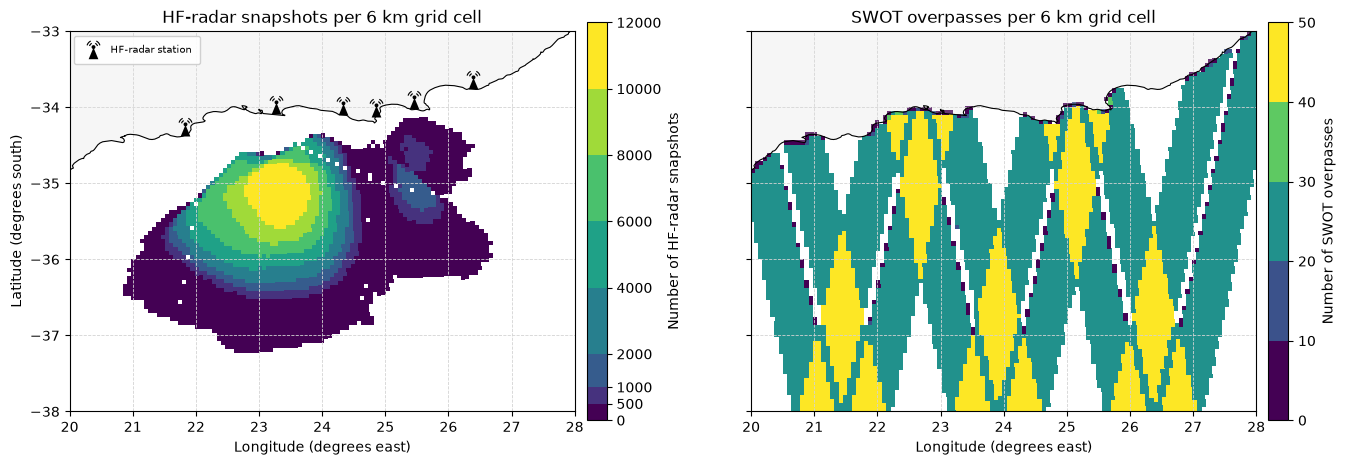

In [89]:
# Figure S1: count HF-radar snapshots and SWOT overpasses on the fixed 6 km grid.
from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
zarr_path = globals().get('zarr_path', repo_root / 'data/processed/hf_radar.zarr')
swot_out_zarr_path = globals().get(
    'swot_out_zarr_path',
    repo_root / 'data/processed/swot_filtered_velocity.zarr',
)
lon_min = globals().get('lon_min', 20.0)
lon_max = globals().get('lon_max', 28.0)
lat_min = globals().get('lat_min', -38.0)
lat_max = globals().get('lat_max', -33.0)

grid_spacing_m = 6_000
data_crs = ccrs.PlateCarree()
grid_crs = ccrs.UTM(zone=34, southern_hemisphere=True)

domain_lon = np.array([lon_min, lon_max, lon_max, lon_min])
domain_lat = np.array([lat_min, lat_min, lat_max, lat_max])
domain_xy = grid_crs.transform_points(data_crs, domain_lon, domain_lat)

x_edges = np.arange(
    np.floor(domain_xy[:, 0].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 0].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
y_edges = np.arange(
    np.floor(domain_xy[:, 1].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 1].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
n_x = len(x_edges) - 1
n_y = len(y_edges) - 1


def grid_cell_ids(longitude, latitude):
    longitude = np.asarray(longitude)
    latitude = np.asarray(latitude)
    if longitude.ndim == 1 and latitude.ndim == 1:
        longitude, latitude = np.meshgrid(longitude, latitude)
    else:
        longitude, latitude = np.broadcast_arrays(longitude, latitude)

    xy = grid_crs.transform_points(data_crs, longitude.ravel(), latitude.ravel())
    ix = np.digitize(xy[:, 0], x_edges) - 1
    iy = np.digitize(xy[:, 1], y_edges) - 1
    inside = (
        np.isfinite(xy[:, 0])
        & np.isfinite(xy[:, 1])
        & (ix >= 0)
        & (ix < n_x)
        & (iy >= 0)
        & (iy < n_y)
    )
    cell_ids = np.full(xy.shape[0], -1, dtype=int)
    cell_ids[inside] = iy[inside] * n_x + ix[inside]
    return cell_ids


hf_count_name = "snapshot_count"
swot_count_name = "overpass_count"
hf_count_archive = xr.open_zarr(zarr_path, consolidated=True)
swot_count_archive = xr.open_zarr(swot_out_zarr_path, consolidated=True)


def count_distinct_passes(u_velocity, v_velocity, cell_ids, label):
    """Count time steps containing one or more valid vectors per grid cell."""
    counts = np.zeros(n_x * n_y, dtype=np.int32)

    for time_index in range(u_velocity.sizes["time"]):
        u_slice = np.asarray(u_velocity.isel(time=time_index).values).ravel()
        v_slice = np.asarray(v_velocity.isel(time=time_index).values).ravel()
        current_cell_ids = cell_ids[time_index] if cell_ids.ndim > 1 else cell_ids
        valid_cells = current_cell_ids[
            np.isfinite(u_slice)
            & np.isfinite(v_slice)
            & (current_cell_ids >= 0)
        ]
        counts[np.unique(valid_cells)] += 1

        if (time_index + 1) % 500 == 0 or time_index + 1 == u_velocity.sizes["time"]:
            print(f"{label}: processed {time_index + 1}/{u_velocity.sizes['time']} time steps")

    return counts.reshape(n_y, n_x)


def save_fixed_grid_count(archive_path, variable_name, values, description):
    """Append a fixed-grid count variable to an existing Zarr archive."""
    count_ds = xr.Dataset(
        {
            variable_name: (("grid_y", "grid_x"), values.astype("int32")),
        },
        coords={
            "grid_y": np.arange(n_y),
            "grid_x": np.arange(n_x),
        },
    )
    count_ds[variable_name].attrs = {
        "long_name": description,
        "units": "count",
    }
    for variable in count_ds.variables:
        count_ds[variable].encoding = {}
    count_ds.to_zarr(
        archive_path,
        mode="a",
        consolidated=True,
        zarr_format=2,
    )


if hf_count_name in hf_count_archive.data_vars:
    print(f"Loading existing {hf_count_name} from {zarr_path}")
    hf_snapshot_count = hf_count_archive[hf_count_name].load().values
else:
    print(f"Calculating and adding {hf_count_name} to {zarr_path}")
    hf_cell_ids = grid_cell_ids(hf_count_archive.longitude.values, hf_count_archive.latitude.values)
    hf_snapshot_count = count_distinct_passes(
        hf_count_archive["ewct"],
        hf_count_archive["nsct"],
        hf_cell_ids,
        "HF-radar",
    )
    save_fixed_grid_count(
        zarr_path,
        hf_count_name,
        hf_snapshot_count,
        "number of HF-radar snapshots per fixed grid cell",
    )

if swot_count_name in swot_count_archive.data_vars:
    print(f"Loading existing {swot_count_name} from {swot_out_zarr_path}")
    swot_overpass_count = swot_count_archive[swot_count_name].load().values
else:
    print(f"Calculating and adding {swot_count_name} to {swot_out_zarr_path}")
    swot_cell_ids = np.stack(
        [
            grid_cell_ids(
                swot_count_archive.longitude.isel(time=time_index).compute().values,
                swot_count_archive.latitude.isel(time=time_index).compute().values,
            )
            for time_index in range(swot_count_archive.sizes["time"])
        ]
    )
    swot_overpass_count = count_distinct_passes(
        swot_count_archive["ugos_filtered"],
        swot_count_archive["vgos_filtered"],
        swot_cell_ids,
        "SWOT",
    )
    save_fixed_grid_count(
        swot_out_zarr_path,
        swot_count_name,
        swot_overpass_count,
        "number of SWOT overpasses per fixed grid cell",
    )

# Transform projected grid edges back to longitude/latitude for standard plotting axes.
grid_x, grid_y = np.meshgrid(x_edges, y_edges)
grid_lonlat = data_crs.transform_points(grid_crs, grid_x, grid_y)
grid_lon = grid_lonlat[..., 0]
grid_lat = grid_lonlat[..., 1]
land_path = repo_root / "data/raw/basemaps/ne_10m_land.zip"
land = gpd.read_file(land_path).clip(box(lon_min, lat_min, lon_max, lat_max))

figure, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
figure.subplots_adjust(left=0.08, right=0.94, bottom=0.12, top=0.90, wspace=0.12)

hf_boundaries = np.array([0, 500, 1_000, 2_000, 4_000, 6_000, 8_000, 10_000, 12_000])
hf_cmap = plt.get_cmap("viridis", len(hf_boundaries) - 1)
hf_norm = mcolors.BoundaryNorm(hf_boundaries, hf_cmap.N, clip=True)
swot_boundaries = np.arange(0, 51, 10)
swot_cmap = plt.get_cmap("viridis", len(swot_boundaries) - 1)
swot_norm = mcolors.BoundaryNorm(swot_boundaries, swot_cmap.N, clip=True)

for axis, counts, title, colourbar_label in zip(
    axes,
    (hf_snapshot_count, swot_overpass_count),
    ("HF-radar snapshots per 6 km grid cell", "SWOT overpasses per 6 km grid cell"),
    ("Number of HF-radar snapshots", "Number of SWOT overpasses"),
):
    land.plot(ax=axis, color="gainsboro", alpha=0.25, zorder=2)
    land.boundary.plot(ax=axis, color="black", linewidth=0.8, zorder=3)
    is_swot = title.startswith("SWOT")
    boundaries = swot_boundaries if is_swot else hf_boundaries
    cmap = swot_cmap if is_swot else hf_cmap
    norm = swot_norm if is_swot else hf_norm
    mesh = axis.pcolormesh(
        grid_lon,
        grid_lat,
        np.ma.masked_where(counts == 0, counts),
        shading="auto",
        cmap=cmap,
        norm=norm,
        zorder=1,
    )
    axis.set_xlim(lon_min, lon_max)
    axis.set_ylim(lat_min, lat_max)
    axis.set_title(title)
    axis.set_xlabel("Longitude (degrees east)")
    axis.grid(color="lightgrey", linestyle="--", linewidth=0.6)
    colourbar = figure.colorbar(
        mesh,
        ax=axis,
        shrink=0.85,
        pad=0.02,
        ticks=boundaries,
        boundaries=boundaries,
        spacing="proportional",
    )
    colourbar.set_label(colourbar_label)

for site_number, site_name, site_lon, site_lat in HF_RADAR_SITES:
    axes[0].plot(
        site_lon, site_lat,
        marker=HF_SITE_MARKER, markersize=HF_SITE_MARKER_SIZE,
        color=HF_SITE_COLOUR, markeredgewidth=0, linestyle='none', zorder=4,
    )
axes[0].legend(
    handles=[plt.Line2D(
        [], [], marker=HF_SITE_LEGEND_MARKER, markersize=HF_SITE_LEGEND_MARKER_SIZE,
        color=HF_SITE_COLOUR, markeredgewidth=0, linestyle='none', label='HF-radar station',
    )],
    loc='upper left', fontsize=7, borderpad=0.9, framealpha=0.9,
)
axes[0].set_ylabel("Latitude (degrees south)")
plt.show()

Figure S1: Spatial distribution of the number of valid HF-radar snapshots (left) and SWOT overpasses (right) containing at least one valid velocity vector within each 6 km × 6 km grid cell over the study domain (20–28°E, 33–38°S).

HF-radar stations listed for this snapshot: Cairnbrogie, EcoMarine, Oudwerf
SWOT overpass: Cycle 031, Pass 542
Requested granule filename time: 2025-04-26 11:59:01 UTC
SWOT footprint median time: 2025-04-26 12:35:12 UTC
HF-radar observation time: 2025-04-26 12:30:00 UTC
SWOT-HF-radar time gap: 0 days 00:05:12.560981696
Matched zarr index: 3


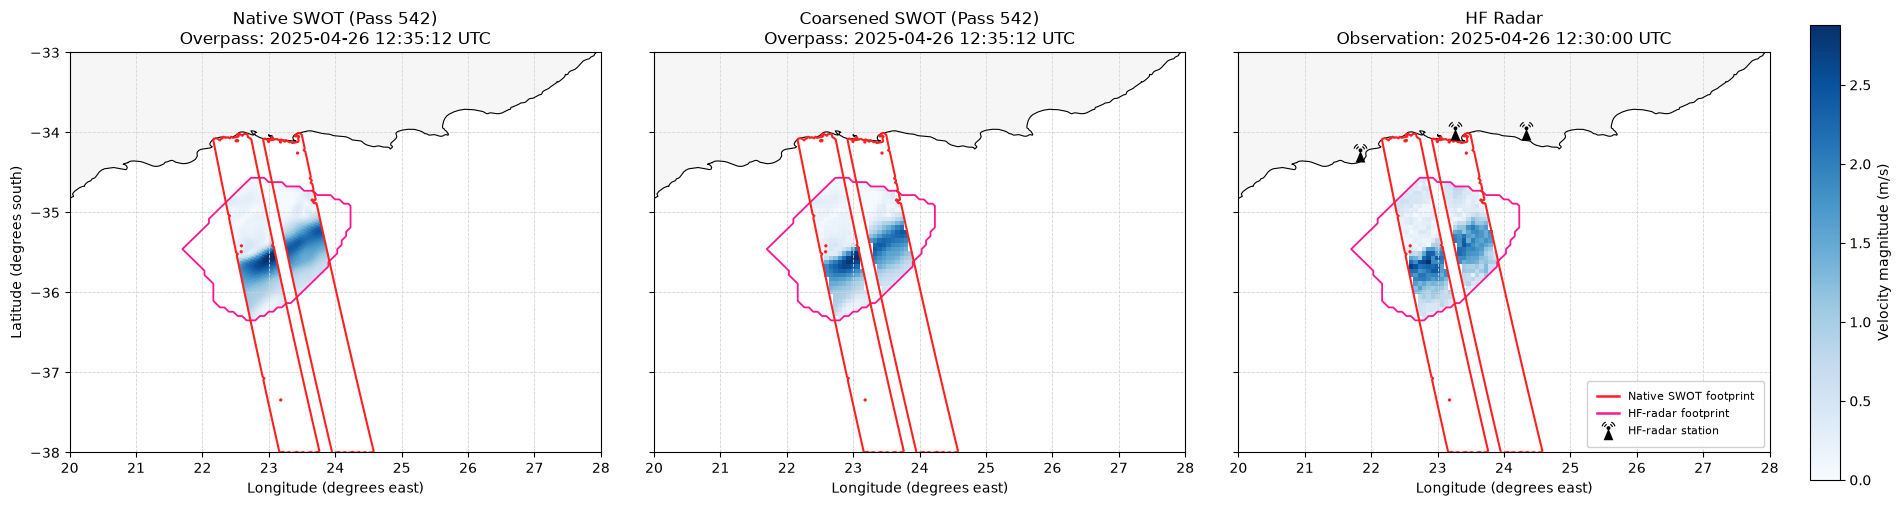

In [90]:
# Plot the requested SWOT overpass from the zarr-based matched archive.
from pathlib import Path
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import RegularGridInterpolator
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_filtered_zarr_path = globals().get(
    'swot_out_zarr_path',
    processed_dir / 'swot_filtered_velocity.zarr',
)
PLOT_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)

# The requested timestamp is from the granule filename; the archive stores
# the median measurement time where SWOT overlaps the HF-radar footprint.
target_cycle = 31
target_pass = 542
target_swot_time = pd.Timestamp('2025-04-26 11:59:01')
maximum_target_time_offset = pd.Timedelta(hours=1)

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')
if not swot_filtered_zarr_path.exists():
    raise FileNotFoundError(f'SWOT filtered zarr archive not found: {swot_filtered_zarr_path}. Run Cell 3 first.')

matched_ds = xr.open_zarr(matched_zarr_path, consolidated=True)
swot_times = pd.DatetimeIndex(pd.to_datetime(matched_ds['swot_time'].values))
nearest_index = int(np.argmin(np.abs(swot_times - target_swot_time)))
nearest_time = swot_times[nearest_index]
time_offset = abs(nearest_time - target_swot_time)
if time_offset > maximum_target_time_offset:
    raise ValueError(
        f'No matched SWOT overpass is within {maximum_target_time_offset} of the requested '
        f'filename time {target_swot_time}. Nearest stored representative time is {nearest_time} '
        f'({time_offset} away).'
    )

match_index = nearest_index
matched_record = matched_ds.isel(match=match_index)
source_swot_index = int(matched_record['source_swot_index'].values)
swot_footprint_time = pd.Timestamp(matched_record['swot_time'].values)
radar_observation_time = pd.Timestamp(matched_record['radar_time'].values)

radar_snapshot_path = (
    repo_root / 'data/raw/hf_radar'
    / radar_observation_time.strftime('%Y/%Y%m%d')
    / f'radar_sa_{radar_observation_time:%Y%m%d%H%M}_combined_hyddoa.nc'
)
with xr.open_dataset(radar_snapshot_path) as radar_snapshot:
    if pd.Timestamp(radar_snapshot['time'].values[0]) != radar_observation_time:
        raise ValueError(f'Raw HF-radar snapshot time does not match {radar_observation_time}.')
    snapshot_station_names = radar_snapshot['station_name'].values.astype(str).tolist()
    snapshot_station_lon = radar_snapshot['longitude_s'].values.copy()
    snapshot_station_lat = radar_snapshot['latitude_s'].values.copy()
print(f'HF-radar stations listed for this snapshot: {", ".join(snapshot_station_names)}')

with xr.open_zarr(swot_filtered_zarr_path, consolidated=True) as swot_ds:
    u_native = np.asarray(swot_ds['ugos_filtered'].isel(time=source_swot_index).values, dtype=float)
    v_native = np.asarray(swot_ds['vgos_filtered'].isel(time=source_swot_index).values, dtype=float)
    lon_native = np.asarray(swot_ds['longitude'].isel(time=source_swot_index).values, dtype=float)
    lat_native = np.asarray(swot_ds['latitude'].isel(time=source_swot_index).values, dtype=float)

radar_lon = np.asarray(matched_ds['longitude'].values, dtype=float)
radar_lat = np.asarray(matched_ds['latitude'].values, dtype=float)
speed_coarse = np.asarray(matched_record['swot_speed_coarsened_masked'].values, dtype=float)
speed_radar = np.asarray(matched_record['radar_speed_masked'].values, dtype=float)
radar_valid = np.asarray(matched_record['radar_valid_mask'].values, dtype=bool)

swot_valid = (
    np.isfinite(u_native)
    & np.isfinite(v_native)
    & np.isfinite(lon_native)
    & np.isfinite(lat_native)
    & (lon_native >= PLOT_BBOX[0])
    & (lon_native <= PLOT_BBOX[1])
    & (lat_native >= PLOT_BBOX[2])
    & (lat_native <= PLOT_BBOX[3])
)
radar_interp = RegularGridInterpolator(
    (radar_lat, radar_lon),
    radar_valid,
    method='nearest',
    bounds_error=False,
    fill_value=False,
)
native_points = np.column_stack((lat_native.ravel(), lon_native.ravel()))
swot_on_radar_footprint = np.asarray(
    radar_interp(native_points), dtype=bool,
).reshape(lat_native.shape)
native_swot_overlap_mask = swot_valid & swot_on_radar_footprint
speed_native = np.where(native_swot_overlap_mask, np.hypot(u_native, v_native), np.nan)

valid_speeds = np.concatenate([
    values[np.isfinite(values)]
    for values in (speed_native, speed_coarse, speed_radar)
    if np.isfinite(values).any()
])
colour_limit = float(np.nanpercentile(valid_speeds, 99.5)) if valid_speeds.size else 1.0
colour_limit = max(colour_limit, 1.0)

print(f'SWOT overpass: Cycle {target_cycle:03d}, Pass {target_pass:03d}')
print(f'Requested granule filename time: {target_swot_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'SWOT footprint median time: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'HF-radar observation time: {radar_observation_time:%Y-%m-%d %H:%M:%S} UTC')
print(f'SWOT-HF-radar time gap: {abs(radar_observation_time - swot_footprint_time)}')
print(f'Matched zarr index: {match_index}')

land_path = repo_root / 'data/raw/basemaps/ne_10m_land.zip'
land = gpd.read_file(land_path).clip(box(PLOT_BBOX[0], PLOT_BBOX[2], PLOT_BBOX[1], PLOT_BBOX[3]))

figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)

panel_data = [
    (
        speed_native,
        lon_native,
        lat_native,
        f'Native SWOT (Pass {target_pass})\nOverpass: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC',
    ),
    (
        speed_coarse,
        radar_lon,
        radar_lat,
        f'Coarsened SWOT (Pass {target_pass})\nOverpass: {swot_footprint_time:%Y-%m-%d %H:%M:%S} UTC',
    ),
    (
        speed_radar,
        radar_lon,
        radar_lat,
        f'HF Radar\nObservation: {radar_observation_time:%Y-%m-%d %H:%M:%S} UTC',
    ),
]

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='.*input coordinates to pcolormesh.*')
    for axis, (speed, longitude, latitude, title) in zip(axes, panel_data):
        land.plot(ax=axis, color='gainsboro', alpha=0.25, zorder=2)
        land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
        axis.pcolormesh(
            longitude,
            latitude,
            speed,
            cmap='Blues',
            vmin=0,
            vmax=colour_limit,
            shading='nearest',
            zorder=1,
        )
        axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
        axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
        axis.set_title(title)
        axis.set_xlabel('Longitude (degrees east)')
        axis.grid(color='lightgrey', linestyle='--', linewidth=0.6)

    for axis in axes:
        axis.contour(
            lon_native,
            lat_native,
            swot_valid.astype(float),
            levels=[0.5],
            colors='#ff2020',
            linewidths=1.5,
            zorder=5,
        )
        axis.contour(
            radar_lon,
            radar_lat,
            radar_valid.astype(float),
            levels=[0.5],
            colors='deeppink',
            linewidths=1.3,
            zorder=4,
        )

axes[0].set_ylabel('Latitude (degrees south)')

colourbar_axis = figure.add_axes([0.92, 0.15, 0.015, 0.7])
figure.colorbar(
    plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=0, vmax=colour_limit),
        cmap='Blues',
    ),
    cax=colourbar_axis,
    label='Velocity magnitude (m/s)',
)

legend_handles = [
    plt.Line2D([], [], color='#ff2020', linewidth=1.8, label='Native SWOT footprint'),
    plt.Line2D([], [], color='deeppink', linewidth=1.8, label='HF-radar footprint'),
    plt.Line2D(
        [], [], marker=HF_SITE_LEGEND_MARKER, markersize=HF_SITE_LEGEND_MARKER_SIZE,
        color=HF_SITE_COLOUR, markeredgewidth=0, linestyle='none', label='HF-radar station',
    ),
]
for site_lon, site_lat in zip(snapshot_station_lon, snapshot_station_lat):
    axes[2].plot(
        site_lon, site_lat,
        marker=HF_SITE_MARKER, markersize=HF_SITE_MARKER_SIZE,
        color=HF_SITE_COLOUR, markeredgewidth=0, linestyle='none', zorder=5,
    )
axes[2].legend(
    handles=legend_handles,
    loc='lower right',
    fontsize=8,
    borderpad=0.9,
    framealpha=0.9,
)

figure.subplots_adjust(
    left=0.05,
    right=0.90,
    bottom=0.12,
    top=0.88,
    wspace=0.10,
)
plt.show()

Figure S2. Velocity-magnitude comparison for SWOT cycle 31, pass 542. The native SWOT and coarsened SWOT panels show the SWOT overpass at the median time of the valid observations crossing the HF-radar footprint (26 April 2025, 12:35:03 UTC). The HF-radar panel shows the matched observation at 12:30:00 UTC, giving an absolute time difference of 5 min 12 s. Red and pink outlines indicate the native SWOT and HF-radar footprints, respectively.

In [63]:
# Table S1: matched SWOT-HF-radar observations from the zarr-based comparison archive.
from pathlib import Path
import re

import numpy as np
import pandas as pd
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_raw_dir = repo_root / 'data' / 'raw' / 'swot_l3_expert'
maximum_filename_time_offset = pd.Timedelta(hours=1)

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')

filename_pattern = re.compile(
    r'SWOT_L3_LR_SSH_Expert_(\d{3})_(\d{3})_(\d{8}T\d{6})_'
)
swot_file_metadata = {}
for swot_file in sorted(swot_raw_dir.glob('SWOT_L3_LR_SSH_Expert_*.nc')):
    match = filename_pattern.search(swot_file.name)
    if match is None:
        continue
    swot_time = pd.to_datetime(match.group(3), format='%Y%m%dT%H%M%S')
    swot_file_metadata.setdefault(
        swot_time,
        {
            'Cycle': int(match.group(1)),
            'Pass': int(match.group(2)),
        },
    )
swot_filename_times = pd.DatetimeIndex(sorted(swot_file_metadata))

with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    rows = []
    for match_index in range(matched_ds.sizes['match']):
        record = matched_ds.isel(match=match_index)
        swot_time = pd.Timestamp(record['swot_time'].values)
        radar_time = pd.Timestamp(record['radar_time'].values)
        filename_index = int(np.argmin(np.abs(swot_filename_times - swot_time)))
        filename_time = swot_filename_times[filename_index]
        if abs(filename_time - swot_time) <= maximum_filename_time_offset:
            metadata = swot_file_metadata[filename_time]
        else:
            metadata = {}
        comparison_mask = np.asarray(record['comparison_mask'].values, dtype=bool)

        rows.append(
            {
                'Match': match_index + 1,
                'Cycle': metadata.get('Cycle', pd.NA),
                'Pass': metadata.get('Pass', pd.NA),
                'SWOT time (UTC)': swot_time.strftime('%Y-%m-%d %H:%M:%S'),
                'HF-radar time (UTC)': radar_time.strftime('%Y-%m-%d %H:%M:%S'),
                'Time gap (min, sec)': float(record['time_gap_seconds'].values) / 60,
                'Paired cells': int(comparison_mask.sum()),
                'Native SWOT overlap pixels': int(record['native_swot_overlap_pixels'].values),
            }
        )

matched_observation_table = pd.DataFrame(rows)
matched_observation_table = matched_observation_table.sort_values(
    ['SWOT time (UTC)', 'Cycle', 'Pass'],
    na_position='last',
).reset_index(drop=True)
matched_observation_table['Match'] = np.arange(1, len(matched_observation_table) + 1)

mean_gap_total_seconds = int(round(matched_observation_table['Time gap (min, sec)'].mean() * 60))
mean_gap_minutes, mean_gap_seconds = divmod(mean_gap_total_seconds, 60)
print(f'Matches: {len(matched_observation_table):,}')
print(f'Mean time gap: {mean_gap_minutes}\' {mean_gap_seconds:02d}"')
print(f'Total paired cells: {matched_observation_table["Paired cells"].sum():,}')
print(
    'Total native SWOT overlap pixels: '
    f'{matched_observation_table["Native SWOT overlap pixels"].sum():,}'
)


def format_time_gap(minutes):
    total_seconds = int(round(float(minutes) * 60))
    whole_minutes, seconds = divmod(total_seconds, 60)
    return f'{whole_minutes}\' {seconds:02d}"'


styled_matched_observation_table = matched_observation_table.style.format(
    {
        'Time gap (min, sec)': format_time_gap,
    }
)
styled_matched_observation_table

Matches: 35
Mean time gap: 7' 17"
Total paired cells: 6,416
Total native SWOT overlap pixels: 61,609


,Match,Cycle,Pass,SWOT time (UTC),HF-radar time (UTC),"Time gap (min, sec)",Paired cells,Native SWOT overlap pixels
0,1,23,555,2024-11-11 01:22:32,2024-11-11 01:30:00,"7' 28""",236,2262
1,2,29,514,2025-03-14 19:04:20,2025-03-14 19:00:00,"4' 21""",4,45
2,3,29,527,2025-03-15 05:52:29,2025-03-15 06:00:00,"7' 31""",85,828
3,4,31,542,2025-04-26 12:35:12,2025-04-26 12:30:00,"5' 13""",427,4105
4,5,31,555,2025-04-26 23:23:08,2025-04-26 23:30:00,"6' 51""",162,1564
5,6,33,514,2025-06-06 06:04:40,2025-06-06 06:00:00,"4' 40""",1,9
6,7,33,542,2025-06-07 06:05:21,2025-06-07 06:00:00,"5' 22""",361,3463
7,8,33,555,2025-06-07 16:53:18,2025-06-07 17:00:00,"6' 42""",136,1336
8,9,35,527,2025-07-18 10:22:59,2025-07-18 10:30:00,"7' 00""",17,180
9,10,35,542,2025-07-18 23:35:33,2025-07-18 23:30:00,"5' 33""",242,2343


Table S1. Matched SWOT-HF-radar observations. SWOT time is the median time of valid SWOT data crossing the HF-radar footprint. Paired cells are valid coarsened-SWOT/HF-radar grid-cell comparisons.

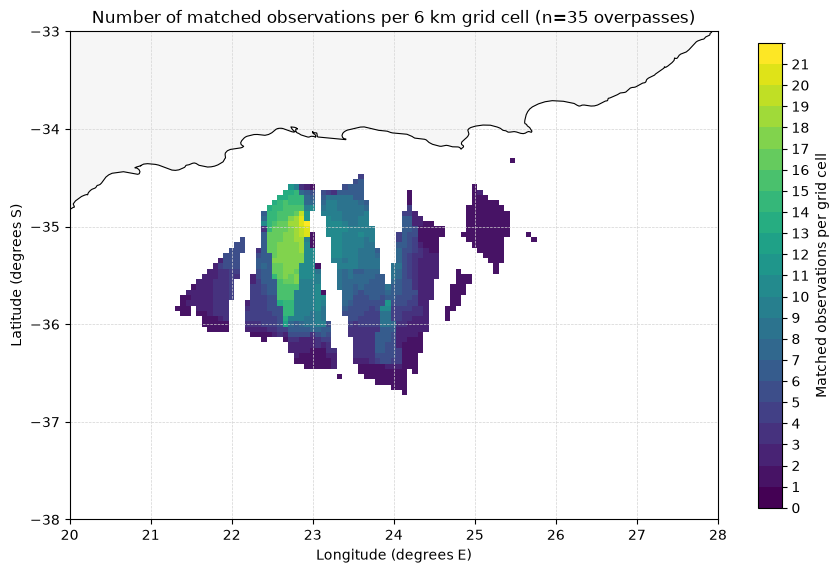

Overpasses included: 35
Grid shape: 75 lat x 150 lon (6 km resolution)
Grid cells with at least 1 matched observation: 1,128
Maximum matched observations in a single cell: 21


In [65]:
# Count matched SWOT-HF-radar observations per 6 km grid cell across all zarr-matched overpasses.
from pathlib import Path

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
PLOT_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')


def centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    grid_latitude = np.asarray(matched_ds['latitude'].values, dtype=float)
    grid_longitude = np.asarray(matched_ds['longitude'].values, dtype=float)
    swot_speed = np.asarray(matched_ds['swot_speed_coarsened_masked'].values, dtype=float)
    radar_speed = np.asarray(matched_ds['radar_speed_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)
    number_of_overpasses = matched_ds.sizes['match']

paired_valid = comparison_mask & np.isfinite(swot_speed) & np.isfinite(radar_speed)
matched_observation_count = paired_valid.sum(axis=0).astype(int)
maximum_matched_observations = int(matched_observation_count.max())
count_plot = np.where(matched_observation_count > 0, matched_observation_count, np.nan)
count_lat_edges = centre_edges(grid_latitude)
count_lon_edges = centre_edges(grid_longitude)

count_levels = np.arange(0, maximum_matched_observations + 2)
count_cmap = plt.get_cmap('viridis', max(len(count_levels) - 1, 1))
count_norm = mcolors.BoundaryNorm(count_levels, count_cmap.N)

land_path = repo_root / 'data/raw/basemaps/ne_10m_land.zip'
land = gpd.read_file(land_path).clip(box(PLOT_BBOX[0], PLOT_BBOX[2], PLOT_BBOX[1], PLOT_BBOX[3]))

figure, axis = plt.subplots(figsize=(9, 6))
land.plot(ax=axis, color='gainsboro', alpha=0.25, zorder=2)
land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
mesh = axis.pcolormesh(
    count_lon_edges,
    count_lat_edges,
    count_plot,
    cmap=count_cmap,
    norm=count_norm,
    zorder=1,
)
axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
axis.set_title(
    f'Number of matched observations per 6 km grid cell (n={number_of_overpasses} overpasses)'
)
axis.set_xlabel('Longitude (degrees E)')
axis.set_ylabel('Latitude (degrees S)')
axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
figure.colorbar(
    mesh,
    ax=axis,
    ticks=np.arange(0, maximum_matched_observations + 1),
    label='Matched observations per grid cell',
    shrink=0.85,
)
figure.tight_layout()
plt.show()

print(f'Overpasses included: {number_of_overpasses}')
print(f'Grid shape: {grid_latitude.size} lat x {grid_longitude.size} lon (6 km resolution)')
print(f'Grid cells with at least 1 matched observation: {(matched_observation_count > 0).sum():,}')
print(f'Maximum matched observations in a single cell: {maximum_matched_observations}')

Figure S3. Spatial distribution of matched SWOT–HF-radar observations on the 6 km HF-radar grid. Each count represents one grid-cell comparison from one of the 35 matched overpasses. A total of 1,128 grid cells contain at least one matched observation, with a maximum of 20 observations per grid cell.

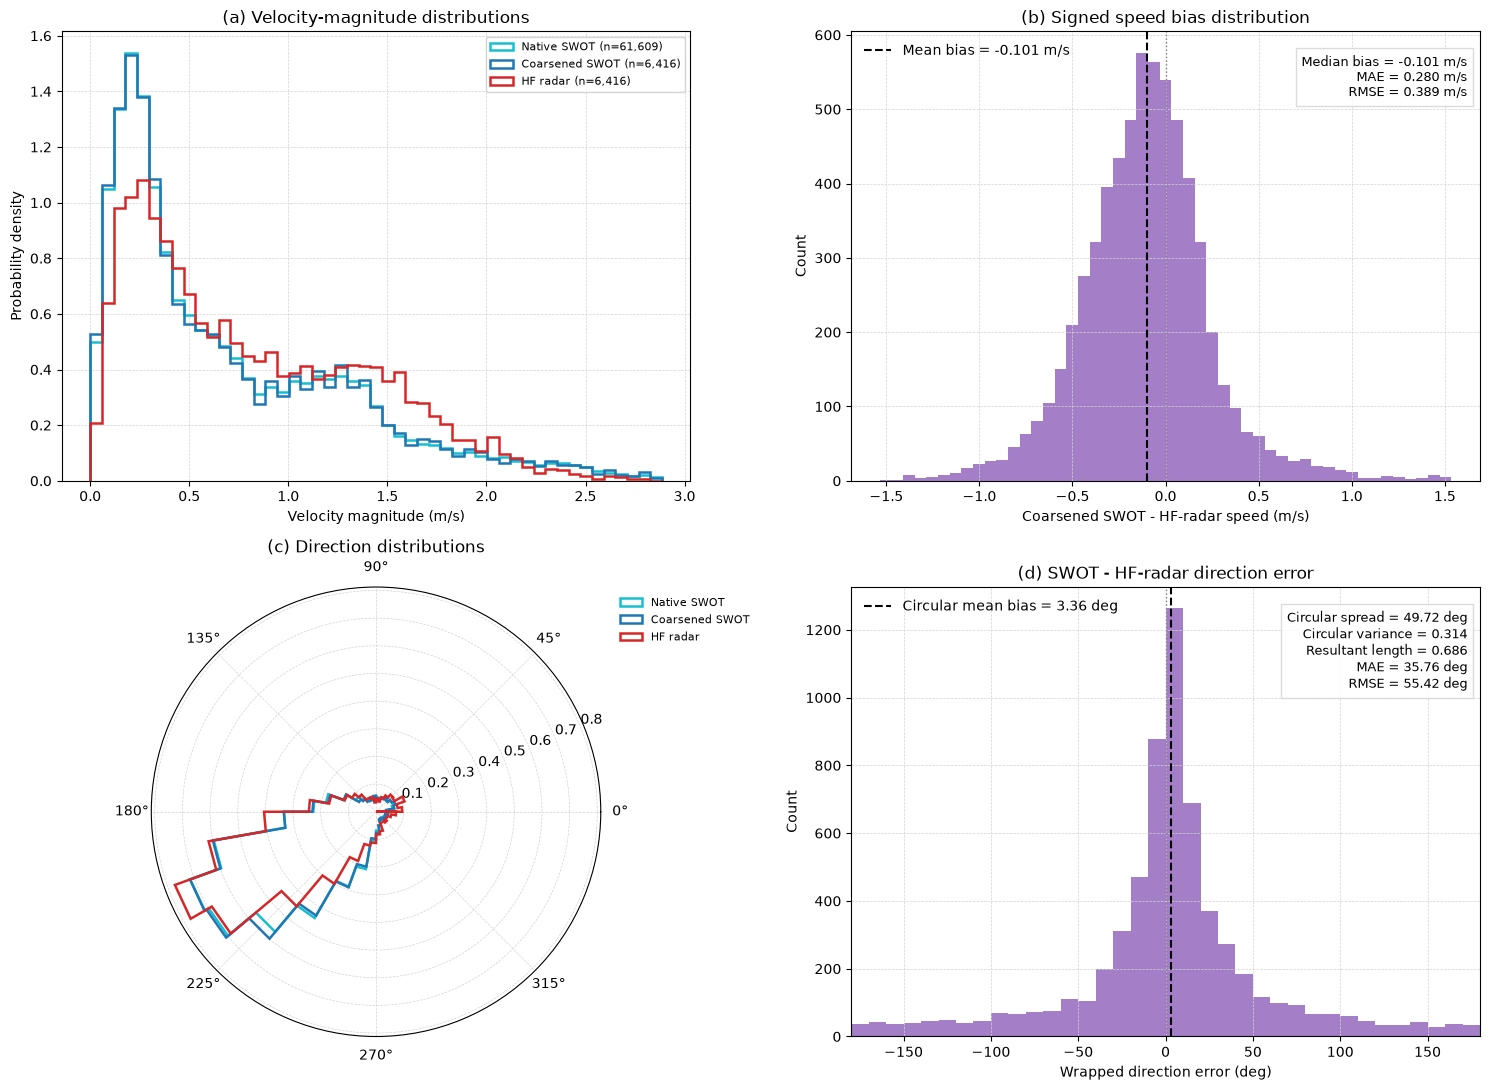

Native SWOT masked pixels: 61,609
Paired coarsened-SWOT/HF-radar speed comparisons: 6,416
Paired direction comparisons: 6,227
Mean speed bias: -0.1013 m/s
Speed RMSE: 0.3895 m/s
Circular direction mean bias: 3.36 deg
Direction RMSE: 55.42 deg


In [66]:
# Velocity and direction comparisons from the zarr-based matched archive.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import RegularGridInterpolator
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_filtered_zarr_path = globals().get(
    'swot_out_zarr_path',
    processed_dir / 'swot_filtered_velocity.zarr',
)
PLOT_BBOX = (
    globals().get('lon_min', 20.0),
    globals().get('lon_max', 28.0),
    globals().get('lat_min', -38.0),
    globals().get('lat_max', -33.0),
)
MIN_DIRECTION_SPEED = 0.05

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')
if not swot_filtered_zarr_path.exists():
    raise FileNotFoundError(f'SWOT filtered zarr archive not found: {swot_filtered_zarr_path}. Run Cell 3 first.')


def direction_components(u_component, v_component):
    speed = np.hypot(u_component, v_component)
    direction = (np.degrees(np.arctan2(v_component, u_component)) + 360.0) % 360.0
    return speed, direction


def wrapped_direction_error(model_direction, reference_direction):
    return ((model_direction - reference_direction + 180.0) % 360.0) - 180.0


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    radar_lon = np.asarray(matched_ds['longitude'].values, dtype=float)
    radar_lat = np.asarray(matched_ds['latitude'].values, dtype=float)
    source_swot_indices = np.asarray(matched_ds['source_swot_index'].values, dtype=int)
    coarse_u = np.asarray(matched_ds['ugos_coarsened_masked'].values, dtype=float)
    coarse_v = np.asarray(matched_ds['vgos_coarsened_masked'].values, dtype=float)
    radar_u = np.asarray(matched_ds['ewct_masked'].values, dtype=float)
    radar_v = np.asarray(matched_ds['nsct_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)
    radar_valid_masks = np.asarray(matched_ds['radar_valid_mask'].values, dtype=bool)

coarse_speed, coarse_direction = direction_components(coarse_u, coarse_v)
radar_speed, radar_direction = direction_components(radar_u, radar_v)
paired_valid = (
    comparison_mask
    & np.isfinite(coarse_u)
    & np.isfinite(coarse_v)
    & np.isfinite(radar_u)
    & np.isfinite(radar_v)
)

coarse_paired_values = coarse_speed[paired_valid]
radar_paired_values = radar_speed[paired_valid]
speed_diff_values = coarse_paired_values - radar_paired_values
speed_bias = float(np.mean(speed_diff_values))
speed_rmse = float(np.sqrt(np.mean(speed_diff_values ** 2)))
speed_median_bias = float(np.median(speed_diff_values))
speed_mae = float(np.mean(np.abs(speed_diff_values)))

paired_direction_valid = paired_valid & (coarse_speed >= MIN_DIRECTION_SPEED) & (radar_speed >= MIN_DIRECTION_SPEED)
coarse_direction_paired = coarse_direction[paired_direction_valid]
radar_direction_paired = radar_direction[paired_direction_valid]
direction_error_values = wrapped_direction_error(coarse_direction_paired, radar_direction_paired)
absolute_direction_error = np.abs(direction_error_values)

error_radians = np.radians(direction_error_values)
mean_sine = np.mean(np.sin(error_radians))
mean_cosine = np.mean(np.cos(error_radians))
resultant_length = float(np.hypot(mean_sine, mean_cosine))
circular_mean_bias = float(np.degrees(np.arctan2(mean_sine, mean_cosine)))
circular_spread = (
    float(np.degrees(np.sqrt(-2.0 * np.log(resultant_length))))
    if resultant_length > 0
    else np.nan
)
circular_variance = 1.0 - resultant_length
directional_mae = float(np.mean(absolute_direction_error))
directional_rmse = float(np.sqrt(np.mean(direction_error_values ** 2)))

native_speed_values = []
native_direction_values = []
with xr.open_zarr(swot_filtered_zarr_path, consolidated=True) as swot_ds:
    for match_index, source_swot_index in enumerate(source_swot_indices):
        u_native = np.asarray(swot_ds['ugos_filtered'].isel(time=source_swot_index).values, dtype=float)
        v_native = np.asarray(swot_ds['vgos_filtered'].isel(time=source_swot_index).values, dtype=float)
        lon_native = np.asarray(swot_ds['longitude'].isel(time=source_swot_index).values, dtype=float)
        lat_native = np.asarray(swot_ds['latitude'].isel(time=source_swot_index).values, dtype=float)
        swot_valid = (
            np.isfinite(u_native)
            & np.isfinite(v_native)
            & np.isfinite(lon_native)
            & np.isfinite(lat_native)
            & (lon_native >= PLOT_BBOX[0])
            & (lon_native <= PLOT_BBOX[1])
            & (lat_native >= PLOT_BBOX[2])
            & (lat_native <= PLOT_BBOX[3])
)
        radar_interp = RegularGridInterpolator(
            (radar_lat, radar_lon),
            radar_valid_masks[match_index],
            method='nearest',
            bounds_error=False,
            fill_value=False,
        )
        native_points = np.column_stack((lat_native.ravel(), lon_native.ravel()))
        native_on_radar_footprint = np.asarray(radar_interp(native_points), dtype=bool).reshape(lat_native.shape)
        native_overlap = swot_valid & native_on_radar_footprint
        native_speed, native_direction = direction_components(u_native, v_native)
        native_direction_valid = native_overlap & (native_speed >= MIN_DIRECTION_SPEED)
        native_speed_values.append(native_speed[native_overlap])
        native_direction_values.append(native_direction[native_direction_valid])

native_speed_values = np.concatenate(native_speed_values)
native_speed_values = native_speed_values[np.isfinite(native_speed_values)]
native_direction_values = np.concatenate(native_direction_values)

histogram_speed_limit = float(np.nanpercentile(
    np.concatenate((native_speed_values, coarse_paired_values, radar_paired_values)),
    99.5,
))
histogram_speed_bins = np.linspace(0, histogram_speed_limit, 50)
bias_limit = float(np.nanpercentile(np.abs(speed_diff_values), 99.5))
bias_bins = np.linspace(-bias_limit, bias_limit, 50)
direction_bin_edges = np.linspace(0.0, 360.0, 37)
direction_error_bins = np.linspace(-180.0, 180.0, 37)

figure = plt.figure(figsize=(15, 11))
speed_axis = figure.add_subplot(2, 2, 1)
bias_axis = figure.add_subplot(2, 2, 2)
polar_axis = figure.add_subplot(2, 2, 3, projection='polar')
direction_error_axis = figure.add_subplot(2, 2, 4)

speed_axis.hist(native_speed_values, bins=histogram_speed_bins, histtype='step', linewidth=1.8, density=True, label=f'Native SWOT (n={native_speed_values.size:,})', color='#17becf')
speed_axis.hist(coarse_paired_values, bins=histogram_speed_bins, histtype='step', linewidth=1.8, density=True, label=f'Coarsened SWOT (n={coarse_paired_values.size:,})', color='#1f77b4')
speed_axis.hist(radar_paired_values, bins=histogram_speed_bins, histtype='step', linewidth=1.8, density=True, label=f'HF radar (n={radar_paired_values.size:,})', color='#d62728')
speed_axis.set_xlabel('Velocity magnitude (m/s)')
speed_axis.set_ylabel('Probability density')
speed_axis.set_title('(a) Velocity-magnitude distributions')
speed_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
speed_axis.legend(fontsize=8)

bias_axis.hist(speed_diff_values, bins=bias_bins, color='#9467bd', alpha=0.85)
bias_axis.axvline(speed_bias, color='black', linestyle='--', linewidth=1.5, label=f'Mean bias = {speed_bias:.3f} m/s')
bias_axis.axvline(0, color='grey', linestyle=':', linewidth=1)
bias_axis.text(
    0.98,
    0.95,
    f'Median bias = {speed_median_bias:.3f} m/s\nMAE = {speed_mae:.3f} m/s\nRMSE = {speed_rmse:.3f} m/s',
    transform=bias_axis.transAxes,
    ha='right',
    va='top',
    fontsize=9,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgrey'),
)
bias_axis.set_xlabel('Coarsened SWOT - HF-radar speed (m/s)')
bias_axis.set_ylabel('Count')
bias_axis.set_title('(b) Signed speed bias distribution')
bias_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
bias_axis.legend(frameon=False)

for label, direction, colour in (
    ('Native SWOT', native_direction_values, '#17becf'),
    ('Coarsened SWOT', coarse_direction_paired, '#1f77b4'),
    ('HF radar', radar_direction_paired, '#d62728'),
):
    polar_axis.hist(np.radians(direction), bins=np.radians(direction_bin_edges), histtype='step', density=True, linewidth=1.8, color=colour, label=label)
polar_axis.set_theta_zero_location('E')
polar_axis.set_theta_direction(1)
polar_axis.set_title('(c) Direction distributions')
polar_axis.set_ylabel('')
polar_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
polar_axis.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False)

direction_error_axis.hist(direction_error_values, bins=direction_error_bins, color='#9467bd', alpha=0.85, edgecolor='none', linewidth=0)
direction_error_axis.axvline(circular_mean_bias, color='black', linestyle='--', linewidth=1.5, label=f'Circular mean bias = {circular_mean_bias:.2f} deg')
direction_error_axis.axvline(0, color='grey', linestyle=':', linewidth=1)
direction_error_axis.text(
    0.98,
    0.95,
    f'Circular spread = {circular_spread:.2f} deg\n'
    f'Circular variance = {circular_variance:.3f}\n'
    f'Resultant length = {resultant_length:.3f}\n'
    f'MAE = {directional_mae:.2f} deg\n'
    f'RMSE = {directional_rmse:.2f} deg',
    transform=direction_error_axis.transAxes,
    ha='right',
    va='top',
    fontsize=9,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgrey'),
)
direction_error_axis.set_xlim(-180, 180)
direction_error_axis.set_title('(d) SWOT - HF-radar direction error')
direction_error_axis.set_xlabel('Wrapped direction error (deg)')
direction_error_axis.set_ylabel('Count')
direction_error_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
direction_error_axis.legend(frameon=False)

figure.tight_layout()
plt.show()

print(f'Native SWOT masked pixels: {native_speed_values.size:,}')
print(f'Paired coarsened-SWOT/HF-radar speed comparisons: {speed_diff_values.size:,}')
print(f'Paired direction comparisons: {direction_error_values.size:,}')
print(f'Mean speed bias: {speed_bias:.4f} m/s')
print(f'Speed RMSE: {speed_rmse:.4f} m/s')
print(f'Circular direction mean bias: {circular_mean_bias:.2f} deg')
print(f'Direction RMSE: {directional_rmse:.2f} deg')

Figure 1. Velocity-magnitude and directional comparison between SWOT-derived and HF-radar surface currents. Velocity distributions for native SWOT, coarsened SWOT, and HF radar are shown alongside the signed speed difference (SWOT minus HF radar). Direction distributions and wrapped directional differences are shown for paired vectors with speeds ≥ 0.05 m s⁻¹, with the dashed line indicating the circular mean directional bias. Statistics were calculated from paired 6 km grid-cell observations across the matched SWOT overpasses. Positive speed differences indicate higher SWOT speeds. Circular spread, variance, resultant length, bias, MAE, and RMSE are reported where applicable.

In [99]:
# Bootstrap summary table for key SWOT-HF-radar validation metrics.
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
matched_zarr_path = repo_root / 'data' / 'processed' / 'swot_hfradar_zarr_matches.zarr'
BOOTSTRAP_REPLICATES = 5000
RANDOM_SEED = 42
MIN_DIRECTION_SPEED = 0.05

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')


def direction_components(u_component, v_component):
    speed = np.hypot(u_component, v_component)
    direction = (np.degrees(np.arctan2(v_component, u_component)) + 360.0) % 360.0
    return speed, direction


def wrapped_direction_error(model_direction, reference_direction):
    return ((model_direction - reference_direction + 180.0) % 360.0) - 180.0


def circular_mean_degrees(errors):
    error_radians = np.radians(errors)
    return float(np.degrees(np.arctan2(
        np.mean(np.sin(error_radians)),
        np.mean(np.cos(error_radians)),
    )))


def pooled_metric_values(records):
    speed_errors = np.concatenate([record['speed_error'] for record in records])
    direction_errors = np.concatenate([record['direction_error'] for record in records])
    return {
        'velocity_bias': float(np.mean(speed_errors)),
        'velocity_rmse': float(np.sqrt(np.mean(speed_errors ** 2))),
        'velocity_mae': float(np.mean(np.abs(speed_errors))),
        'direction_bias': circular_mean_degrees(direction_errors),
        'direction_rmse': float(np.sqrt(np.mean(direction_errors ** 2))),
        'direction_mae': float(np.mean(np.abs(direction_errors))),
    }


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    coarse_u = np.asarray(matched_ds['ugos_coarsened_masked'].values, dtype=float)
    coarse_v = np.asarray(matched_ds['vgos_coarsened_masked'].values, dtype=float)
    radar_u = np.asarray(matched_ds['ewct_masked'].values, dtype=float)
    radar_v = np.asarray(matched_ds['nsct_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)
    corrections = {
        component: (
            np.asarray(matched_ds[f'{component}_u_masked'].values, dtype=float),
            np.asarray(matched_ds[f'{component}_v_masked'].values, dtype=float),
        )
        for component in ('tide', 'ekman', 'stokes')
    }

# Use the same common sample as the radar-variant table: pairs must be valid for
# every HF-radar variant, and direction requires all variants to exceed the threshold.
radar_variants = [
    (radar_u, radar_v),
    *[(radar_u - cu, radar_v - cv) for cu, cv in corrections.values()],
    (
        radar_u - sum(values[0] for values in corrections.values()),
        radar_v - sum(values[1] for values in corrections.values()),
    ),
]
variants_finite = np.ones_like(comparison_mask, dtype=bool)
variants_above_threshold = np.ones_like(comparison_mask, dtype=bool)
for variant_u, variant_v in radar_variants:
    variants_finite &= np.isfinite(variant_u) & np.isfinite(variant_v)
    variants_above_threshold &= np.hypot(variant_u, variant_v) >= MIN_DIRECTION_SPEED

coarse_speed, coarse_direction = direction_components(coarse_u, coarse_v)
radar_speed, radar_direction = direction_components(radar_u, radar_v)

overpass_records = []
for match_index in range(coarse_speed.shape[0]):
    speed_valid = (
        comparison_mask[match_index]
        & variants_finite[match_index]
        & np.isfinite(coarse_speed[match_index])
        & np.isfinite(radar_speed[match_index])
    )
    direction_valid = (
        speed_valid
        & (coarse_speed[match_index] >= MIN_DIRECTION_SPEED)
        & variants_above_threshold[match_index]
        & np.isfinite(coarse_direction[match_index])
        & np.isfinite(radar_direction[match_index])
    )
    if not speed_valid.any():
        continue

    overpass_records.append(
        {
            'speed_error': coarse_speed[match_index][speed_valid] - radar_speed[match_index][speed_valid],
            'direction_error': wrapped_direction_error(
                coarse_direction[match_index][direction_valid],
                radar_direction[match_index][direction_valid],
            ),
        }
    )

if not overpass_records:
    raise ValueError('No valid matched overpass records were available for bootstrapping.')

pooled_estimate = pooled_metric_values(overpass_records)
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_indices = rng.integers(
    0,
    len(overpass_records),
    size=(BOOTSTRAP_REPLICATES, len(overpass_records)),
)
bootstrap_values = {metric: np.empty(BOOTSTRAP_REPLICATES) for metric in pooled_estimate}

for replicate_index, sampled_indices in enumerate(bootstrap_indices):
    sampled_records = [overpass_records[index] for index in sampled_indices]
    replicate_metrics = pooled_metric_values(sampled_records)
    for metric_name, value in replicate_metrics.items():
        bootstrap_values[metric_name][replicate_index] = value


def interval_text(metric_name, unit):
    lower, upper = np.percentile(bootstrap_values[metric_name], [2.5, 97.5])
    if unit == 'm/s':
        return f'{lower:.3f} to {upper:.3f}'
    return f'{lower:.1f} deg to {upper:.1f} deg'


def estimate_text(metric_name, unit):
    estimate = pooled_estimate[metric_name]
    if unit == 'm/s':
        return f'{estimate:.3f} m/s'
    return f'{estimate:.1f} deg'


summary_rows = [
    {
        'Metric': 'BIAS',
        'Velocity estimate': estimate_text('velocity_bias', 'm/s'),
        'Velocity 95% interval': interval_text('velocity_bias', 'm/s'),
        'Direction estimate': estimate_text('direction_bias', 'deg'),
        'Direction 95% interval': interval_text('direction_bias', 'deg'),
    },
    {
        'Metric': 'RMSE',
        'Velocity estimate': estimate_text('velocity_rmse', 'm/s'),
        'Velocity 95% interval': interval_text('velocity_rmse', 'm/s'),
        'Direction estimate': estimate_text('direction_rmse', 'deg'),
        'Direction 95% interval': interval_text('direction_rmse', 'deg'),
    },
    {
        'Metric': 'MAE',
        'Velocity estimate': estimate_text('velocity_mae', 'm/s'),
        'Velocity 95% interval': interval_text('velocity_mae', 'm/s'),
        'Direction estimate': estimate_text('direction_mae', 'deg'),
        'Direction 95% interval': interval_text('direction_mae', 'deg'),
    },
]

bootstrap_key_metric_table = pd.DataFrame(summary_rows)
bootstrap_key_metric_table

,Metric,Velocity estimate,Velocity 95% interval,Direction estimate,Direction 95% interval
0,BIAS,-0.101 m/s,-0.152 to -0.054,3.5 deg,-0.2 deg to 7.2 deg
1,RMSE,0.389 m/s,0.345 to 0.441,53.8 deg,47.8 deg to 59.8 deg
2,MAE,0.280 m/s,0.252 to 0.310,34.5 deg,29.7 deg to 39.4 deg


Table 1. Summary statistics for the comparison between coarsened SWOT and HF-radar currents. Estimates are calculated from paired 6 km grid-cell observations across the 36 matched SWOT overpasses. Bootstrap 95% confidence intervals were obtained using overpass-level resampling with replacement.

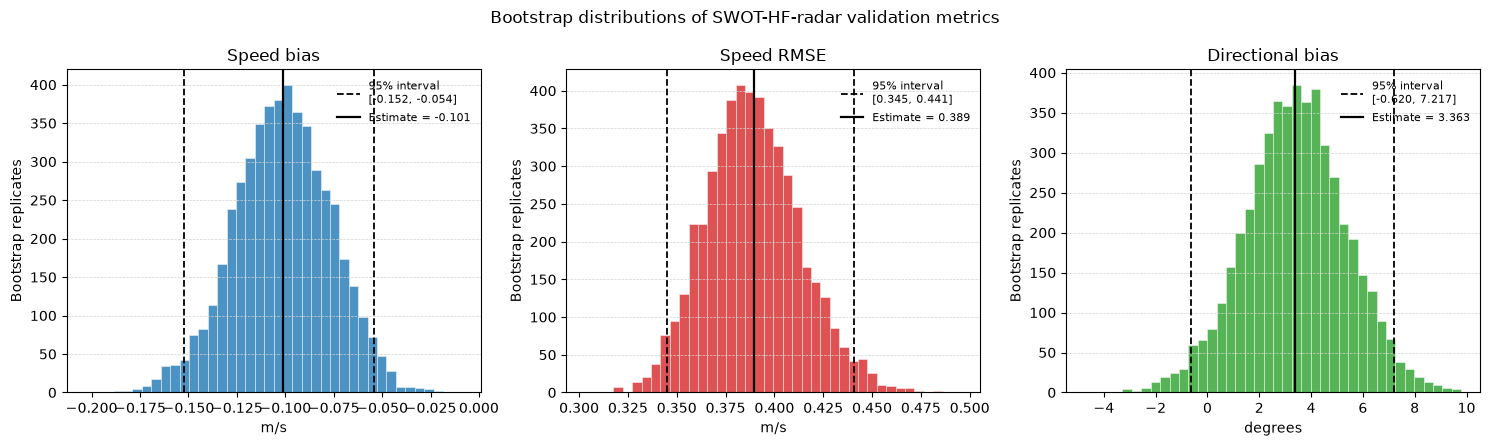

In [68]:
# Histograms of bootstrap distributions for the key validation metrics.
import matplotlib.pyplot as plt

bootstrap_plot_metrics = (
    ('velocity_bias', 'Speed bias', 'm/s', '#1f77b4'),
    ('velocity_rmse', 'Speed RMSE', 'm/s', '#d62728'),
    ('direction_bias', 'Directional bias', 'degrees', '#2ca02c'),
)

figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, (metric_name, title, unit, colour) in zip(axes, bootstrap_plot_metrics):
    values = bootstrap_values[metric_name]
    lower, upper = np.percentile(values, [2.5, 97.5])
    estimate = pooled_estimate[metric_name]

    axis.hist(values, bins=40, color=colour, alpha=0.8, edgecolor='white', linewidth=0.4)
    axis.axvline(lower, color='black', linestyle='--', linewidth=1.3, label=f'95% interval\n[{lower:.3f}, {upper:.3f}]')
    axis.axvline(upper, color='black', linestyle='--', linewidth=1.3)
    axis.axvline(estimate, color='black', linewidth=1.6, label=f'Estimate = {estimate:.3f}')
    axis.set_title(title)
    axis.set_xlabel(unit)
    axis.set_ylabel('Bootstrap replicates')
    axis.grid(axis='y', color='lightgrey', linestyle='--', linewidth=0.5)
    axis.legend(frameon=False, fontsize=8)

figure.suptitle('Bootstrap distributions of SWOT-HF-radar validation metrics')
figure.tight_layout()
plt.show()


Figure S4. Bootstrap distributions of speed bias, speed RMSE, and directional bias for coarsened SWOT currents relative to HF-radar observations. Bootstrap replicates were generated by resampling matched overpasses with replacement. Solid vertical lines indicate the pooled estimates, while dashed lines mark the 95% bootstrap confidence intervals.

In [69]:
# Calculate fixed-grid SWOT MKE/EKE and shared mean-current fields.
from pathlib import Path

import cartopy.crs as ccrs
import numpy as np
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
swot_out_zarr_path = Path(
    globals().get('swot_out_zarr_path', repo_root / 'data/processed/swot_filtered_velocity.zarr')
)
lon_min = globals().get('lon_min', 20.0)
lon_max = globals().get('lon_max', 28.0)
lat_min = globals().get('lat_min', -38.0)
lat_max = globals().get('lat_max', -33.0)
grid_spacing_m = 6_000
data_crs = ccrs.PlateCarree()
grid_crs = ccrs.UTM(zone=34, southern_hemisphere=True)

domain_xy = grid_crs.transform_points(
    data_crs,
    np.array([lon_min, lon_max, lon_max, lon_min]),
    np.array([lat_min, lat_min, lat_max, lat_max]),
)
x_edges = np.arange(
    np.floor(domain_xy[:, 0].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 0].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
y_edges = np.arange(
    np.floor(domain_xy[:, 1].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 1].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
n_x = len(x_edges) - 1
n_y = len(y_edges) - 1


def grid_cell_ids(longitude, latitude):
    """Return flattened 6 km-grid indices for a longitude/latitude field."""
    longitude = np.asarray(longitude)
    latitude = np.asarray(latitude)
    if longitude.ndim == 1 and latitude.ndim == 1:
        longitude, latitude = np.meshgrid(longitude, latitude)
    else:
        longitude, latitude = np.broadcast_arrays(longitude, latitude)
    xy = grid_crs.transform_points(data_crs, longitude.ravel(), latitude.ravel())
    ix = np.digitize(xy[:, 0], x_edges) - 1
    iy = np.digitize(xy[:, 1], y_edges) - 1
    inside = (
        np.isfinite(xy[:, 0]) & np.isfinite(xy[:, 1])
        & (ix >= 0) & (ix < n_x)
        & (iy >= 0) & (iy < n_y)
    )
    cell_ids = np.full(xy.shape[0], -1, dtype=int)
    cell_ids[inside] = iy[inside] * n_x + ix[inside]
    return cell_ids


swot_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)
fixed_grid_variables = {'mke', 'eke', 'u_mean', 'v_mean', 'grid_latitude', 'grid_longitude'}
if fixed_grid_variables.issubset(swot_ds.variables):
    print('Fixed-grid SWOT MKE/EKE and mean currents already exist; using stored fields.')
    swot_out_ds = swot_ds
elif {'mke', 'eke'}.issubset(swot_ds.data_vars):
    swot_ds.close()
    raise ValueError(
        'The SWOT archive contains MKE/EKE fields without fixed-grid coordinates. '
        'Rebuild the filtered-velocity archive before calculating fixed-grid energy.'
    )
else:
    n_passes = swot_ds.sizes['time']
    u_grid_values = np.full((n_passes, n_y * n_x), np.nan, dtype='float32')
    v_grid_values = np.full((n_passes, n_y * n_x), np.nan, dtype='float32')

    for time_index in range(n_passes):
        u_values = np.asarray(
            swot_ds['ugos_filtered'].isel(time=time_index).values, dtype=float,
        ).ravel()
        v_values = np.asarray(
            swot_ds['vgos_filtered'].isel(time=time_index).values, dtype=float,
        ).ravel()
        cell_ids = grid_cell_ids(
            swot_ds['longitude'].isel(time=time_index).values,
            swot_ds['latitude'].isel(time=time_index).values,
        )
        valid = np.isfinite(u_values) & np.isfinite(v_values) & (cell_ids >= 0)
        if valid.any():
            valid_cells = cell_ids[valid]
            counts = np.bincount(valid_cells, minlength=n_y * n_x)
            u_sums = np.bincount(valid_cells, weights=u_values[valid], minlength=n_y * n_x)
            v_sums = np.bincount(valid_cells, weights=v_values[valid], minlength=n_y * n_x)
            occupied = counts > 0
            u_grid_values[time_index, occupied] = u_sums[occupied] / counts[occupied]
            v_grid_values[time_index, occupied] = v_sums[occupied] / counts[occupied]

        if (time_index + 1) % 50 == 0 or time_index + 1 == n_passes:
            print(f'SWOT fixed-grid aggregation: {time_index + 1}/{n_passes} passes')

    grid_x = np.arange(n_x)
    grid_y = np.arange(n_y)
    grid_x_centres = 0.5 * (x_edges[:-1] + x_edges[1:])
    grid_y_centres = 0.5 * (y_edges[:-1] + y_edges[1:])
    grid_x_mesh, grid_y_mesh = np.meshgrid(grid_x_centres, grid_y_centres)
    grid_lonlat = data_crs.transform_points(grid_crs, grid_x_mesh, grid_y_mesh)
    grid_longitude = grid_lonlat[..., 0]
    grid_latitude = grid_lonlat[..., 1]
    u_grid = xr.DataArray(
        u_grid_values.reshape(n_passes, n_y, n_x),
        dims=('time', 'grid_y', 'grid_x'),
        coords={'time': swot_ds.time, 'grid_y': grid_y, 'grid_x': grid_x},
    )
    v_grid = xr.DataArray(
        v_grid_values.reshape(n_passes, n_y, n_x),
        dims=('time', 'grid_y', 'grid_x'),
        coords={'time': swot_ds.time, 'grid_y': grid_y, 'grid_x': grid_x},
    )
    u_mean_swot = u_grid.mean('time', skipna=True)
    v_mean_swot = v_grid.mean('time', skipna=True)
    mke_swot = (0.5 * (u_mean_swot**2 + v_mean_swot**2)).astype('float32')
    eke_swot = (
        0.5 * (
            ((u_grid - u_mean_swot) ** 2).mean('time', skipna=True)
            + ((v_grid - v_mean_swot) ** 2).mean('time', skipna=True)
        )
    ).astype('float32')
    n_obs_swot = (np.isfinite(u_grid) & np.isfinite(v_grid)).sum('time').astype('int32')
    swot_ke_ds = xr.Dataset(
        {
            'mke': mke_swot,
            'eke': eke_swot,
            'u_mean': u_mean_swot.astype('float32'),
            'v_mean': v_mean_swot.astype('float32'),
            'n_obs': n_obs_swot,
        },
        coords={
            'grid_longitude': (('grid_y', 'grid_x'), grid_longitude),
            'grid_latitude': (('grid_y', 'grid_x'), grid_latitude),
        },
    )
    swot_ke_ds['mke'].attrs = {
        'long_name': 'mean kinetic energy per unit mass',
        'units': 'm2 s-2',
        'description': '0.5 * (time-mean fixed-grid u^2 + time-mean fixed-grid v^2)',
    }
    swot_ke_ds['eke'].attrs = {
        'long_name': 'eddy kinetic energy per unit mass',
        'units': 'm2 s-2',
        'description': '0.5 * (mean fixed-grid u-prime^2 + mean fixed-grid v-prime^2)',
    }
    swot_ke_ds['n_obs'].attrs = {
        'long_name': 'number of SWOT overpasses contributing to each fixed grid cell',
    }
    swot_ke_ds.attrs['grid_spacing_m'] = grid_spacing_m
    swot_ke_ds.attrs['grid_projection'] = 'UTM zone 34 south'
    for variable in swot_ke_ds.variables:
        swot_ke_ds[variable].encoding = {}
    swot_ke_ds.to_zarr(
        swot_out_zarr_path,
        mode='a',
        consolidated=True,
        zarr_format=2,
    )
    swot_ds.close()
    swot_out_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)

print('Fixed-grid SWOT mean currents and kinetic energy are ready.')

Fixed-grid SWOT MKE/EKE and mean currents already exist; using stored fields.
Fixed-grid SWOT mean currents and kinetic energy are ready.


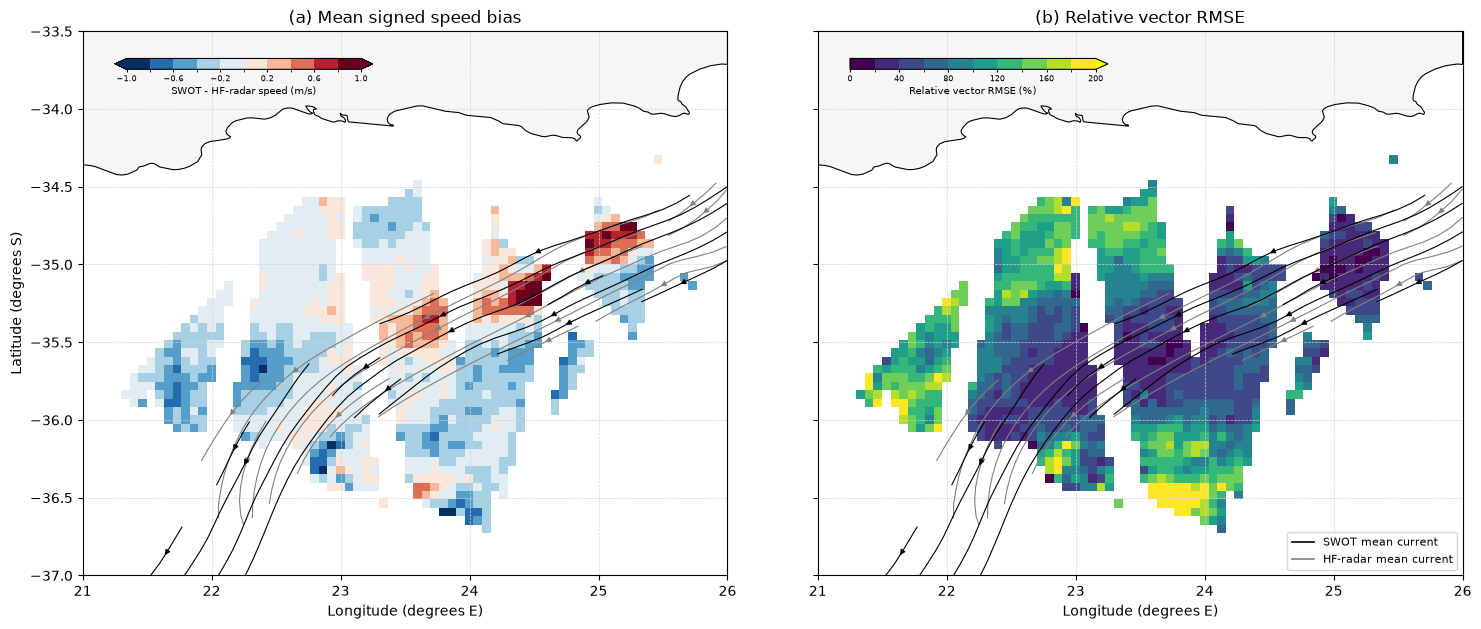

Grid cells with at least 1 paired comparison: 1,128 of 11,250
Median per-cell relative vector RMSE: 72.1%
Max per-cell relative vector RMSE: 200.0%
Mean spatial signed bias: -0.1173 m/s
Median spatial signed bias: -0.1338 m/s


In [92]:
# Spatial distribution of relative vector RMSE and signed speed bias from the zarr-based matched archive.
from pathlib import Path

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata
from shapely.geometry import box
import xarray as xr

repo_root = globals().get('repo_root', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
swot_mean_zarr_path = processed_dir / 'swot_filtered_velocity.zarr'
hf_mean_zarr_path = processed_dir / 'hf_radar.zarr'
PLOT_BBOX = (21.0, 26.0, -37.0, -33.5)
STREAMLINE_SPEED_THRESHOLD = 0.75
MIN_REFERENCE_SPEED = 0.05

if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched zarr archive not found: {matched_zarr_path}. Run Cell 4 first.')
if not swot_mean_zarr_path.exists():
    raise FileNotFoundError(f'SWOT filtered-velocity archive not found: {swot_mean_zarr_path}. Run Cell 3 first.')
if not hf_mean_zarr_path.exists():
    raise FileNotFoundError(f'HF-radar archive not found: {hf_mean_zarr_path}. Run Cell 2 first.')


def centre_edges(coordinates):
    coordinates = np.asarray(coordinates, dtype=float)
    differences = np.diff(coordinates)
    if coordinates.size < 2 or not np.all(differences > 0):
        raise ValueError('Coordinates must be finite, unique, and increasing.')
    edges = np.empty(coordinates.size + 1, dtype=float)
    edges[1:-1] = (coordinates[:-1] + coordinates[1:]) / 2
    edges[0] = coordinates[0] - differences[0] / 2
    edges[-1] = coordinates[-1] + differences[-1] / 2
    return edges


with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    error_grid_latitude = np.asarray(matched_ds['latitude'].values, dtype=float)
    error_grid_longitude = np.asarray(matched_ds['longitude'].values, dtype=float)
    coarse_u = np.asarray(matched_ds['ugos_coarsened_masked'].values, dtype=float)
    coarse_v = np.asarray(matched_ds['vgos_coarsened_masked'].values, dtype=float)
    radar_u = np.asarray(matched_ds['ewct_masked'].values, dtype=float)
    radar_v = np.asarray(matched_ds['nsct_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)

coarse_speed = np.hypot(coarse_u, coarse_v)
radar_speed = np.hypot(radar_u, radar_v)
paired_valid = (
    comparison_mask
    & np.isfinite(coarse_u)
    & np.isfinite(coarse_v)
    & np.isfinite(radar_u)
    & np.isfinite(radar_v)
)

vector_squared_error = (coarse_u - radar_u) ** 2 + (coarse_v - radar_v) ** 2
reference_speed = (coarse_speed + radar_speed) / 2
signed_speed_difference = coarse_speed - radar_speed

vector_squared_error_sum = np.nansum(np.where(paired_valid, vector_squared_error, np.nan), axis=0)
reference_speed_sum = np.nansum(np.where(paired_valid, reference_speed, np.nan), axis=0)
signed_bias_sum = np.nansum(np.where(paired_valid, signed_speed_difference, np.nan), axis=0)
error_count = paired_valid.sum(axis=0).astype(int)

with np.errstate(invalid='ignore', divide='ignore'):
    vector_rmse_grid = np.sqrt(vector_squared_error_sum / error_count)
    mean_reference_speed_grid = reference_speed_sum / error_count
    signed_bias_grid = signed_bias_sum / error_count
    relative_vector_rmse_grid = 100 * vector_rmse_grid / mean_reference_speed_grid

vector_rmse_grid = np.where(error_count > 0, vector_rmse_grid, np.nan)
mean_reference_speed_grid = np.where(error_count > 0, mean_reference_speed_grid, np.nan)
signed_bias_grid = np.where(error_count > 0, signed_bias_grid, np.nan)
relative_vector_rmse_grid = np.where(
    (error_count > 0) & (mean_reference_speed_grid >= MIN_REFERENCE_SPEED),
    relative_vector_rmse_grid,
    np.nan,
)

# Reuse the fixed-grid, time-mean SWOT currents used in the MKE/EKE figure.
with xr.open_zarr(swot_mean_zarr_path, consolidated=True) as swot_mean_ds:
    swot_mean_u = np.asarray(swot_mean_ds['u_mean'].values, dtype=float)
    swot_mean_v = np.asarray(swot_mean_ds['v_mean'].values, dtype=float)
    swot_mean_longitude = np.asarray(swot_mean_ds['grid_longitude'].values, dtype=float)
    swot_mean_latitude = np.asarray(swot_mean_ds['grid_latitude'].values, dtype=float)

# The HF-radar archive stores time-varying components, so calculate their means here.
with xr.open_zarr(hf_mean_zarr_path, consolidated=True) as hf_mean_ds:
    hf_mean_longitude, hf_mean_latitude = np.meshgrid(
        np.asarray(hf_mean_ds['longitude'].values, dtype=float),
        np.asarray(hf_mean_ds['latitude'].values, dtype=float),
    )
    hf_mean_u = np.asarray(hf_mean_ds['ewct'].mean('time', skipna=True).compute().values, dtype=float)
    hf_mean_v = np.asarray(hf_mean_ds['nsct'].mean('time', skipna=True).compute().values, dtype=float)


def regularise_mean_currents(longitude, latitude, u_velocity, v_velocity):
    """Interpolate mean vectors to the shared 80 x 60 plotting grid and apply the speed cutoff."""
    valid = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & np.isfinite(u_velocity)
        & np.isfinite(v_velocity)
    )
    streamline_longitude = np.linspace(PLOT_BBOX[0], PLOT_BBOX[1], 80)
    streamline_latitude = np.linspace(PLOT_BBOX[2], PLOT_BBOX[3], 60)
    streamline_lon2d, streamline_lat2d = np.meshgrid(streamline_longitude, streamline_latitude)
    points = np.column_stack((longitude[valid], latitude[valid]))
    streamline_u = griddata(
        points, u_velocity[valid], (streamline_lon2d, streamline_lat2d), method='linear',
    )
    streamline_v = griddata(
        points, v_velocity[valid], (streamline_lon2d, streamline_lat2d), method='linear',
    )
    streamline_speed = np.hypot(streamline_u, streamline_v)
    streamline_u[streamline_speed <= STREAMLINE_SPEED_THRESHOLD] = np.nan
    streamline_v[streamline_speed <= STREAMLINE_SPEED_THRESHOLD] = np.nan
    return streamline_longitude, streamline_latitude, streamline_u, streamline_v


streamline_longitude, streamline_latitude, stream_u, stream_v = regularise_mean_currents(
    swot_mean_longitude, swot_mean_latitude, swot_mean_u, swot_mean_v,
)
hf_streamline_longitude, hf_streamline_latitude, hf_stream_u, hf_stream_v = regularise_mean_currents(
    hf_mean_longitude, hf_mean_latitude, hf_mean_u, hf_mean_v,
)

error_lat_edges = centre_edges(error_grid_latitude)
error_lon_edges = centre_edges(error_grid_longitude)
land_path = repo_root / 'data/raw/basemaps/ne_10m_land.zip'
land = gpd.read_file(land_path).clip(box(PLOT_BBOX[0], PLOT_BBOX[2], PLOT_BBOX[1], PLOT_BBOX[3]))

rmse_levels = np.arange(0, 220, 20)
rmse_cmap = plt.get_cmap('viridis', len(rmse_levels) - 1).copy()
rmse_cmap.set_over('yellow')
rmse_norm = mcolors.BoundaryNorm(rmse_levels, rmse_cmap.N)
signed_bias_step = 0.2
signed_bias_limit = max(float(np.nanpercentile(np.abs(signed_bias_grid), 99)), signed_bias_step)
signed_bias_limit = signed_bias_step * np.ceil(signed_bias_limit / signed_bias_step)
signed_bias_boundaries = np.arange(
    -signed_bias_limit,
    signed_bias_limit + signed_bias_step / 2,
    signed_bias_step,
)
signed_bias_cmap = plt.get_cmap('RdBu_r', len(signed_bias_boundaries) - 1)
signed_bias_norm = mcolors.BoundaryNorm(signed_bias_boundaries, signed_bias_cmap.N)

streamline_handles = [
    plt.Line2D([], [], color='black', linewidth=1.2, label='SWOT mean current'),
    plt.Line2D([], [], color='grey', linewidth=1.2, label='HF-radar mean current'),
]

figure, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

land.plot(ax=axes[0], color='gainsboro', alpha=0.25, zorder=2)
land.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
bias_mesh = axes[0].pcolormesh(
    error_lon_edges,
    error_lat_edges,
    signed_bias_grid,
    cmap=signed_bias_cmap,
    norm=signed_bias_norm,
    zorder=1,
)
axes[0].streamplot(
    streamline_longitude,
    streamline_latitude,
    np.ma.masked_invalid(stream_u),
    np.ma.masked_invalid(stream_v),
    color='black',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=6,
)
axes[0].streamplot(
    hf_streamline_longitude,
    hf_streamline_latitude,
    np.ma.masked_invalid(hf_stream_u),
    np.ma.masked_invalid(hf_stream_v),
    color='grey',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=5,
)
axes[0].set_title('(a) Mean signed speed bias')

land.plot(ax=axes[1], color='gainsboro', alpha=0.25, zorder=2)
land.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
rmse_mesh = axes[1].pcolormesh(
    error_lon_edges,
    error_lat_edges,
    relative_vector_rmse_grid,
    cmap=rmse_cmap,
    norm=rmse_norm,
    zorder=1,
)
axes[1].streamplot(
    streamline_longitude,
    streamline_latitude,
    np.ma.masked_invalid(stream_u),
    np.ma.masked_invalid(stream_v),
    color='black',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=6,
)
axes[1].streamplot(
    hf_streamline_longitude,
    hf_streamline_latitude,
    np.ma.masked_invalid(hf_stream_u),
    np.ma.masked_invalid(hf_stream_v),
    color='grey',
    linewidth=0.8,
    density=1.3,
    arrowsize=0.8,
    zorder=5,
)
axes[1].set_title('(b) Relative vector RMSE')
axes[1].legend(handles=streamline_handles, loc='lower right', fontsize=8, framealpha=0.8)

for axis in axes:
    axis.set_xlim(PLOT_BBOX[0], PLOT_BBOX[1])
    axis.set_ylim(PLOT_BBOX[2], PLOT_BBOX[3])
    axis.set_xlabel('Longitude (degrees E)')
    axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
axes[0].set_ylabel('Latitude (degrees S)')

figure.subplots_adjust(left=0.06, right=0.98, bottom=0.12, top=0.90, wspace=0.14)
bias_colourbar_axis = axes[0].inset_axes([0.05, 0.93, 0.40, 0.02])
rmse_colourbar_axis = axes[1].inset_axes([0.05, 0.93, 0.40, 0.02])
bias_colourbar = figure.colorbar(
    bias_mesh,
    cax=bias_colourbar_axis,
    orientation='horizontal',
    ticks=signed_bias_boundaries[::2],
    extend='both',
)
rmse_colourbar = figure.colorbar(
    rmse_mesh,
    cax=rmse_colourbar_axis,
    orientation='horizontal',
    ticks=rmse_levels[::2],
    extend='max',
)
bias_colourbar.set_label('SWOT - HF-radar speed (m/s)', fontsize=7, labelpad=2)
rmse_colourbar.set_label('Relative vector RMSE (%)', fontsize=7, labelpad=2)
for colourbar in (bias_colourbar, rmse_colourbar):
    colourbar.ax.tick_params(labelsize=6, length=2, pad=2)
plt.show()

print(f'Grid cells with at least 1 paired comparison: {(error_count > 0).sum():,} of {error_count.size:,}')
print(f'Median per-cell relative vector RMSE: {np.nanmedian(relative_vector_rmse_grid):.1f}%')
print(f'Max per-cell relative vector RMSE: {np.nanmax(relative_vector_rmse_grid):.1f}%')
print(f'Mean spatial signed bias: {np.nanmean(signed_bias_grid):+.4f} m/s')
print(f'Median spatial signed bias: {np.nanmedian(signed_bias_grid):+.4f} m/s')

Figure 2. Spatial distribution of signed speed bias and relative vector RMSE between coarsened SWOT and HF-radar currents. The left panel shows the mean signed speed difference, calculated as SWOT minus HF radar. The right panel shows relative vector RMSE calculated from paired eastward and northward velocity-component differences and normalised by the mean paired current speed in each grid cell. Both metrics were calculated on the common 6 km grid using all valid paired observations. Grey streamlines show the mean SWOT current field where mean speed is ⩾0.75 m/s.

In [72]:
# Match Copernicus surface currents to the accepted SWOT/HF-radar comparisons.
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
matched_path = repo_root / 'data/processed/swot_hfradar_zarr_matches.zarr'
copernicus_dir = repo_root / 'data/raw/copernicusmarine'

sources = {
    'ekman': ('cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i', 'ue', 've', '30min'),
    'tide': ('cmems_obs-mob_glo_phy-cur_nrt_0.25deg_PT1H-i', 'utide', 'vtide', '30min'),
    'stokes': ('cmems_mod_glo_wav_anfc_0.083deg_PT3H-i', 'VSDX', 'VSDY', '90min'),
}

with xr.open_zarr(matched_path, consolidated=True, chunks=None) as matched:
    radar_times = xr.DataArray(
        matched.radar_time.values, dims='match', coords={'match': matched.match.values},
    )
    radar_latitude = matched.latitude.values
    radar_longitude = matched.longitude.values
    comparison_mask = matched.comparison_mask.values

matched_currents = xr.Dataset()
for component, (folder, east_name, north_name, tolerance) in sources.items():
    paths = list((copernicus_dir / folder).glob('*.nc'))
    if len(paths) != 1:
        raise ValueError(f'Expected one NetCDF file in {folder}, found {len(paths)}')
    with xr.open_dataset(paths[0]) as current_ds:
        surface = current_ds[[east_name, north_name]]
        if 'depth' in surface.dims:
            surface = surface.sel(depth=0)
        selected = surface.sel(
            time=radar_times, method='nearest', tolerance=pd.Timedelta(tolerance),
        )
        source_times = selected.time.values
        gridded = selected.interp(
            latitude=radar_latitude, longitude=radar_longitude,
        )
        east = gridded[east_name].values
        north = gridded[north_name].values

    valid = (
        comparison_mask & np.isfinite(east) & np.isfinite(north)
        & (np.abs(east) < 10) & (np.abs(north) < 10)
    )
    for direction, values in (('u', east), ('v', north)):
        matched_currents[f'{component}_{direction}_masked'] = (
            ('match', 'latitude', 'longitude'),
            np.where(valid, values, np.nan).astype(np.float32),
            {'units': 'm s-1', 'source_variable': east_name if direction == 'u' else north_name,
             'source_file': paths[0].name},
        )
    matched_currents[f'{component}_time'] = (('match',), source_times)
    matched_currents[f'{component}_time_gap_seconds'] = (
        ('match',),
        (np.abs(source_times - radar_times.values) / np.timedelta64(1, 's')).astype(np.float32),
    )
    print(f'{component}: {valid.sum()} valid comparison cells across {len(source_times)} matches')

matched_currents.to_zarr(matched_path, mode='a', consolidated=True, zarr_format=3)
print(f'Added Copernicus surface currents to {matched_path}')

ekman: 6416 valid comparison cells across 35 matches
tide: 6416 valid comparison cells across 35 matches
stokes: 6416 valid comparison cells across 35 matches
Added Copernicus surface currents to <repo>/data/processed/swot_hfradar_zarr_matches.zarr


<env>/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


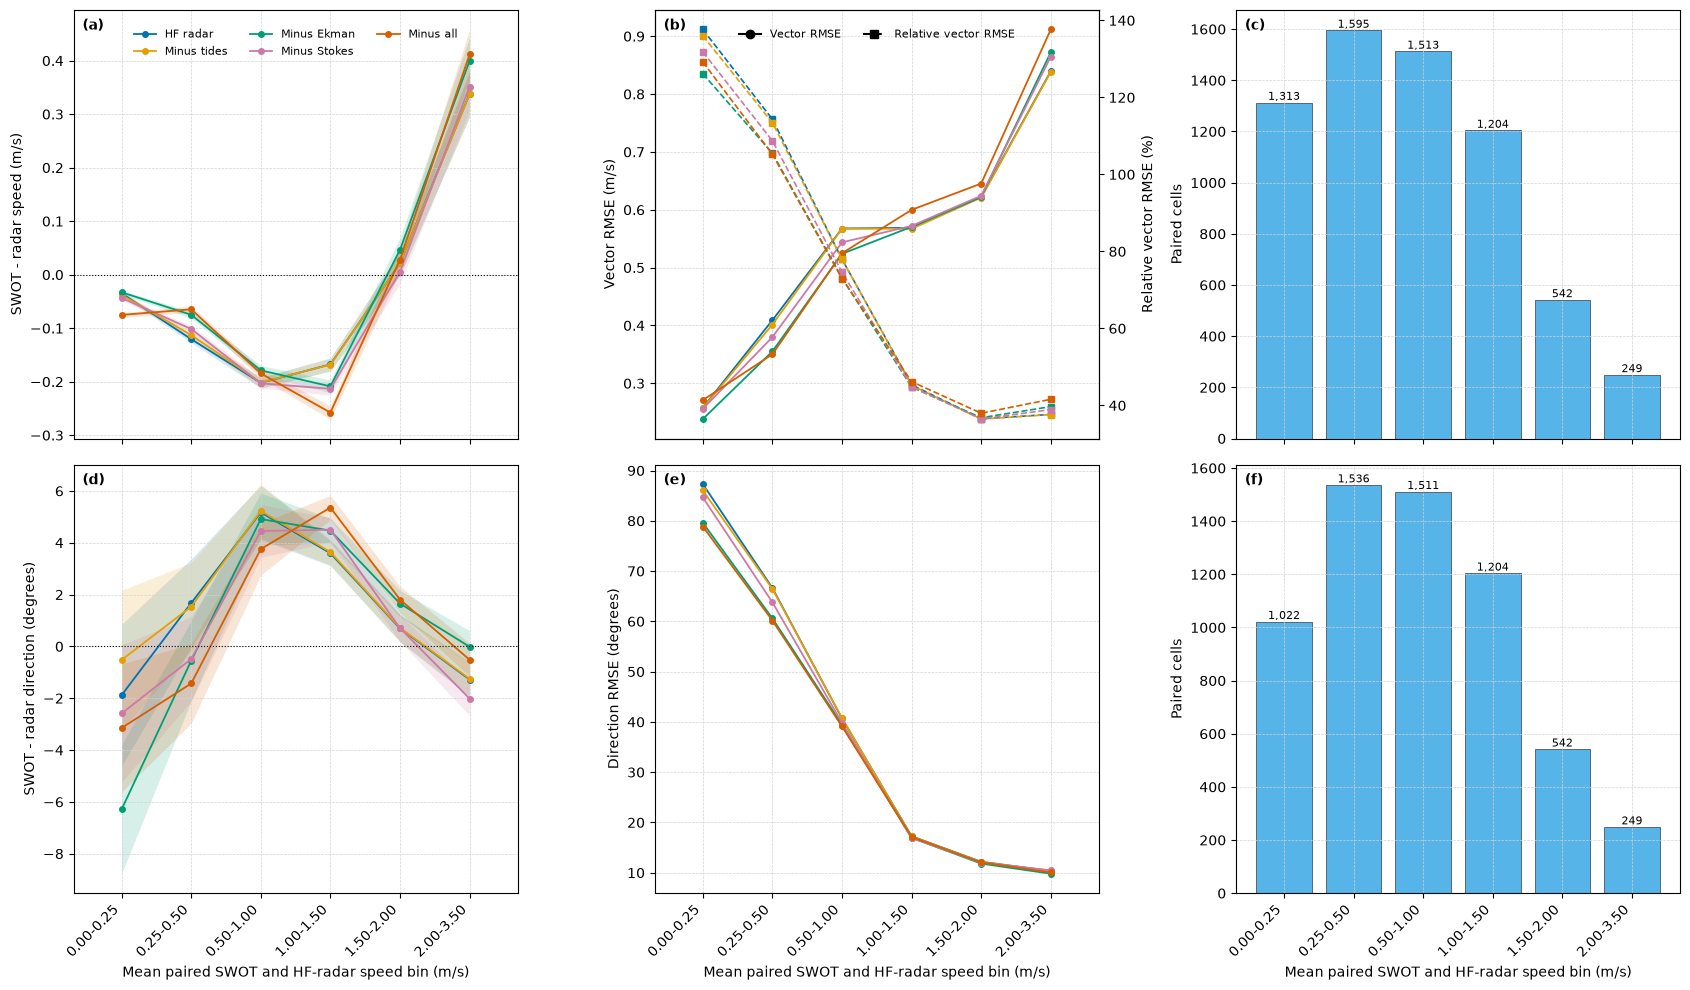

Speed pairs in bins (identical for all variants): 6,416
Direction/vector pairs in bins (identical for all variants): 6,064
Minus tides: vector RMSE change (m/s) = [-0.001, -0.008, -0.0, -0.002, -0.001, -0.001], direction RMSE change (deg) = [-1.3, -0.2, 0.1, -0.0, -0.0, -0.0]
Minus Ekman: vector RMSE change (m/s) = [-0.02, -0.054, -0.044, 0.002, -0.0, 0.033], direction RMSE change (deg) = [-7.7, -6.0, -1.2, -0.3, -0.4, -0.6]
Minus Stokes: vector RMSE change (m/s) = [-0.002, -0.029, -0.024, 0.003, 0.002, 0.025], direction RMSE change (deg) = [-2.6, -2.8, -0.9, -0.4, -0.2, 0.1]
Minus all: vector RMSE change (m/s) = [0.013, -0.059, -0.043, 0.031, 0.023, 0.072], direction RMSE change (deg) = [-8.4, -6.5, -1.6, -0.2, -0.1, -0.3]


In [73]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
matched_path = repo_root / 'data/processed/swot_hfradar_zarr_matches.zarr'
minimum_vector_speed = 0.05

with xr.open_zarr(matched_path, consolidated=True, chunks=None) as matched_ds:
    swot_u = matched_ds.ugos_coarsened_masked.values.astype(float)
    swot_v = matched_ds.vgos_coarsened_masked.values.astype(float)
    radar_u = matched_ds.ewct_masked.values.astype(float)
    radar_v = matched_ds.nsct_masked.values.astype(float)
    paired_mask = matched_ds.comparison_mask.values.copy()
    corrections = {
        component: (
            matched_ds[f'{component}_u_masked'].values.astype(float),
            matched_ds[f'{component}_v_masked'].values.astype(float),
        )
        for component in ('tide', 'ekman', 'stokes')
    }

variants = {
    'HF radar': (radar_u, radar_v),
    'Minus tides': (radar_u - corrections['tide'][0], radar_v - corrections['tide'][1]),
    'Minus Ekman': (radar_u - corrections['ekman'][0], radar_v - corrections['ekman'][1]),
    'Minus Stokes': (radar_u - corrections['stokes'][0], radar_v - corrections['stokes'][1]),
    'Minus all': (
        radar_u - sum(values[0] for values in corrections.values()),
        radar_v - sum(values[1] for values in corrections.values()),
    ),
}
variant_colours = {
    'HF radar': '#0072B2',
    'Minus tides': '#E69F00',
    'Minus Ekman': '#009E73',
    'Minus Stokes': '#CC79A7',
    'Minus all': '#D55E00',
}

paired_mask &= np.isfinite(swot_u) & np.isfinite(swot_v)
for variant_u, variant_v in variants.values():
    paired_mask &= np.isfinite(variant_u) & np.isfinite(variant_v)
if not paired_mask.any():
    raise ValueError('No common paired SWOT/HF-radar velocities remain.')

swot_speed = np.hypot(swot_u, swot_v)
radar_speed = np.hypot(radar_u, radar_v)
mean_pair_speed = 0.5 * (swot_speed + radar_speed)
swot_direction = np.degrees(np.arctan2(swot_v, swot_u))
vector_mask = paired_mask & (swot_speed >= minimum_vector_speed)
for variant_u, variant_v in variants.values():
    vector_mask &= np.hypot(variant_u, variant_v) >= minimum_vector_speed
if not vector_mask.any():
    raise ValueError('No common paired vectors meet the direction speed threshold.')

bin_edges = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.5])
bin_labels = ['0.00-0.25', '0.25-0.50', '0.50-1.00', '1.00-1.50', '1.50-2.00', '2.00-3.50']
bin_positions = np.arange(len(bin_labels))
speed_counts = np.zeros(len(bin_labels), dtype=int)
vector_counts = np.zeros(len(bin_labels), dtype=int)
metrics = {
    label: {name: np.full(len(bin_labels), np.nan) for name in (
        'speed_bias', 'speed_sem', 'vector_rmse', 'relative_vector_rmse',
        'direction_bias', 'direction_sem', 'direction_rmse',
    )}
    for label in variants
}

for bin_index in range(len(bin_labels)):
    in_bin = (mean_pair_speed >= bin_edges[bin_index]) & (
        (mean_pair_speed <= bin_edges[bin_index + 1]) if bin_index == len(bin_labels) - 1
        else (mean_pair_speed < bin_edges[bin_index + 1])
    )
    speed_valid = paired_mask & in_bin
    vector_valid = vector_mask & in_bin
    speed_counts[bin_index] = int(speed_valid.sum())
    vector_counts[bin_index] = int(vector_valid.sum())

    for label, (variant_u, variant_v) in variants.items():
        variant_speed = np.hypot(variant_u, variant_v)
        values = metrics[label]
        if speed_counts[bin_index]:
            speed_error = swot_speed[speed_valid] - variant_speed[speed_valid]
            values['speed_bias'][bin_index] = np.mean(speed_error)
            if speed_counts[bin_index] > 1:
                values['speed_sem'][bin_index] = np.std(speed_error, ddof=1) / np.sqrt(speed_counts[bin_index])
        if not vector_counts[bin_index]:
            continue
        squared_error = (swot_u[vector_valid] - variant_u[vector_valid]) ** 2 + (
            swot_v[vector_valid] - variant_v[vector_valid]
        ) ** 2
        values['vector_rmse'][bin_index] = np.sqrt(np.mean(squared_error))
        reference_speed = (swot_speed[vector_valid] + variant_speed[vector_valid]) / 2
        values['relative_vector_rmse'][bin_index] = (
            100 * values['vector_rmse'][bin_index] / np.mean(reference_speed)
        )
        variant_direction = np.degrees(np.arctan2(variant_v[vector_valid], variant_u[vector_valid]))
        direction_error = ((swot_direction[vector_valid] - variant_direction + 180) % 360) - 180
        values['direction_bias'][bin_index] = np.mean(direction_error)
        values['direction_rmse'][bin_index] = np.sqrt(np.mean(direction_error ** 2))
        if vector_counts[bin_index] > 1:
            values['direction_sem'][bin_index] = np.std(direction_error, ddof=1) / np.sqrt(vector_counts[bin_index])

figure, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True)
speed_bias_axis, vector_error_axis, speed_count_axis = axes[0]
direction_bias_axis, direction_error_axis, vector_count_axis = axes[1]
relative_vector_axis = vector_error_axis.twinx()

for label, values in metrics.items():
    colour = variant_colours[label]
    speed_bias_axis.plot(bin_positions, values['speed_bias'], 'o-',
                         color=colour, linewidth=1.3, markersize=4, label=label)
    speed_bias_axis.fill_between(bin_positions, values['speed_bias'] - values['speed_sem'],
                                 values['speed_bias'] + values['speed_sem'],
                                 color=colour, alpha=0.16, linewidth=0)
    vector_error_axis.plot(bin_positions, values['vector_rmse'], 'o-', color=colour, linewidth=1.3, markersize=4)
    relative_vector_axis.plot(bin_positions, values['relative_vector_rmse'], 's--', color=colour,
                              linewidth=1.2, markersize=4)
    direction_bias_axis.plot(bin_positions, values['direction_bias'], 'o-',
                             color=colour, linewidth=1.3, markersize=4)
    direction_bias_axis.fill_between(bin_positions, values['direction_bias'] - values['direction_sem'],
                                     values['direction_bias'] + values['direction_sem'],
                                     color=colour, alpha=0.16, linewidth=0)
    direction_error_axis.plot(bin_positions, values['direction_rmse'], 'o-', color=colour, linewidth=1.3, markersize=4)

speed_bias_axis.axhline(0, color='black', linestyle=':', linewidth=0.8)
direction_bias_axis.axhline(0, color='black', linestyle=':', linewidth=0.8)
speed_bias_axis.set_ylabel('SWOT - radar speed (m/s)')
speed_bias_axis.legend(
    fontsize=8, loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=3, frameon=False,
)
vector_error_axis.set_ylabel('Vector RMSE (m/s)')
relative_vector_axis.set_ylabel('Relative vector RMSE (%)')
vector_error_axis.legend(handles=[
    plt.Line2D([], [], color='black', marker='o', label='Vector RMSE'),
    plt.Line2D([], [], color='black', marker='s', linestyle='--', label='Relative vector RMSE'),
], loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=2, fontsize=8, frameon=False)
speed_count_axis.set_ylabel('Paired cells')
direction_bias_axis.set_ylabel('SWOT - radar direction (degrees)')
direction_error_axis.set_ylabel('Direction RMSE (degrees)')
vector_count_axis.set_ylabel('Paired cells')

for axis, panel_label in zip(axes.ravel(), ('(a)', '(b)', '(c)', '(d)', '(e)', '(f)')):
    axis.text(
        0.02, 0.98, panel_label,
        transform=axis.transAxes,
        ha='left', va='top',
        fontweight='bold',
    )

for axis, counts in ((speed_count_axis, speed_counts), (vector_count_axis, vector_counts)):
    axis.bar(bin_positions, counts, width=0.8, color='#56B4E9', edgecolor='#343a40', linewidth=0.5)
    for position, count in zip(bin_positions, counts):
        if count:
            axis.text(position, count, f'{count:,}', ha='center', va='bottom', fontsize=8)
for axis in axes.ravel():
    axis.set_xticks(bin_positions)
    axis.set_xticklabels(bin_labels, rotation=45, ha='right')
    axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
for axis in axes[1]:
    axis.set_xlabel('Mean paired SWOT and HF-radar speed bin (m/s)')

figure.tight_layout()
plt.show()
print(f'Speed pairs in bins (identical for all variants): {speed_counts.sum():,}')
print(f'Direction/vector pairs in bins (identical for all variants): {vector_counts.sum():,}')
for label, values in metrics.items():
    if label == 'HF radar':
        continue
    vector_change = values['vector_rmse'] - metrics['HF radar']['vector_rmse']
    direction_change = values['direction_rmse'] - metrics['HF radar']['direction_rmse']
    print(f'{label}: vector RMSE change (m/s) = {np.round(vector_change, 3).tolist()}, '
          f'direction RMSE change (deg) = {np.round(direction_change, 1).tolist()}')

Figure 3. Speed dependence of agreement between SWOT and HF radar, and the effect of subtracting Copernicus tide, Ekman, and Stokes currents from the radar velocities. Panels show (a) speed bias (SWOT minus radar), (b) vector RMSE and relative vector RMSE, (c) speed-pair counts, (d) direction bias, (e) direction RMSE, and (f) direction/vector-pair counts. Speed bins are defined using the mean of coarsened-SWOT and uncorrected HF-radar speeds. Raw and corrected radar variants are evaluated on the same observations within each bin; shading indicates the standard error of the mean for bias estimates. Direction statistics use paired vectors with speeds of at least 0.05 m s⁻¹ in SWOT and all radar variants. Relative vector RMSE is normalised by mean paired speed.

In [98]:
# SWOT:uncorrected HF-radar speed ratios using Figure 3's bins and common speed-pair mask.
# Run the Figure 3 calculation cell first; no input data are reloaded here.
from IPython.display import display
import pandas as pd

paired_speed_ratio = np.full(swot_speed.shape, np.nan, dtype=float)
ratio_defined = paired_mask & (radar_speed > 0)
np.divide(swot_speed, radar_speed, out=paired_speed_ratio, where=ratio_defined)
ratio_direction_min_speed = 0.05
ratio_direction_valid = (
    paired_mask & (swot_speed >= ratio_direction_min_speed)
    & (radar_speed >= ratio_direction_min_speed)
)
ratio_direction_difference = (
    np.degrees(np.arctan2(swot_v, swot_u))
    - np.degrees(np.arctan2(radar_v, radar_u)) + 180
) % 360 - 180

speed_ratio_rows = []
vector_mismatch = np.full(swot_speed.shape, np.nan, dtype=float)
mismatch_speed_sum = swot_speed + radar_speed
mismatch_defined = paired_mask & (mismatch_speed_sum > 0)
np.divide(
    np.hypot(swot_u - radar_u, swot_v - radar_v), mismatch_speed_sum,
    out=vector_mismatch, where=mismatch_defined,
)
vector_mismatch_rows = []
for ratio_bin_index, ratio_bin_label in enumerate(bin_labels):
    ratio_in_bin = (mean_pair_speed >= bin_edges[ratio_bin_index]) & (
        (mean_pair_speed <= bin_edges[ratio_bin_index + 1])
        if ratio_bin_index == len(bin_labels) - 1
        else (mean_pair_speed < bin_edges[ratio_bin_index + 1])
    )
    ratio_valid = paired_mask & ratio_in_bin
    ratio_pair_count = int(ratio_valid.sum())
    ratio_values = paired_speed_ratio[ratio_valid & ratio_defined]
    ratio_defined_count = int(ratio_values.size)
    ratio_angle_errors = ratio_direction_difference[ratio_in_bin & ratio_direction_valid]
    ratio_direction_count = int(ratio_angle_errors.size)
    ratio_absolute_angles = np.abs(ratio_angle_errors)
    mismatch_values = vector_mismatch[ratio_valid & mismatch_defined]
    mismatch_count = int(mismatch_values.size)
    mismatch_quartiles = (
        np.quantile(mismatch_values, [0.25, 0.5, 0.75])
        if mismatch_count else np.full(3, np.nan)
    )
    vector_mismatch_rows.append({
        'Speed bin (m/s)': ratio_bin_label,
        'Defined pairs': mismatch_count,
        'Median D': mismatch_quartiles[1],
        'Q1 D': mismatch_quartiles[0],
        'Q3 D': mismatch_quartiles[2],
        'Both speeds zero': ratio_pair_count - mismatch_count,
    })
    speed_ratio_rows.append({
        'Speed bin (m/s)': ratio_bin_label,
        'Speed pairs': ratio_pair_count,
        'Defined paired ratios': ratio_defined_count,
        'Mean paired speed ratio': float(ratio_values.mean()) if ratio_defined_count else np.nan,
        'Median paired speed ratio': float(np.median(ratio_values)) if ratio_defined_count else np.nan,
        'Std paired speed ratio': float(ratio_values.std(ddof=1)) if ratio_defined_count > 1 else np.nan,
        'Zero radar speeds': ratio_pair_count - ratio_defined_count,
        'Direction pairs': ratio_direction_count,
        'Mean absolute angle difference (deg)': (
            float(ratio_absolute_angles.mean()) if ratio_direction_count else np.nan
        ),
        'Median absolute angle difference (deg)': (
            float(np.median(ratio_absolute_angles)) if ratio_direction_count else np.nan
        ),
        'Directional RMSE (deg)': (
            float(np.sqrt(np.mean(ratio_angle_errors ** 2))) if ratio_direction_count else np.nan
        ),
    })

speed_ratio_table = pd.DataFrame(speed_ratio_rows)
vector_mismatch_table = pd.DataFrame(vector_mismatch_rows)
print('D = |SWOT vector - radar vector| / (SWOT speed + radar speed).')
print('D ranges from 0 (identical vectors) to 1 (opposite vectors or one zero speed).')
print('Bins and common speed-pair mask match Figure 3; radar velocities are uncorrected.')
print('No minimum-speed cutoff is applied; both-zero pairs are excluded and counted.')
print('Q1-Q3 gives the interquartile range, not uncertainty in the median. NaN means no defined pairs.')
print('D measures vector agreement, not a geostrophic fraction. Separate diagnostics remain in speed_ratio_table.')
display(vector_mismatch_table.style.format({
    'Median D': '{:.3f}',
    'Q1 D': '{:.3f}',
    'Q3 D': '{:.3f}',
}, na_rep='NaN'))


D = |SWOT vector - radar vector| / (SWOT speed + radar speed).
D ranges from 0 (identical vectors) to 1 (opposite vectors or one zero speed).
Bins and common speed-pair mask match Figure 3; radar velocities are uncorrected.
No minimum-speed cutoff is applied; both-zero pairs are excluded and counted.
Q1-Q3 gives the interquartile range, not uncertainty in the median. NaN means no defined pairs.
D measures vector agreement, not a geostrophic fraction. Separate diagnostics remain in speed_ratio_table.


,Speed bin (m/s),Defined pairs,Median D,Q1 D,Q3 D,Both speeds zero
0,0.00-0.25,1313,0.698,0.464,0.889,0
1,0.25-0.50,1595,0.500,0.315,0.731,0
2,0.50-1.00,1513,0.293,0.178,0.441,0
3,1.00-1.50,1204,0.148,0.083,0.245,0
4,1.50-2.00,542,0.123,0.079,0.197,0
5,2.00-3.50,249,0.111,0.064,0.198,0


In [74]:
from pathlib import Path

from IPython.display import display
import numpy as np
import pandas as pd
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
matched_path = repo_root / 'data/processed/swot_hfradar_zarr_matches.zarr'
minimum_direction_speed = 0.05

with xr.open_zarr(matched_path, consolidated=True, chunks=None) as matched_ds:
    swot_u = matched_ds.ugos_coarsened_masked.values
    swot_v = matched_ds.vgos_coarsened_masked.values
    radar_u = matched_ds.ewct_masked.values
    radar_v = matched_ds.nsct_masked.values
    comparison_mask = matched_ds.comparison_mask.values
    corrections = {
        component: (matched_ds[f'{component}_u_masked'].values,
                    matched_ds[f'{component}_v_masked'].values)
        for component in ('tide', 'ekman', 'stokes')
    }

radar_variants = {
    'HF radar': (radar_u, radar_v),
    'HF radar - tides': (radar_u - corrections['tide'][0], radar_v - corrections['tide'][1]),
    'HF radar - Ekman': (radar_u - corrections['ekman'][0], radar_v - corrections['ekman'][1]),
    'HF radar - Stokes': (radar_u - corrections['stokes'][0], radar_v - corrections['stokes'][1]),
    'HF radar - all': (
        radar_u - sum(values[0] for values in corrections.values()),
        radar_v - sum(values[1] for values in corrections.values()),
    ),
}

paired_mask = comparison_mask & np.isfinite(swot_u) & np.isfinite(swot_v)
for variant_u, variant_v in radar_variants.values():
    paired_mask &= np.isfinite(variant_u) & np.isfinite(variant_v)
if not paired_mask.any():
    raise ValueError('No complete SWOT/HF-radar comparisons are available.')

swot_speed = np.hypot(swot_u, swot_v)
direction_mask = paired_mask & (swot_speed >= minimum_direction_speed)
for variant_u, variant_v in radar_variants.values():
    direction_mask &= np.hypot(variant_u, variant_v) >= minimum_direction_speed
if not direction_mask.any():
    raise ValueError('No common pairs meet the direction speed threshold.')

swot_direction = np.degrees(np.arctan2(swot_v, swot_u))
global_rows = []
for label, (variant_u, variant_v) in radar_variants.items():
    variant_speed = np.hypot(variant_u, variant_v)
    speed_error = swot_speed[paired_mask] - variant_speed[paired_mask]
    u_error = swot_u[paired_mask] - variant_u[paired_mask]
    v_error = swot_v[paired_mask] - variant_v[paired_mask]
    variant_direction = np.degrees(np.arctan2(variant_v, variant_u))
    direction_error = (
        (swot_direction[direction_mask] - variant_direction[direction_mask] + 180.0) % 360.0
    ) - 180.0
    error_radians = np.radians(direction_error)
    mean_sine = np.mean(np.sin(error_radians))
    mean_cosine = np.mean(np.cos(error_radians))
    resultant_length = np.hypot(mean_sine, mean_cosine)
    global_rows.append({
        'Radar variant': label,
        'Speed pairs': int(paired_mask.sum()),
        'Speed bias (m/s)': float(np.mean(speed_error)),
        'Speed MAE (m/s)': float(np.mean(np.abs(speed_error))),
        'Speed RMSE (m/s)': float(np.sqrt(np.mean(speed_error ** 2))),
        'Speed r': float(np.corrcoef(swot_speed[paired_mask], variant_speed[paired_mask])[0, 1]),
        'Vector RMSE (m/s)': float(np.sqrt(np.mean(u_error ** 2 + v_error ** 2))),
        'Direction pairs': int(direction_mask.sum()),
        'Direction circular bias (deg)': float(np.degrees(np.arctan2(mean_sine, mean_cosine))),
        'Direction MAE (deg)': float(np.mean(np.abs(direction_error))),
        'Direction RMSE (deg)': float(np.sqrt(np.mean(direction_error ** 2))),
        'Direction circular spread (deg)': (
            float(np.degrees(np.sqrt(-2.0 * np.log(resultant_length))))
            if resultant_length > 0 else np.nan
        ),
    })

global_stats = pd.DataFrame(global_rows).set_index('Radar variant')
print('SWOT minus HF-radar variant; pooled matched cells across all overpasses.')
print(f'Direction requires every variant and SWOT to exceed {minimum_direction_speed:g} m/s.')
display(global_stats.round(3))

SWOT minus HF-radar variant; pooled matched cells across all overpasses.
Direction requires every variant and SWOT to exceed 0.05 m/s.


,Speed pairs,Speed bias (m/s),Speed MAE (m/s),Speed RMSE (m/s),Speed r,Vector RMSE (m/s),Direction pairs,Direction circular bias (deg),Direction MAE (deg),Direction RMSE (deg),Direction circular spread (deg)
Radar variant,,,,,,,,,,,
HF radar,6416,-0.101,0.280,0.389,0.808,0.503,6064,3.505,34.518,53.835,48.214
HF radar - tides,6416,-0.100,0.278,0.387,0.809,0.501,6064,3.737,34.342,53.443,47.993
HF radar - Ekman,6416,-0.087,0.266,0.380,0.817,0.481,6064,3.292,31.376,49.586,44.383
HF radar - Stokes,6416,-0.108,0.273,0.385,0.816,0.493,6064,2.901,32.955,52.034,46.488
HF radar - all,6416,-0.105,0.281,0.396,0.808,0.496,6064,3.410,31.155,49.206,44.077


Table S2. Pooled comparison statistics for HF-radar velocities and variants corrected by subtracting tides, Ekman currents, Stokes drift, or all three, relative to coarsened SWOT velocities across the matched overpasses. Speed metrics use the common set of valid paired grid cells; direction metrics use the common subset where SWOT and every radar variant have speeds greater than 0.05 m s⁻¹. Bias is defined as SWOT minus the radar variant. Directional bias and spread are circular statistics.

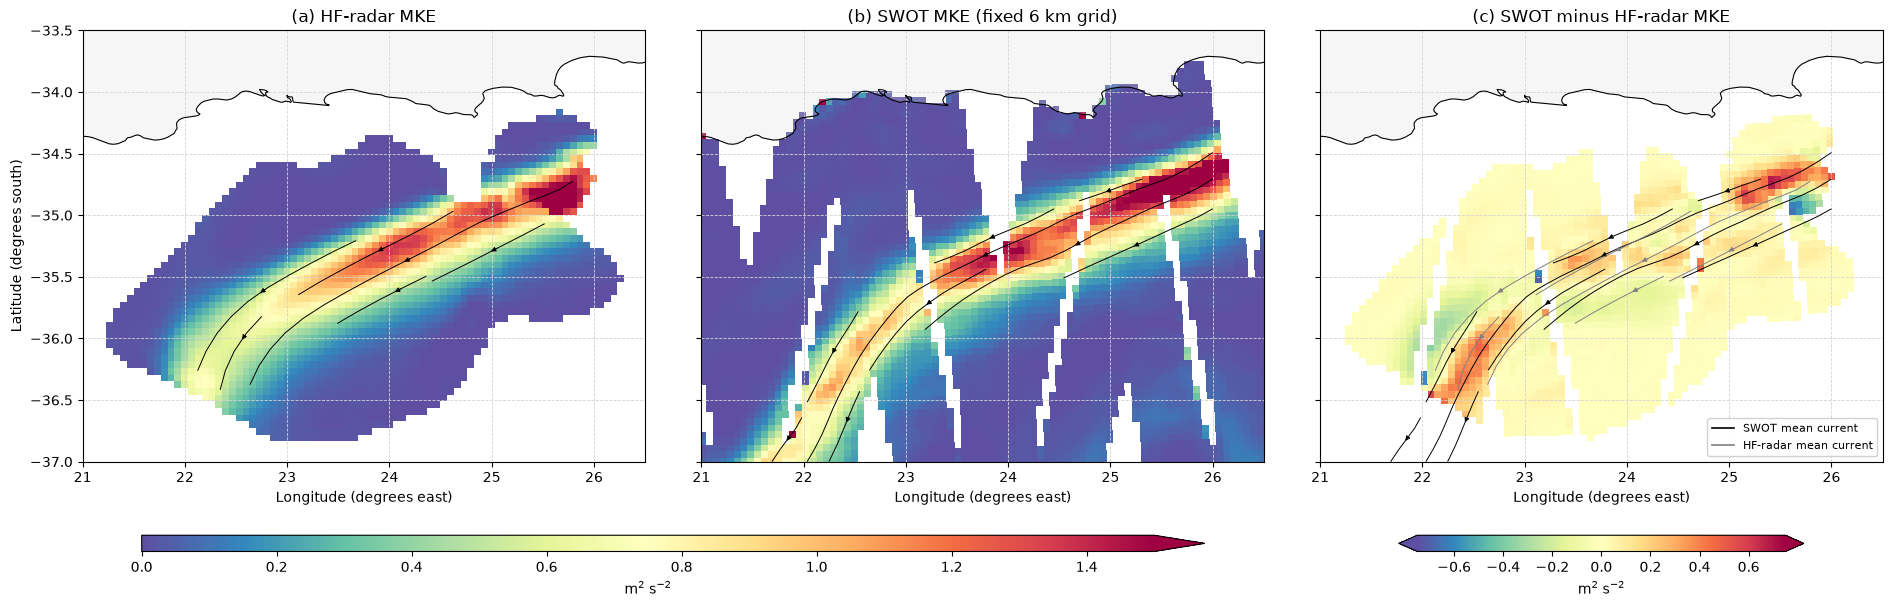

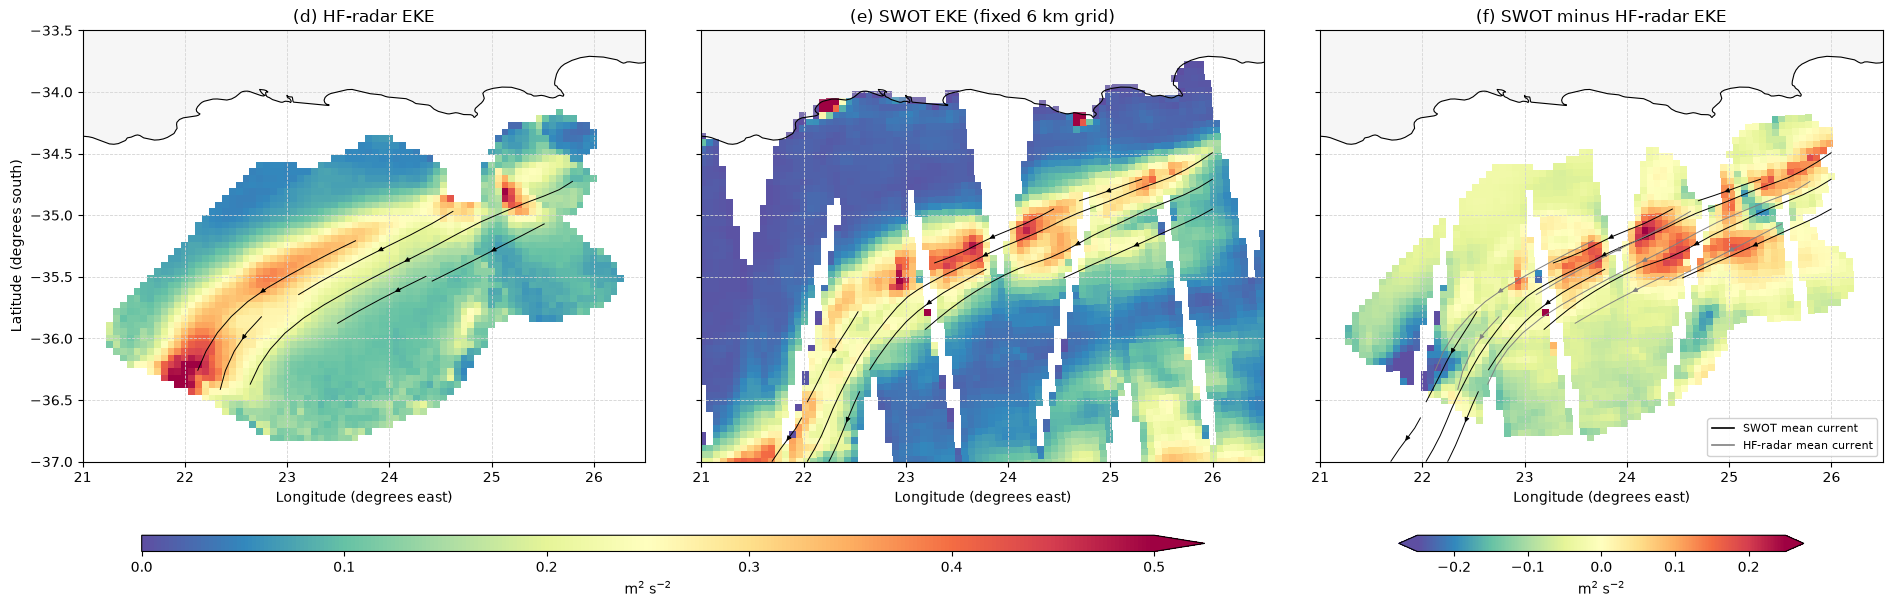

In [94]:
# Compare HF-radar fields with SWOT MKE/EKE calculated directly on the fixed 6 km grid.
# HF fields are evaluated on the SWOT grid only for the difference panels; SWOT NaNs
# remain NaN and are never filled by nearest-neighbour extrapolation.

import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from shapely.geometry import box

HF_ENERGY_MIN_SNAPSHOTS = 50

with xr.open_zarr(zarr_path, consolidated=True) as hf_archive:
    hf_u = hf_archive['ewct']
    hf_v = hf_archive['nsct']
    hf_u_mean = hf_u.mean('time', skipna=True)
    hf_v_mean = hf_v.mean('time', skipna=True)
    hf_ke_ds = xr.Dataset({
        'mke': 0.5 * (hf_u_mean**2 + hf_v_mean**2),
        'eke': 0.5 * (
            ((hf_u - hf_u_mean) ** 2).mean('time', skipna=True)
            + ((hf_v - hf_v_mean) ** 2).mean('time', skipna=True)
        ),
        'u_mean': hf_u_mean,
        'v_mean': hf_v_mean,
        'snapshot_count': (hf_u.notnull() & hf_v.notnull()).sum('time'),
    }).compute()
    hf_lon2d, hf_lat2d = np.meshgrid(
        np.asarray(hf_archive['longitude'].values, dtype=float),
        np.asarray(hf_archive['latitude'].values, dtype=float),
    )

swot_archive = xr.open_zarr(swot_out_zarr_path, consolidated=True)
swot_ke_ds_loaded = swot_archive[['mke', 'eke', 'grid_latitude', 'grid_longitude']]

swot_lon2d = swot_ke_ds_loaded['grid_longitude'].values
swot_lat2d = swot_ke_ds_loaded['grid_latitude'].values
swot_mke = swot_ke_ds_loaded['mke'].values
swot_eke = swot_ke_ds_loaded['eke'].values
hf_energy_coverage = hf_ke_ds['snapshot_count'] >= HF_ENERGY_MIN_SNAPSHOTS
hf_mke = hf_ke_ds['mke'].where(hf_energy_coverage).values
hf_eke = hf_ke_ds['eke'].where(hf_energy_coverage).values
hf_u_mean = hf_ke_ds['u_mean'].where(hf_energy_coverage).values
hf_v_mean = hf_ke_ds['v_mean'].where(hf_energy_coverage).values

if {'u_mean', 'v_mean'}.issubset(swot_archive.data_vars):
    swot_u_mean = swot_archive['u_mean'].values
    swot_v_mean = swot_archive['v_mean'].values
else:
    swot_u_mean = np.full((n_y, n_x), np.nan, dtype='float32')
    swot_v_mean = np.full((n_y, n_x), np.nan, dtype='float32')
    swot_u_sum = np.zeros((n_y, n_x), dtype='float64')
    swot_v_sum = np.zeros((n_y, n_x), dtype='float64')
    swot_vector_count = np.zeros((n_y, n_x), dtype='int32')
    swot_cell_ids = np.stack(
        [
            grid_cell_ids(
                swot_out_ds.longitude.isel(time=time_index).compute().values,
                swot_out_ds.latitude.isel(time=time_index).compute().values,
            )
            for time_index in range(swot_out_ds.sizes['time'])
        ]
    )
    for time_index in range(swot_out_ds.sizes['time']):
        u_values = swot_out_ds['ugos_filtered'].isel(time=time_index).compute().values.ravel()
        v_values = swot_out_ds['vgos_filtered'].isel(time=time_index).compute().values.ravel()
        cell_ids = swot_cell_ids[time_index]
        valid = np.isfinite(u_values) & np.isfinite(v_values) & (cell_ids >= 0)
        if valid.any():
            valid_cells = cell_ids[valid]
            swot_u_sum += np.bincount(
                valid_cells,
                weights=u_values[valid],
                minlength=n_y * n_x,
            ).reshape(n_y, n_x)
            swot_v_sum += np.bincount(
                valid_cells,
                weights=v_values[valid],
                minlength=n_y * n_x,
            ).reshape(n_y, n_x)
            swot_vector_count += np.bincount(
                valid_cells,
                minlength=n_y * n_x,
            ).reshape(n_y, n_x)
    valid_mean = swot_vector_count > 0
    swot_u_mean[valid_mean] = (swot_u_sum[valid_mean] / swot_vector_count[valid_mean]).astype('float32')
    swot_v_mean[valid_mean] = (swot_v_sum[valid_mean] / swot_vector_count[valid_mean]).astype('float32')

land_path = repo_root / 'data/raw/basemaps/ne_10m_land.zip'
land = gpd.read_file(land_path).clip(box(lon_min, lat_min, lon_max, lat_max))


def hf_energy_coverage_on_grid(longitude, latitude):
    """Preserve excluded HF-radar cells when interpolating to another grid."""
    coverage = griddata(
        np.column_stack((hf_lon2d.ravel(), hf_lat2d.ravel())),
        hf_energy_coverage.values.ravel().astype(float),
        (longitude, latitude),
        method='nearest',
    )
    return (
        (coverage > 0.5)
        & (longitude >= hf_lon2d.min()) & (longitude <= hf_lon2d.max())
        & (latitude >= hf_lat2d.min()) & (latitude <= hf_lat2d.max())
    )


def evaluate_hf_on_swot_grid(source_values):
    """Linearly evaluate HF values on the fixed SWOT grid, leaving gaps as NaN."""
    valid = np.isfinite(hf_lon2d) & np.isfinite(hf_lat2d) & np.isfinite(source_values)
    interpolated = griddata(
        np.column_stack((hf_lon2d[valid], hf_lat2d[valid])),
        source_values[valid],
        (swot_lon2d, swot_lat2d),
        method='linear',
    ).astype('float32')
    interpolated[~hf_energy_coverage_on_grid(swot_lon2d, swot_lat2d)] = np.nan
    return interpolated


def regularise_vectors(longitude, latitude, u_velocity, v_velocity):
    """Interpolate vector components onto a regular plotting grid."""
    valid = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & np.isfinite(u_velocity)
        & np.isfinite(v_velocity)
    )
    regular_longitude = np.linspace(lon_min, lon_max, 80)
    regular_latitude = np.linspace(lat_min, lat_max, 60)
    regular_lon2d, regular_lat2d = np.meshgrid(regular_longitude, regular_latitude)
    points = np.column_stack((longitude[valid], latitude[valid]))
    regular_u = griddata(points, u_velocity[valid], (regular_lon2d, regular_lat2d), method='linear')
    regular_v = griddata(points, v_velocity[valid], (regular_lon2d, regular_lat2d), method='linear')
    speed = np.hypot(regular_u, regular_v)
    outside_coverage = ~hf_energy_coverage_on_grid(regular_lon2d, regular_lat2d)
    regular_u[outside_coverage] = np.nan
    regular_v[outside_coverage] = np.nan
    regular_u[speed <= 0.75] = np.nan
    regular_v[speed <= 0.75] = np.nan
    return regular_longitude, regular_latitude, regular_u, regular_v


hf_mke_on_swot = evaluate_hf_on_swot_grid(hf_mke)
hf_eke_on_swot = evaluate_hf_on_swot_grid(hf_eke)
mke_diff = swot_mke - hf_mke_on_swot
eke_diff = swot_eke - hf_eke_on_swot
hf_streamline_grid = regularise_vectors(hf_lon2d, hf_lat2d, hf_u_mean, hf_v_mean)
swot_streamline_grid = (
    streamline_longitude,
    streamline_latitude,
    stream_u,
    stream_v,
)


def plot_energy_row(fields, titles, energy_limits, difference_limits):
    """Plot energy fields with thresholded mean-flow streamlines."""
    figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
    panel_data = [
        (fields[0], hf_lon2d, hf_lat2d, titles[0], 'Spectral_r', energy_limits, hf_streamline_grid),
        (fields[1], swot_lon2d, swot_lat2d, titles[1], 'Spectral_r', energy_limits, swot_streamline_grid),
        (fields[2], swot_lon2d, swot_lat2d, titles[2], 'Spectral_r', difference_limits, swot_streamline_grid),
    ]

    for panel_index, (axis, (field, longitude, latitude, title, cmap, limits, streamline_grid)) in enumerate(
        zip(axes, panel_data)
    ):
        land.plot(ax=axis, color='gainsboro', alpha=0.25, zorder=2)
        land.boundary.plot(ax=axis, color='black', linewidth=0.8, zorder=3)
        axis.pcolormesh(
            longitude,
            latitude,
            field,
            cmap=cmap,
            vmin=limits[0],
            vmax=limits[1],
            shading='auto',
            zorder=1,
        )
        stream_longitude, stream_latitude, stream_u, stream_v = streamline_grid
        axis.streamplot(
            stream_longitude,
            stream_latitude,
            stream_u,
            stream_v,
            color='black',
            linewidth=0.7,
            density=1.0,
            arrowsize=0.7,
            zorder=4,
        )
        if panel_index == 2:
            hf_stream_longitude, hf_stream_latitude, hf_stream_u, hf_stream_v = hf_streamline_grid
            axis.streamplot(
                hf_stream_longitude,
                hf_stream_latitude,
                hf_stream_u,
                hf_stream_v,
                color='grey',
                linewidth=0.7,
                density=1.0,
                arrowsize=0.7,
                zorder=4,
            )
            axis.legend(
                handles=[
                    plt.Line2D([], [], color='black', linewidth=1.2, label='SWOT mean current'),
                    plt.Line2D([], [], color='grey', linewidth=1.2, label='HF-radar mean current'),
                ],
                loc='lower right',
                fontsize=8,
                framealpha=0.9,
            )
        axis.set_xlim(21.0, 26.5)
        axis.set_ylim(-37.0, -33.5)
        axis.set_title(title)
        axis.set_xlabel('Longitude (degrees east)')
        axis.grid(color='lightgrey', linestyle='--', linewidth=0.6)

    axes[0].set_ylabel('Latitude (degrees south)')
    figure.subplots_adjust(
        left=0.05,
        right=0.95,
        bottom=0.20,
        top=0.88,
        wspace=0.10,
    )

    first_axis_position = axes[0].get_position()
    second_axis_position = axes[1].get_position()
    difference_axis_position = axes[2].get_position()
    magnitude_span_left = first_axis_position.x0
    magnitude_span_right = second_axis_position.x1
    magnitude_span_width = magnitude_span_right - magnitude_span_left
    magnitude_width = 0.90 * magnitude_span_width
    magnitude_left = magnitude_span_left + 0.5 * (magnitude_span_width - magnitude_width)
    difference_width = difference_axis_position.width * 0.72
    difference_left = difference_axis_position.x0 + 0.5 * (
        difference_axis_position.width - difference_width
    )
    colourbar_bottom = 0.07
    colourbar_height = 0.025

    magnitude_colourbar_axis = figure.add_axes(
        [magnitude_left, colourbar_bottom, magnitude_width, colourbar_height]
    )
    difference_colourbar_axis = figure.add_axes(
        [difference_left, colourbar_bottom, difference_width, colourbar_height]
    )
    magnitude_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=energy_limits[0], vmax=energy_limits[1]),
        cmap='Spectral_r',
    )
    difference_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=difference_limits[0], vmax=difference_limits[1]),
        cmap='Spectral_r',
    )
    figure.colorbar(
        magnitude_mappable,
        cax=magnitude_colourbar_axis,
        orientation='horizontal',
        label=r'm$^2$ s$^{-2}$',
        extend='max',
    )
    figure.colorbar(
        difference_mappable,
        cax=difference_colourbar_axis,
        orientation='horizontal',
        label=r'm$^2$ s$^{-2}$',
        extend='both',
    )
    return figure


mke_figure = plot_energy_row(
    (hf_mke, swot_mke, mke_diff),
    ('(a) HF-radar MKE', '(b) SWOT MKE (fixed 6 km grid)', '(c) SWOT minus HF-radar MKE'),
    (0.0, 1.5),
    (-0.75, 0.75),
)
eke_figure = plot_energy_row(
    (hf_eke, swot_eke, eke_diff),
    ('(d) HF-radar EKE', '(e) SWOT EKE (fixed 6 km grid)', '(f) SWOT minus HF-radar EKE'),
    (0.0, 0.5),
    (-0.25, 0.25),
)

plt.show()

Figure 4. Spatial comparison of mean kinetic energy (MKE; top row) and eddy kinetic energy (EKE; bottom row) derived from HF-radar observations (left), SWOT observations on the 6 km HF-radar grid (centre), and their difference (SWOT minus HF-radar; right). Colours show kinetic energy in m² s⁻². HF-radar fields and differences exclude cells with fewer than 50 valid HF-radar snapshots. Streamlines indicate mean currents exceeding 0.75 m s⁻¹.

## Near-inertial motion in HF radar

This analysis tests whether near-inertial oscillations are stronger relative to the background current in weak-flow regions and weaker in strong-flow regions. It uses HF-radar observations only; the existing SWOT agreement results provide context but are not recalculated here.

Irregular sampling is retained in the harmonic fits. Candidate windows are screened by their valid-sample support and fit conditioning rather than by requiring a continuous record. K1 is included as a nuisance constituent because its frequency is close to the local inertial frequency.

In [78]:
# Audit native HF-radar sampling support in non-overlapping 14-day windows.
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
INERTIAL_ZARR_PATH = repo_root / 'data/processed/hf_radar.zarr'
INERTIAL_BBOX = (20.0, 28.0, -38.0, -33.0)
INERTIAL_WINDOW_DAYS = 14
INERTIAL_OCCUPANCY_THRESHOLDS = (0.25, 0.50)
INERTIAL_FLOW_EDGES = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0, np.inf])
INERTIAL_FLOW_LABELS = ['<0.25', '0.25-0.50', '0.50-1.00', '1.00-1.50', '1.50-2.00', '>=2.00']

if not INERTIAL_ZARR_PATH.exists():
    raise FileNotFoundError(f'HF-radar Zarr archive not found: {INERTIAL_ZARR_PATH}')

inertial_ds = xr.open_zarr(INERTIAL_ZARR_PATH, consolidated=True, chunks=None)
inertial_longitude = np.asarray(inertial_ds['longitude'].values, dtype=float)
inertial_latitude = np.asarray(inertial_ds['latitude'].values, dtype=float)
inertial_lon_index = np.flatnonzero(
    (inertial_longitude >= INERTIAL_BBOX[0]) & (inertial_longitude <= INERTIAL_BBOX[1])
)
inertial_lat_index = np.flatnonzero(
    (inertial_latitude >= INERTIAL_BBOX[2]) & (inertial_latitude <= INERTIAL_BBOX[3])
)
inertial_times = pd.DatetimeIndex(pd.to_datetime(inertial_ds['time'].values))
inertial_cadence = pd.Timedelta(minutes=30)
inertial_window = pd.Timedelta(days=INERTIAL_WINDOW_DAYS)
inertial_window_starts = pd.date_range(
    inertial_times[0],
    inertial_times[-1] - inertial_window + inertial_cadence,
    freq=inertial_window,
)

inertial_coverage_rows = []
for window_start in inertial_window_starts:
    window_end = window_start + inertial_window
    first_index = inertial_times.searchsorted(window_start, side='left')
    last_index = inertial_times.searchsorted(window_end, side='left')
    if first_index == last_index:
        continue

    radar_u_window = np.asarray(
        inertial_ds['ewct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    radar_v_window = np.asarray(
        inertial_ds['nsct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    valid_window = (
        np.isfinite(radar_u_window) & np.isfinite(radar_v_window)
        & (np.abs(radar_u_window) < 10.0) & (np.abs(radar_v_window) < 10.0)
    )
    sample_count = valid_window.sum(axis=0)
    sum_u = np.where(valid_window, radar_u_window, 0.0).sum(axis=0)
    sum_v = np.where(valid_window, radar_v_window, 0.0).sum(axis=0)
    mean_u = np.divide(sum_u, sample_count, out=np.full(sample_count.shape, np.nan), where=sample_count > 0)
    mean_v = np.divide(sum_v, sample_count, out=np.full(sample_count.shape, np.nan), where=sample_count > 0)
    provisional_flow_speed = np.hypot(mean_u, mean_v).ravel()
    sample_count = sample_count.ravel()
    expected_samples = int(inertial_window / inertial_cadence)

    for occupancy_threshold in INERTIAL_OCCUPANCY_THRESHOLDS:
        eligible = (
            (sample_count >= occupancy_threshold * expected_samples)
            & np.isfinite(provisional_flow_speed)
        )
        flow_counts, _ = np.histogram(
            provisional_flow_speed[eligible], bins=INERTIAL_FLOW_EDGES,
        )
        inertial_coverage_rows.append({
            'window_start': window_start,
            'minimum_occupancy': occupancy_threshold,
            'eligible_cells': int(eligible.sum()),
            **dict(zip(INERTIAL_FLOW_LABELS, flow_counts.astype(int))),
        })

inertial_coverage = pd.DataFrame(inertial_coverage_rows)
inertial_support_summary = (
    inertial_coverage.groupby('minimum_occupancy')[
        ['eligible_cells', *INERTIAL_FLOW_LABELS]
    ].sum()
)
print(
    f'{len(inertial_window_starts)} complete {INERTIAL_WINDOW_DAYS}-day windows; '
    f'{len(inertial_lat_index) * len(inertial_lon_index):,} native cells in the study region.'
)
print('The flow-speed counts below are a screening estimate from each window mean;')
print('final flow classes will use the fitted background-current term.')
display(inertial_support_summary)

37 complete 14-day windows; 9,000 native cells in the study region.
The flow-speed counts below are a screening estimate from each window mean;
final flow classes will use the fitted background-current term.


,eligible_cells,<0.25,0.25-0.50,0.50-1.00,1.00-1.50,1.50-2.00,>=2.00
minimum_occupancy,,,,,,,
0.25,16044,5414,2143,3557,3425,1443,62
0.50,9217,3840,881,1753,2038,692,13


In [79]:
# Fit complex rotary harmonics at the actual observation times.
import numpy as np
import pandas as pd

INERTIAL_OMEGA_EARTH = 7.2921159e-5
INERTIAL_K1_PERIOD_HOURS = 23.934472
INERTIAL_O1_PERIOD_HOURS = 25.819342
INERTIAL_MAX_CONDITION_NUMBER = 1e6


def fit_inertial_rotary(
    u, v, times, latitude_degrees, inertial_frequency_factor=1.0,
    window_days=INERTIAL_WINDOW_DAYS, include_o1=False,
):
    """Fit inertial and tidal rotary components without filling temporal gaps."""
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    times = pd.DatetimeIndex(pd.to_datetime(times)).as_unit('ns')
    valid = np.isfinite(u) & np.isfinite(v)
    u = u[valid]
    v = v[valid]
    times = times[valid]
    if u.size < 12:
        raise ValueError('At least 12 valid vectors are required for the harmonic fit.')

    elapsed_seconds = (times.asi8 - times.asi8.mean()) / 1e9
    trend = elapsed_seconds / (float(window_days) * 86400.0)
    local_coriolis = 2.0 * INERTIAL_OMEGA_EARTH * np.sin(np.deg2rad(latitude_degrees))
    inertial_omega = abs(local_coriolis) * float(inertial_frequency_factor)
    k1_omega = 2.0 * np.pi / (INERTIAL_K1_PERIOD_HOURS * 3600.0)
    columns = [
        np.ones(u.size, dtype=complex), trend,
        np.exp(1j * inertial_omega * elapsed_seconds),
        np.exp(-1j * inertial_omega * elapsed_seconds),
        np.exp(1j * k1_omega * elapsed_seconds),
        np.exp(-1j * k1_omega * elapsed_seconds),
    ]
    control_indices = [0, 1, 4, 5]
    if include_o1:
        o1_omega = 2.0 * np.pi / (INERTIAL_O1_PERIOD_HOURS * 3600.0)
        columns.extend((
            np.exp(1j * o1_omega * elapsed_seconds),
            np.exp(-1j * o1_omega * elapsed_seconds),
        ))
        control_indices.extend((6, 7))
    design = np.column_stack(columns)
    control_design = design[:, control_indices]
    observed = u + 1j * v
    coefficients, _, rank, singular_values = np.linalg.lstsq(design, observed, rcond=None)
    fitted = design @ coefficients
    control_coefficients, _, control_rank, _ = np.linalg.lstsq(control_design, observed, rcond=None)
    control_residual = observed - control_design @ control_coefficients
    residual = observed - fitted
    residual_sum_squares = float(np.sum(np.abs(residual) ** 2))
    control_sum_squares = float(np.sum(np.abs(control_residual) ** 2))
    condition_number = (
        float(singular_values[0] / singular_values[-1])
        if singular_values.size and singular_values[-1] > 0 else np.inf
    )
    total_sum_squares = float(np.sum(np.abs(observed - observed.mean()) ** 2))
    return {
        'background_u': float(coefficients[0].real),
        'background_v': float(coefficients[0].imag),
        'background_speed': float(abs(coefficients[0])),
        'inertial_ccw_amplitude': float(abs(coefficients[2])),
        'inertial_cw_amplitude': float(abs(coefficients[3])),
        'k1_ccw_amplitude': float(abs(coefficients[4])),
        'k1_cw_amplitude': float(abs(coefficients[5])),
        'partial_inertial_r2': (
            1.0 - residual_sum_squares / control_sum_squares
            if control_sum_squares > 0 else np.nan
        ),
        'model_r2': (
            1.0 - residual_sum_squares / total_sum_squares
            if total_sum_squares > 0 else np.nan
        ),
        'condition_number': condition_number,
        'rank': int(rank),
        'control_rank': int(control_rank),
        'sample_count': int(u.size),
        'inertial_frequency_factor': float(inertial_frequency_factor),
        'window_days': float(window_days),
        'include_o1': bool(include_o1),
    }


# Verify the local inertial period and rotary-sign convention on known signals.
synthetic_times = pd.date_range('2025-01-01', periods=672, freq='30min').as_unit('ns')
synthetic_seconds = (synthetic_times.asi8 - synthetic_times.asi8.mean()) / 1e9
synthetic_omega = abs(
    2.0 * INERTIAL_OMEGA_EARTH * np.sin(np.deg2rad(-35.0))
)
synthetic_period_hours = 2.0 * np.pi / synthetic_omega / 3600.0
assert 20.5 < synthetic_period_hours < 21.5
synthetic_w = (
    0.12 + 0.08j
    + 0.80 * np.exp(1j * synthetic_omega * synthetic_seconds)
    + 0.05 * np.exp(-1j * synthetic_omega * synthetic_seconds)
    + 0.15 * np.exp(2j * np.pi * synthetic_seconds / (INERTIAL_K1_PERIOD_HOURS * 3600.0))
)
synthetic_fit = fit_inertial_rotary(
    synthetic_w.real, synthetic_w.imag, synthetic_times, -35.0,
)
synthetic_fit_short = fit_inertial_rotary(
    synthetic_w.real, synthetic_w.imag, synthetic_times, -35.0, window_days=7,
)
synthetic_fit_o1 = fit_inertial_rotary(
    synthetic_w.real, synthetic_w.imag, synthetic_times, -35.0, include_o1=True,
)
assert np.isclose(synthetic_fit['inertial_ccw_amplitude'], 0.80, atol=1e-8)
assert np.isclose(synthetic_fit['inertial_cw_amplitude'], 0.05, atol=1e-8)
assert np.isclose(synthetic_fit_short['inertial_ccw_amplitude'], 0.80, atol=1e-8)
assert np.isclose(synthetic_fit_o1['inertial_ccw_amplitude'], 0.80, atol=1e-8)
assert synthetic_fit['rank'] == synthetic_fit_short['rank'] == 6
assert synthetic_fit_o1['rank'] == 8
assert np.isfinite(synthetic_fit_o1['condition_number'])
print(f'Synthetic rotary fit passed at {synthetic_period_hours:.2f} h.')

Synthetic rotary fit passed at 20.86 h.


In [80]:
# Fit the primary 14-day window set at cells with at least 50% valid samples.
INERTIAL_MINIMUM_OCCUPANCY = 0.50
inertial_fit_rows = []
inertial_candidate_count = 0

for window_start in inertial_window_starts:
    window_end = window_start + inertial_window
    first_index = inertial_times.searchsorted(window_start, side='left')
    last_index = inertial_times.searchsorted(window_end, side='left')
    window_times = inertial_times[first_index:last_index]
    if window_times.empty:
        continue

    radar_u_window = np.asarray(
        inertial_ds['ewct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    radar_v_window = np.asarray(
        inertial_ds['nsct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    valid_window = (
        np.isfinite(radar_u_window) & np.isfinite(radar_v_window)
        & (np.abs(radar_u_window) < 10.0) & (np.abs(radar_v_window) < 10.0)
    )
    sample_count = valid_window.sum(axis=0)
    minimum_samples = int(
        INERTIAL_MINIMUM_OCCUPANCY * INERTIAL_WINDOW_DAYS * 48
    )
    candidate_indices = np.argwhere(sample_count >= minimum_samples)
    inertial_candidate_count += len(candidate_indices)

    for latitude_index, longitude_index in candidate_indices:
        cell_valid = valid_window[:, latitude_index, longitude_index]
        fit = fit_inertial_rotary(
            radar_u_window[cell_valid, latitude_index, longitude_index],
            radar_v_window[cell_valid, latitude_index, longitude_index],
            window_times[cell_valid],
            inertial_latitude[inertial_lat_index[latitude_index]],
        )
        accepted = (
            fit['rank'] == 6
            and fit['control_rank'] == 4
            and fit['condition_number'] <= INERTIAL_MAX_CONDITION_NUMBER
        )
        inertial_fit_rows.append({
            'window_start': window_start,
            'latitude': float(inertial_latitude[inertial_lat_index[latitude_index]]),
            'longitude': float(inertial_longitude[inertial_lon_index[longitude_index]]),
            'sample_count': fit['sample_count'],
            'sample_fraction': fit['sample_count'] / (INERTIAL_WINDOW_DAYS * 48),
            **fit,
            'fit_accepted': accepted,
        })

inertial_fit_results = pd.DataFrame(inertial_fit_rows)
inertial_fits = inertial_fit_results.loc[inertial_fit_results['fit_accepted']].copy()
print(f'Candidate cell-windows with >=50% occupancy: {inertial_candidate_count:,}')
print(f'Full-rank, conditioned fits retained: {len(inertial_fits):,}')
print(f'Rejected for rank or condition number: {inertial_candidate_count - len(inertial_fits):,}')
if not inertial_fits.empty:
    display(inertial_fits[['sample_count', 'sample_fraction', 'condition_number']].describe().round(2))

Candidate cell-windows with >=50% occupancy: 9,217
Full-rank, conditioned fits retained: 9,217
Rejected for rank or condition number: 0


,sample_count,sample_fraction,condition_number
count,9217.00,9217.00,9217.00
mean,503.33,0.75,4.13
std,101.27,0.15,0.65
min,336.00,0.50,3.47
25%,409.00,0.61,3.73
50%,507.00,0.75,3.91
75%,596.00,0.89,4.28
max,672.00,1.00,7.04


Each cell contributes once per flow bin; intervals are the across-cell IQR.


,cells,cell_windows,background_speed_median,ccw_amplitude_median,ccw_amplitude_q25,ccw_amplitude_q75,cw_amplitude_median,relative_amplitude_median,partial_inertial_r2_median
flow_bin,,,,,,,,,
<0.25,455,3844,0.116,0.069,0.054,0.078,0.016,0.556,0.046
0.25-0.50,369,872,0.361,0.058,0.039,0.079,0.021,0.164,0.021
0.50-1.00,489,1741,0.785,0.051,0.039,0.065,0.027,0.064,0.017
1.00-1.50,416,2053,1.219,0.044,0.035,0.055,0.031,0.036,0.012
1.50-2.00,183,692,1.622,0.037,0.026,0.047,0.031,0.023,0.011
>=2.00,13,15,2.019,0.022,0.019,0.031,0.024,0.011,0.005


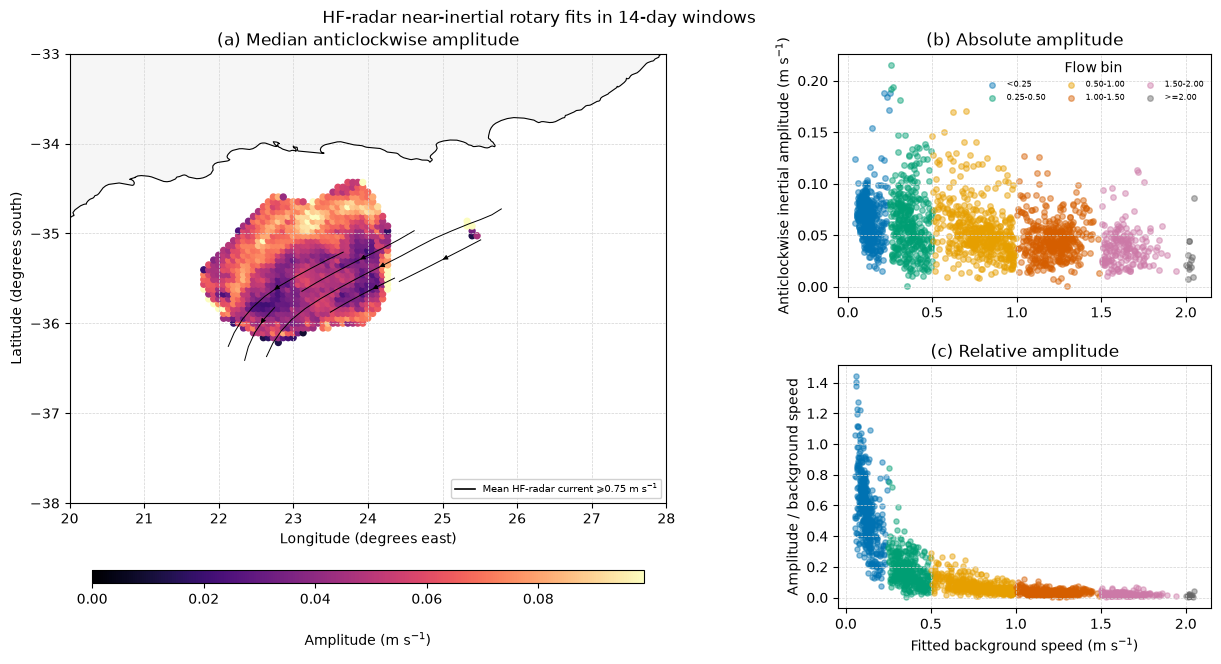

In [82]:
# Summarise inertial amplitude by fitted background-current speed.
import matplotlib.pyplot as plt

INERTIAL_FLOW_COLOURS = {
    '<0.25': '#0072B2',
    '0.25-0.50': '#009E73',
    '0.50-1.00': '#E69F00',
    '1.00-1.50': '#D55E00',
    '1.50-2.00': '#CC79A7',
    '>=2.00': '#666666',
}
inertial_fits['flow_bin'] = pd.cut(
    inertial_fits['background_speed'],
    bins=INERTIAL_FLOW_EDGES,
    labels=INERTIAL_FLOW_LABELS,
    right=False,
    include_lowest=True,
)
inertial_fits['relative_inertial_amplitude'] = np.nan
relative_valid = inertial_fits['background_speed'] >= 0.05
inertial_fits.loc[relative_valid, 'relative_inertial_amplitude'] = (
    inertial_fits.loc[relative_valid, 'inertial_ccw_amplitude']
    / inertial_fits.loc[relative_valid, 'background_speed']
)

# Reduce repeated windows to one median per cell and flow bin.
inertial_cell_bins = (
    inertial_fits.groupby(
        ['flow_bin', 'latitude', 'longitude'], observed=True, as_index=False,
    )
    .agg(
        background_speed=('background_speed', 'median'),
        ccw_amplitude=('inertial_ccw_amplitude', 'median'),
        cw_amplitude=('inertial_cw_amplitude', 'median'),
        relative_amplitude=('relative_inertial_amplitude', 'median'),
        partial_inertial_r2=('partial_inertial_r2', 'median'),
        window_count=('window_start', 'size'),
    )
)
inertial_speed_summary = (
    inertial_cell_bins.groupby('flow_bin', observed=True)
    .agg(
        cells=('latitude', 'size'),
        cell_windows=('window_count', 'sum'),
        background_speed_median=('background_speed', 'median'),
        ccw_amplitude_median=('ccw_amplitude', 'median'),
        ccw_amplitude_q25=('ccw_amplitude', lambda values: values.quantile(0.25)),
        ccw_amplitude_q75=('ccw_amplitude', lambda values: values.quantile(0.75)),
        cw_amplitude_median=('cw_amplitude', 'median'),
        relative_amplitude_median=('relative_amplitude', 'median'),
        partial_inertial_r2_median=('partial_inertial_r2', 'median'),
    )
)
print('Each cell contributes once per flow bin; intervals are the across-cell IQR.')
display(inertial_speed_summary.round(3))

inertial_cell_map = (
    inertial_fits.groupby(['latitude', 'longitude'], as_index=False)
    .agg(ccw_amplitude=('inertial_ccw_amplitude', 'median'))
)
figure = plt.figure(figsize=(14, 7.3))
layout = figure.add_gridspec(
    2, 2, width_ratios=(1.55, 0.65), height_ratios=(1, 1),
    wspace=0.04, hspace=0.28,
)
map_axis = figure.add_subplot(layout[:, 0])
absolute_axis = figure.add_subplot(layout[0, 1])
relative_axis = figure.add_subplot(layout[1, 1])

land.plot(ax=map_axis, color='gainsboro', alpha=0.25, zorder=2)
map_limit = float(np.nanpercentile(inertial_cell_map['ccw_amplitude'], 98))
map_mesh = map_axis.scatter(
    inertial_cell_map['longitude'], inertial_cell_map['latitude'],
    c=inertial_cell_map['ccw_amplitude'], s=18, cmap='magma',
    vmin=0, vmax=map_limit, zorder=1,
)
land.boundary.plot(ax=map_axis, color='black', linewidth=0.8, zorder=3)
hf_stream_longitude, hf_stream_latitude, hf_stream_u, hf_stream_v = hf_streamline_grid
map_axis.streamplot(
    hf_stream_longitude, hf_stream_latitude, hf_stream_u, hf_stream_v,
    color='black', linewidth=0.7, density=1.0, arrowsize=0.7, zorder=4,
)
map_axis.legend(
    handles=[plt.Line2D([], [], color='black', linewidth=1.2,
                        label='Mean HF-radar current ⩾0.75 m s$^{-1}$')],
    loc='lower right', fontsize=7, framealpha=0.9,
)
map_axis.set_xlim(INERTIAL_BBOX[0], INERTIAL_BBOX[1])
map_axis.set_ylim(INERTIAL_BBOX[2], INERTIAL_BBOX[3])
map_axis.set_xlabel('Longitude (degrees east)')
map_axis.set_ylabel('Latitude (degrees south)')
map_axis.set_title('(a) Median anticlockwise amplitude')
map_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
inertial_map_colorbar = figure.colorbar(
    map_mesh, ax=map_axis, location='bottom', pad=0.12,
    shrink=0.62, fraction=0.07, aspect=40,
)
inertial_map_colorbar.set_label('Amplitude (m s$^{-1}$)', labelpad=18)

for flow_bin, colour in INERTIAL_FLOW_COLOURS.items():
    cell_group = inertial_cell_bins.loc[inertial_cell_bins['flow_bin'] == flow_bin]
    if cell_group.empty:
        continue
    absolute_axis.scatter(
        cell_group['background_speed'], cell_group['ccw_amplitude'],
        s=16, alpha=0.45, color=colour, label=flow_bin,
    )
#absolute_axis.set_xlabel('Fitted background speed (m s$^{-1}$)')
absolute_axis.set_ylabel('Anticlockwise inertial amplitude (m s$^{-1}$)')
absolute_axis.set_title('(b) Absolute amplitude')
absolute_axis.legend(title='Flow bin', fontsize=6, frameon=False, ncol=3)
absolute_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)

relative_cells = inertial_cell_bins.loc[
    inertial_cell_bins['background_speed'] >= 0.05
]
for flow_bin, colour in INERTIAL_FLOW_COLOURS.items():
    cell_group = relative_cells.loc[relative_cells['flow_bin'] == flow_bin]
    if cell_group.empty:
        continue
    relative_axis.scatter(
        cell_group['background_speed'], cell_group['relative_amplitude'],
        s=14, alpha=0.45, color=colour, label=flow_bin,
    )
relative_axis.set_xlabel('Fitted background speed (m s$^{-1}$)')
relative_axis.set_ylabel('Amplitude / background speed')
relative_axis.set_title('(c) Relative amplitude')
relative_axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)

figure.suptitle('HF-radar near-inertial rotary fits in 14-day windows')
figure.subplots_adjust(top=0.92, bottom=0.16, left=0.06, right=0.98)
plt.show()

### Sensitivity to frequency, constituents and window length

The primary estimates use the local Coriolis frequency and K1 as a nuisance constituent in complete 14-day windows. The following checks repeat the fit at frequencies 5% below and above local $|f|$, add O1 as a further nuisance constituent, and use 7-day windows. The shorter windows are a sensitivity analysis because they provide less separation from K1 and O1.

In [83]:
# Test frequency offsets and shorter windows without changing the primary fit set.
INERTIAL_FREQUENCY_SENSITIVITY = (0.95, 1.05)
frequency_sensitivity_rows = []
latitude_index_lookup = {
    float(value): index for index, value in enumerate(inertial_latitude[inertial_lat_index])
}
longitude_index_lookup = {
    float(value): index for index, value in enumerate(inertial_longitude[inertial_lon_index])
}

for window_start, fit_group in inertial_fits.groupby('window_start', sort=True):
    window_end = window_start + inertial_window
    first_index = inertial_times.searchsorted(window_start, side='left')
    last_index = inertial_times.searchsorted(window_end, side='left')
    window_times = inertial_times[first_index:last_index]
    radar_u_window = np.asarray(
        inertial_ds['ewct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    radar_v_window = np.asarray(
        inertial_ds['nsct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    valid_window = (
        np.isfinite(radar_u_window) & np.isfinite(radar_v_window)
        & (np.abs(radar_u_window) < 10.0) & (np.abs(radar_v_window) < 10.0)
    )
    for latitude, longitude in fit_group[['latitude', 'longitude']].itertuples(index=False, name=None):
        latitude_index = latitude_index_lookup[float(latitude)]
        longitude_index = longitude_index_lookup[float(longitude)]
        cell_valid = valid_window[:, latitude_index, longitude_index]
        for frequency_factor in INERTIAL_FREQUENCY_SENSITIVITY:
            fit = fit_inertial_rotary(
                radar_u_window[cell_valid, latitude_index, longitude_index],
                radar_v_window[cell_valid, latitude_index, longitude_index],
                window_times[cell_valid], latitude, frequency_factor,
            )
            frequency_sensitivity_rows.append({
                'window_start': window_start,
                'latitude': latitude,
                'longitude': longitude,
                **fit,
                'fit_accepted': (
                    fit['rank'] == 6
                    and fit['control_rank'] == 4
                    and fit['condition_number'] <= INERTIAL_MAX_CONDITION_NUMBER
                ),
            })

frequency_sensitivity_fits = pd.concat(
    [
        inertial_fits.assign(inertial_frequency_factor=1.0),
        pd.DataFrame(frequency_sensitivity_rows),
    ],
    ignore_index=True,
)
frequency_sensitivity_fits = frequency_sensitivity_fits.loc[
    frequency_sensitivity_fits['fit_accepted']
].copy()
frequency_sensitivity_fits['flow_bin'] = pd.cut(
    frequency_sensitivity_fits['background_speed'],
    bins=INERTIAL_FLOW_EDGES,
    labels=INERTIAL_FLOW_LABELS,
    right=False,
    include_lowest=True,
)
frequency_cell_bins = (
    frequency_sensitivity_fits.groupby(
        ['inertial_frequency_factor', 'flow_bin', 'latitude', 'longitude'],
        observed=True, as_index=False,
    )
    .agg(
        background_speed=('background_speed', 'median'),
        ccw_amplitude=('inertial_ccw_amplitude', 'median'),
        cell_windows=('window_start', 'size'),
    )
)
frequency_summary = (
    frequency_cell_bins.groupby(
        ['inertial_frequency_factor', 'flow_bin'], observed=True,
    )
    .agg(
        cells=('latitude', 'size'),
        cell_windows=('cell_windows', 'sum'),
        background_speed_median=('background_speed', 'median'),
        ccw_amplitude_median=('ccw_amplitude', 'median'),
    )
)
print('Fourteen-day frequency sensitivity; factors are relative to local |f|.')
display(frequency_summary.round(3))

# Repeat the exact-local-frequency fit in 7-day windows as a separation sensitivity.
INERTIAL_SHORT_WINDOW_DAYS = 7
short_window = pd.Timedelta(days=INERTIAL_SHORT_WINDOW_DAYS)
short_window_starts = pd.date_range(
    inertial_times[0],
    inertial_times[-1] + inertial_cadence - short_window,
    freq=short_window,
)
short_window_rows = []
short_candidate_count = 0
short_minimum_samples = int(INERTIAL_MINIMUM_OCCUPANCY * INERTIAL_SHORT_WINDOW_DAYS * 48)

for window_start in short_window_starts:
    window_end = window_start + short_window
    first_index = inertial_times.searchsorted(window_start, side='left')
    last_index = inertial_times.searchsorted(window_end, side='left')
    window_times = inertial_times[first_index:last_index]
    if window_times.empty:
        continue
    radar_u_window = np.asarray(
        inertial_ds['ewct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    radar_v_window = np.asarray(
        inertial_ds['nsct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    valid_window = (
        np.isfinite(radar_u_window) & np.isfinite(radar_v_window)
        & (np.abs(radar_u_window) < 10.0) & (np.abs(radar_v_window) < 10.0)
    )
    candidate_indices = np.argwhere(valid_window.sum(axis=0) >= short_minimum_samples)
    short_candidate_count += len(candidate_indices)

    for latitude_index, longitude_index in candidate_indices:
        cell_valid = valid_window[:, latitude_index, longitude_index]
        latitude = float(inertial_latitude[inertial_lat_index[latitude_index]])
        longitude = float(inertial_longitude[inertial_lon_index[longitude_index]])
        fit = fit_inertial_rotary(
            radar_u_window[cell_valid, latitude_index, longitude_index],
            radar_v_window[cell_valid, latitude_index, longitude_index],
            window_times[cell_valid], latitude, window_days=INERTIAL_SHORT_WINDOW_DAYS,
        )
        short_window_rows.append({
            'window_start': window_start,
            'latitude': latitude,
            'longitude': longitude,
            **fit,
            'fit_accepted': (
                fit['rank'] == 6
                and fit['control_rank'] == 4
                and fit['condition_number'] <= INERTIAL_MAX_CONDITION_NUMBER
            ),
        })

short_window_fits = pd.DataFrame(short_window_rows)
short_window_fits = short_window_fits.loc[short_window_fits['fit_accepted']].copy()
short_window_fits['flow_bin'] = pd.cut(
    short_window_fits['background_speed'],
    bins=INERTIAL_FLOW_EDGES,
    labels=INERTIAL_FLOW_LABELS,
    right=False,
    include_lowest=True,
)
short_cell_bins = (
    short_window_fits.groupby(
        ['flow_bin', 'latitude', 'longitude'], observed=True, as_index=False,
    )
    .agg(
        background_speed=('background_speed', 'median'),
        ccw_amplitude=('inertial_ccw_amplitude', 'median'),
        cell_windows=('window_start', 'size'),
    )
)
short_window_summary = (
    short_cell_bins.groupby('flow_bin', observed=True)
    .agg(
        cells=('latitude', 'size'),
        cell_windows=('cell_windows', 'sum'),
        background_speed_median=('background_speed', 'median'),
        ccw_amplitude_median=('ccw_amplitude', 'median'),
    )
)
print(
    f'Seven-day sensitivity: {short_candidate_count:,} candidates; '
    f'{len(short_window_fits):,} conditioned fits retained.'
)
display(short_window_summary.round(3))

Fourteen-day frequency sensitivity; factors are relative to local |f|.


cells  cell_windows  \
inertial_frequency_factor flow_bin                         
0.95                      <0.25        454          3839   
                          0.25-0.50    371           877   
                          0.50-1.00    488          1744   
                          1.00-1.50    415          2053   
                          1.50-2.00    182           688   
                          >=2.00        14            16   
1.00                      <0.25        455          3844   
                          0.25-0.50    369           872   
                          0.50-1.00    489          1741   
                          1.00-1.50    416          2053   
                          1.50-2.00    183           692   
                          >=2.00        13            15   
1.05                      <0.25        454          3845   
                          0.25-0.50    366           868   
                          0.50-1.00    490          1746   
                          1.00-1.50    415          2059   
                          1.50-2.00    182           684   
                          >=2.00        13            15   

                                     background_speed_median  \
inertial_frequency_factor flow_bin                             
0.95                      <0.25                        0.114   
                          0.25-0.50                    0.360   
                          0.50-1.00                    0.782   
                          1.00-1.50                    1.220   
                          1.50-2.00                    1.621   
                          >=2.00                       2.021   
1.00                      <0.25                        0.116   
                          0.25-0.50                    0.361   
                          0.50-1.00                    0.785   
                          1.00-1.50                    1.219   
                          1.50-2.00                    1.622   
                          >=2.00                       2.019   
1.05                      <0.25                        0.116   
                          0.25-0.50                    0.361   
                          0.50-1.00                    0.784   
                          1.00-1.50                    1.220   
                          1.50-2.00                    1.623   
                          >=2.00                       2.019   

                                     ccw_amplitude_median  
inertial_frequency_factor flow_bin                         
0.95                      <0.25                     0.063  
                          0.25-0.50                 0.059  
                          0.50-1.00                 0.066  
                          1.00-1.50                 0.062  
                          1.50-2.00                 0.046  
                          >=2.00                    0.022  
1.00                      <0.25                     0.069  
                          0.25-0.50                 0.058  
                          0.50-1.00                 0.051  
                          1.00-1.50                 0.044  
                          1.50-2.00                 0.037  
                          >=2.00                    0.022  
1.05                      <0.25                     0.041  
                          0.25-0.50                 0.040  
                          0.50-1.00                 0.032  
                          1.00-1.50                 0.035  
                          1.50-2.00                 0.038  
                          >=2.00                    0.037

Seven-day sensitivity: 20,292 candidates; 20,292 conditioned fits retained.


,cells,cell_windows,background_speed_median,ccw_amplitude_median
flow_bin,,,,
<0.25,534,7256,0.125,0.076
0.25-0.50,614,2910,0.352,0.070
0.50-1.00,705,3795,0.753,0.067
1.00-1.50,530,4117,1.228,0.055
1.50-2.00,348,2056,1.645,0.055
>=2.00,98,158,2.083,0.044


In [84]:
# Repeat the primary 14-day fits with O1 included as an additional nuisance constituent.
o1_sensitivity_rows = []
for window_start, fit_group in inertial_fits.groupby('window_start', sort=True):
    window_end = window_start + inertial_window
    first_index = inertial_times.searchsorted(window_start, side='left')
    last_index = inertial_times.searchsorted(window_end, side='left')
    window_times = inertial_times[first_index:last_index]
    radar_u_window = np.asarray(
        inertial_ds['ewct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    radar_v_window = np.asarray(
        inertial_ds['nsct'].isel(time=slice(first_index, last_index))
        .isel(latitude=inertial_lat_index).isel(longitude=inertial_lon_index).values,
        dtype=float,
    )
    valid_window = (
        np.isfinite(radar_u_window) & np.isfinite(radar_v_window)
        & (np.abs(radar_u_window) < 10.0) & (np.abs(radar_v_window) < 10.0)
    )
    for latitude, longitude in fit_group[['latitude', 'longitude']].itertuples(index=False, name=None):
        latitude_index = latitude_index_lookup[float(latitude)]
        longitude_index = longitude_index_lookup[float(longitude)]
        cell_valid = valid_window[:, latitude_index, longitude_index]
        fit = fit_inertial_rotary(
            radar_u_window[cell_valid, latitude_index, longitude_index],
            radar_v_window[cell_valid, latitude_index, longitude_index],
            window_times[cell_valid], latitude, include_o1=True,
        )
        o1_sensitivity_rows.append({
            'window_start': window_start,
            'latitude': latitude,
            'longitude': longitude,
            **fit,
            'fit_accepted': (
                fit['rank'] == 8
                and fit['control_rank'] == 6
                and fit['condition_number'] <= INERTIAL_MAX_CONDITION_NUMBER
            ),
        })

o1_sensitivity_fits = pd.DataFrame(o1_sensitivity_rows)
o1_sensitivity_fits = o1_sensitivity_fits.loc[
    o1_sensitivity_fits['fit_accepted']
].copy()
o1_sensitivity_fits['flow_bin'] = pd.cut(
    o1_sensitivity_fits['background_speed'],
    bins=INERTIAL_FLOW_EDGES,
    labels=INERTIAL_FLOW_LABELS,
    right=False,
    include_lowest=True,
)
o1_cell_bins = (
    o1_sensitivity_fits.groupby(
        ['flow_bin', 'latitude', 'longitude'], observed=True, as_index=False,
    )
    .agg(
        background_speed=('background_speed', 'median'),
        ccw_amplitude=('inertial_ccw_amplitude', 'median'),
        cell_windows=('window_start', 'size'),
    )
)
o1_sensitivity_summary = (
    o1_cell_bins.groupby('flow_bin', observed=True)
    .agg(
        cells=('latitude', 'size'),
        cell_windows=('cell_windows', 'sum'),
        background_speed_median=('background_speed', 'median'),
        ccw_amplitude_median=('ccw_amplitude', 'median'),
    )
)
print(
    f'O1 sensitivity: {len(o1_sensitivity_fits):,} conditioned fits retained '
    f'from {len(o1_sensitivity_rows):,} candidate cell-windows.'
)
if not o1_sensitivity_fits.empty:
    display(o1_sensitivity_fits['condition_number'].describe().round(2).to_frame())
display(o1_sensitivity_summary.round(3))

O1 sensitivity: 9,217 conditioned fits retained from 9,217 candidate cell-windows.


,condition_number
count,9217.00
mean,4.31
std,0.83
min,3.53
25%,3.79
50%,4.02
75%,4.48
max,8.37


,cells,cell_windows,background_speed_median,ccw_amplitude_median
flow_bin,,,,
<0.25,457,3844,0.117,0.070
0.25-0.50,368,871,0.360,0.058
0.50-1.00,489,1739,0.783,0.051
1.00-1.50,417,2053,1.217,0.044
1.50-2.00,183,696,1.627,0.038
>=2.00,12,14,2.020,0.025


## Wind-conditioned SWOT–HF-radar comparison

This analysis downloads hourly ERA5 10 m winds for the matched SWOT overpass dates and Agulhas comparison domain, collocates them to the matched 6 km grid, and separates comparisons by the sign of the wind projected onto the SWOT current. Run the ERA5 download cell once before the diagnostics cell. CDS credentials are read by `cdsapi` from `~/.cdsapirc`; monthly NetCDF files are cached under `data/raw/era5_hfradar_domain/`.

In [85]:
# Download only the ERA5 hours and domain needed by the matched overpasses.
from collections import defaultdict
from pathlib import Path

import cdsapi
import numpy as np
import pandas as pd
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
era5_output_dir = repo_root / 'data' / 'raw' / 'era5_hfradar_domain'
era5_output_dir.mkdir(parents=True, exist_ok=True)

if not Path.home().joinpath('.cdsapirc').is_file():
    raise FileNotFoundError('CDS API credentials were not found at ~/.cdsapirc.')
if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched-observation archive not found: {matched_zarr_path}')

with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    era5_match_times = pd.DatetimeIndex(pd.to_datetime(matched_ds['swot_time'].values))
    era5_latitude = np.asarray(matched_ds['latitude'].values, dtype=float)
    era5_longitude = np.asarray(matched_ds['longitude'].values, dtype=float)

# Pad dates by one day so nearest-hour matching remains valid across midnight.
era5_requested_days = defaultdict(set)
for match_time in era5_match_times:
    for day_offset in (-1, 0, 1):
        requested_day = (match_time.normalize() + pd.Timedelta(days=day_offset))
        era5_requested_days[(requested_day.year, requested_day.month)].add(requested_day.day)

era5_area = [
    float(era5_latitude.max() + 0.5),
    float(era5_longitude.min() - 0.5),
    float(era5_latitude.min() - 0.5),
    float(era5_longitude.max() + 0.5),
]
era5_client = cdsapi.Client()
era5_files = []
for (request_year, request_month), requested_days in sorted(era5_requested_days.items()):
    era5_path = era5_output_dir / f'era5_agulhas_{request_year:04d}{request_month:02d}.nc'
    era5_files.append(era5_path)
    if era5_path.exists() and era5_path.stat().st_size > 0:
        print(f'Using cached {era5_path.name}')
        continue

    request = {
        'product_type': ['reanalysis'],
        'variable': ['10m_u_component_of_wind', '10m_v_component_of_wind'],
        'year': [f'{request_year:04d}'],
        'month': [f'{request_month:02d}'],
        'day': [f'{day:02d}' for day in sorted(requested_days)],
        'time': [f'{hour:02d}:00' for hour in range(24)],
        'data_format': 'netcdf',
        'download_format': 'unarchived',
        'area': era5_area,
    }
    print(f'Requesting ERA5 for {request_year:04d}-{request_month:02d} ({len(requested_days)} days)')
    era5_client.retrieve('reanalysis-era5-single-levels', request, str(era5_path))

print(f'ERA5 monthly files available: {len(era5_files)}')
print(f'Request area [N, W, S, E]: {era5_area}')

2026-10-15 11:48:04,973 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**


Using cached era5_agulhas_202411.nc
Using cached era5_agulhas_202503.nc
Using cached era5_agulhas_202504.nc
Using cached era5_agulhas_202506.nc
Using cached era5_agulhas_202507.nc
Using cached era5_agulhas_202508.nc
Using cached era5_agulhas_202509.nc
Using cached era5_agulhas_202510.nc
Using cached era5_agulhas_202511.nc
Using cached era5_agulhas_202512.nc
Using cached era5_agulhas_202601.nc
Using cached era5_agulhas_202604.nc
ERA5 monthly files available: 12
Request area [N, W, S, E]: [-33.23002, 18.5, -38.22572400000001, 29.427363399999997]


In [86]:
# Collocate ERA5 winds and prepare inputs for the following/opposing analyses.
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

repo_root = Path(globals().get('repo_root', Path.cwd())).resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
processed_dir = repo_root / 'data' / 'processed'
matched_zarr_path = processed_dir / 'swot_hfradar_zarr_matches.zarr'
era5_output_dir = repo_root / 'data' / 'raw' / 'era5_hfradar_domain'
era5_files = sorted(era5_output_dir.glob('era5_agulhas_*.nc'))
if not matched_zarr_path.exists():
    raise FileNotFoundError(f'Matched-observation archive not found: {matched_zarr_path}')
if not era5_files:
    raise FileNotFoundError('Run the preceding ERA5 download cell before this analysis.')

with xr.open_zarr(matched_zarr_path, consolidated=True) as matched_ds:
    swot_u = np.asarray(matched_ds['ugos_coarsened_masked'].values, dtype=float)
    swot_v = np.asarray(matched_ds['vgos_coarsened_masked'].values, dtype=float)
    radar_u = np.asarray(matched_ds['ewct_masked'].values, dtype=float)
    radar_v = np.asarray(matched_ds['nsct_masked'].values, dtype=float)
    comparison_mask = np.asarray(matched_ds['comparison_mask'].values, dtype=bool)
    swot_match_times = pd.DatetimeIndex(pd.to_datetime(matched_ds['swot_time'].values))
    comparison_latitude = np.asarray(matched_ds['latitude'].values, dtype=float)
    comparison_longitude = np.asarray(matched_ds['longitude'].values, dtype=float)


def normalise_era5_dataset(dataset):
    rename = {}
    if 'valid_time' in dataset.coords and 'time' not in dataset.coords:
        rename['valid_time'] = 'time'
    if 'lat' in dataset.coords and 'latitude' not in dataset.coords:
        rename['lat'] = 'latitude'
    if 'lon' in dataset.coords and 'longitude' not in dataset.coords:
        rename['lon'] = 'longitude'
    if rename:
        dataset = dataset.rename(rename)
    if 'u10' not in dataset.data_vars and '10m_u_component_of_wind' in dataset.data_vars:
        dataset = dataset.rename({'10m_u_component_of_wind': 'u10'})
    if 'v10' not in dataset.data_vars and '10m_v_component_of_wind' in dataset.data_vars:
        dataset = dataset.rename({'10m_v_component_of_wind': 'v10'})
    missing = {'u10', 'v10'} - set(dataset.data_vars)
    if missing:
        raise KeyError(f'ERA5 files are missing wind components: {sorted(missing)}')
    if 'expver' in dataset.dims:
        dataset = dataset.isel(expver=0, drop=True)
    return dataset[['u10', 'v10']]


era5_ds = xr.open_mfdataset(
    era5_files,
    combine='by_coords',
    preprocess=normalise_era5_dataset,
    parallel=False,
).sortby('time').sortby('latitude').sortby('longitude').load()
if era5_ds.indexes['time'].has_duplicates:
    era5_ds = era5_ds.drop_duplicates(dim='time', keep='first')

matched_times_da = xr.DataArray(
    swot_match_times.to_numpy(),
    dims='match',
    coords={'match': np.arange(len(swot_match_times))},
)
wind_at_match_times = era5_ds[['u10', 'v10']].sel(
    time=matched_times_da,
    method='nearest',
    tolerance=pd.Timedelta(minutes=90),
)
wind_on_comparison_grid = wind_at_match_times.interp(
    latitude=comparison_latitude,
    longitude=comparison_longitude,
    method='linear',
)
era5_u10 = np.asarray(wind_on_comparison_grid['u10'].values, dtype=float)
era5_v10 = np.asarray(wind_on_comparison_grid['v10'].values, dtype=float)
era5_ds.close()

swot_speed = np.hypot(swot_u, swot_v)
radar_speed = np.hypot(radar_u, radar_v)
paired_valid = (
    comparison_mask
    & np.isfinite(swot_u)
    & np.isfinite(swot_v)
    & np.isfinite(radar_u)
    & np.isfinite(radar_v)
    & np.isfinite(era5_u10)
    & np.isfinite(era5_v10)
    & (swot_speed >= 0.05)
)
unit_current_u = np.divide(
    swot_u, swot_speed, out=np.full_like(swot_u, np.nan), where=swot_speed > 0,
)
unit_current_v = np.divide(
    swot_v, swot_speed, out=np.full_like(swot_v, np.nan), where=swot_speed > 0,
)
wind_along_current = era5_u10 * unit_current_u + era5_v10 * unit_current_v
signed_speed_difference = swot_speed - radar_speed
following_mask = paired_valid & (wind_along_current > 0)
opposing_mask = paired_valid & (wind_along_current < 0)
wind_class_masks = {'Following': following_mask, 'Opposing': opposing_mask}

In [87]:
# Refit and report the along-current residual regression.
from scipy.stats import linregress

required_regression_variables = (
    'paired_valid', 'wind_along_current', 'radar_u', 'swot_u',
    'unit_current_u', 'unit_current_v',
)
missing_regression_variables = [
    name for name in required_regression_variables if name not in globals()
]
if missing_regression_variables:
    raise RuntimeError(
        'Run the wind-conditioned diagnostics cell first; missing: '
        + ', '.join(missing_regression_variables)
    )

delta_u_along_current = (
    (radar_u - swot_u) * unit_current_u
    + (radar_v - swot_v) * unit_current_v
)
regression_valid = (
    paired_valid
    & np.isfinite(wind_along_current)
    & np.isfinite(delta_u_along_current)
)
regression_x = wind_along_current[regression_valid]
regression_y = delta_u_along_current[regression_valid]

if regression_x.size < 2 or np.unique(regression_x).size < 2:
    raise ValueError('At least two distinct valid along-current wind values are required.')

wind_residual_fit = linregress(regression_x, regression_y)
print(
    'HF-minus-SWOT along-current residual regression on along-current wind:'
)
print(
    f'delta_U_parallel = {wind_residual_fit.slope:+.4f} * U_parallel '
    f'{wind_residual_fit.intercept:+.4f} m/s'
)
print(f'n = {regression_x.size:,}')
print(f'r = {wind_residual_fit.rvalue:+.4f}')
print(f'R-squared = {wind_residual_fit.rvalue**2:.4f}')
print(f'p-value = {wind_residual_fit.pvalue:.4g}')
print(f'slope standard error = {wind_residual_fit.stderr:.4f}')
print(f'intercept standard error = {wind_residual_fit.intercept_stderr:.4f}')
print('This unadjusted cell-level regression is descriptive; observations within overpasses are spatially dependent.')

HF-minus-SWOT along-current residual regression on along-current wind:
delta_U_parallel = +0.0157 * U_parallel -0.0274 m/s
n = 6,276
r = +0.2628
R-squared = 0.0690
p-value = 1.317e-99
slope standard error = 0.0007
intercept standard error = 0.0049
This unadjusted cell-level regression is descriptive; observations within overpasses are spatially dependent.


,wind_class,speed_bin,n,mean_bias_m_s,standard_error_m_s
0,Following,0.00-0.25,549,-0.038038,0.006015
1,Following,0.25-0.50,793,-0.182358,0.007867
2,Following,0.50-1.00,816,-0.289959,0.011701
3,Following,1.00-1.50,590,-0.247397,0.018407
4,Following,1.50-2.00,394,0.004719,0.026255
5,Following,2.00-3.50,179,0.364698,0.052931
6,Opposing,0.00-0.25,650,0.001530,0.005579
7,Opposing,0.25-0.50,778,-0.043519,0.009275
8,Opposing,0.50-1.00,695,-0.096255,0.015355
9,Opposing,1.00-1.50,614,-0.091050,0.015463


,speed_bin,absolute_bias_difference_m_s,standard_error_m_s
0,0.00-0.25,0.040,0.008
1,0.25-0.50,0.139,0.012
2,0.50-1.00,0.194,0.019
3,1.00-1.50,0.156,0.024
4,1.50-2.00,0.060,0.041
5,2.00-3.50,0.095,0.071


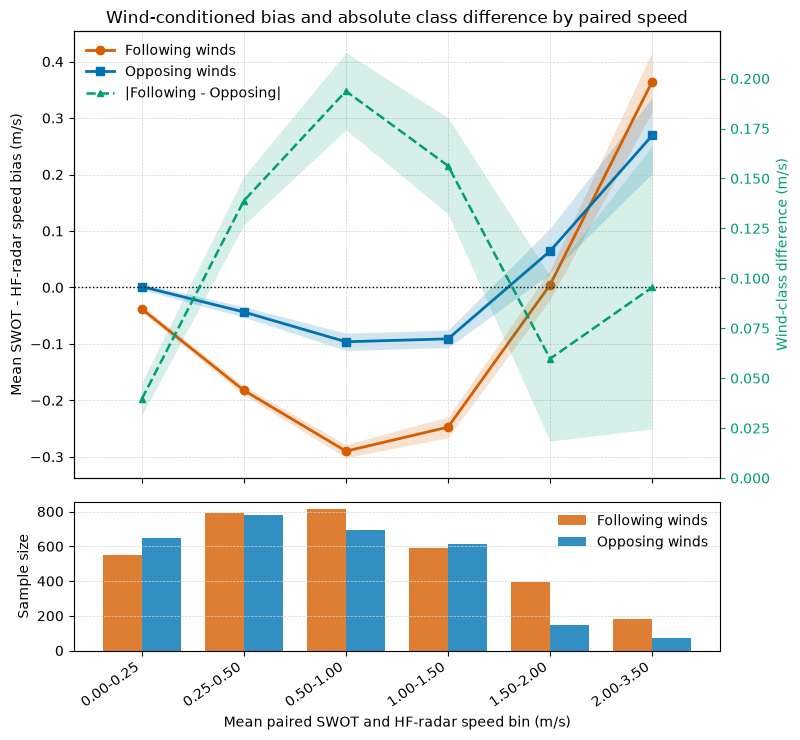

Class-bias shading shows cell-wise SE; absolute-difference shading uses a folded-normal SE approximation.
Uncertainty assumes independent class estimates and does not account for spatial or overpass clustering.


In [88]:
# Compare class-specific mean bias, absolute difference, and sample sizes by speed bin.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import erf

if 'signed_speed_difference' not in globals() or 'wind_class_masks' not in globals():
    raise RuntimeError('Run the wind-conditioned diagnostics cell first.')

mean_pair_speed = 0.5 * (swot_speed + radar_speed)
paired_speed_bin_edges = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.5])
paired_speed_bin_labels = [
    '0.00-0.25', '0.25-0.50', '0.50-1.00',
    '1.00-1.50', '1.50-2.00', '2.00-3.50',
]

wind_bias_rows = []
for wind_class, class_mask in wind_class_masks.items():
    for bin_index, bin_label in enumerate(paired_speed_bin_labels):
        in_bin = (
            (mean_pair_speed >= paired_speed_bin_edges[bin_index])
            & (
                (mean_pair_speed <= paired_speed_bin_edges[bin_index + 1])
                if bin_index == len(paired_speed_bin_labels) - 1
                else (mean_pair_speed < paired_speed_bin_edges[bin_index + 1])
            )
        )
        selected = class_mask & in_bin & np.isfinite(signed_speed_difference)
        bias_values = signed_speed_difference[selected]
        sample_count = bias_values.size
        wind_bias_rows.append({
            'wind_class': wind_class,
            'speed_bin': bin_label,
            'n': sample_count,
            'mean_bias_m_s': float(np.mean(bias_values)) if sample_count else np.nan,
            'standard_error_m_s': (
                float(np.std(bias_values, ddof=1) / np.sqrt(sample_count))
                if sample_count > 1 else np.nan
            ),
        })

wind_bias_by_mean_speed = pd.DataFrame(wind_bias_rows)
wind_bias_summary = wind_bias_by_mean_speed.pivot(
    index='speed_bin', columns='wind_class', values='mean_bias_m_s',
).reindex(paired_speed_bin_labels)
wind_bias_se = wind_bias_by_mean_speed.pivot(
    index='speed_bin', columns='wind_class', values='standard_error_m_s',
).reindex(paired_speed_bin_labels)
wind_counts = wind_bias_by_mean_speed.pivot(
    index='speed_bin', columns='wind_class', values='n',
).reindex(paired_speed_bin_labels)
if not {'Following', 'Opposing'}.issubset(wind_bias_summary.columns):
    raise ValueError('Both following and opposing wind classes are required to plot their difference.')

signed_bias_difference = (
    wind_bias_summary['Following'] - wind_bias_summary['Opposing']
).to_numpy(dtype=float)
absolute_wind_effect = np.abs(signed_bias_difference)
following_se = wind_bias_se['Following'].to_numpy(dtype=float)
opposing_se = wind_bias_se['Opposing'].to_numpy(dtype=float)
signed_difference_se = np.sqrt(following_se**2 + opposing_se**2)

# Approximate the standard error after taking the absolute value via a folded-normal model.
absolute_wind_effect_se = np.full_like(absolute_wind_effect, np.nan)
finite_effect = np.isfinite(signed_bias_difference) & np.isfinite(signed_difference_se)
zero_uncertainty = finite_effect & (signed_difference_se == 0)
absolute_wind_effect_se[zero_uncertainty] = 0.0
positive_uncertainty = finite_effect & (signed_difference_se > 0)
standardised_effect = (
    np.abs(signed_bias_difference[positive_uncertainty])
    / signed_difference_se[positive_uncertainty]
)
expected_absolute_normal = signed_difference_se[positive_uncertainty] * np.sqrt(2.0 / np.pi) * np.exp(
    -0.5 * standardised_effect**2
) + np.abs(signed_bias_difference[positive_uncertainty]) * erf(
    standardised_effect / np.sqrt(2.0)
)
absolute_effect_variance = (
    signed_bias_difference[positive_uncertainty] ** 2
    + signed_difference_se[positive_uncertainty] ** 2
    - expected_absolute_normal**2
)
absolute_wind_effect_se[positive_uncertainty] = np.sqrt(np.maximum(absolute_effect_variance, 0.0))
absolute_effect_lower = np.maximum(absolute_wind_effect - absolute_wind_effect_se, 0.0)
absolute_effect_upper = absolute_wind_effect + absolute_wind_effect_se

display(wind_bias_by_mean_speed)
absolute_effect_summary = pd.DataFrame({
    'speed_bin': paired_speed_bin_labels,
    'absolute_bias_difference_m_s': absolute_wind_effect,
    'standard_error_m_s': absolute_wind_effect_se,
})
display(absolute_effect_summary.round(3))

speed_bin_positions = np.arange(len(paired_speed_bin_labels))
figure, (axis, count_axis) = plt.subplots(
    2, 1,
    figsize=(9, 7.5),
    sharex=True,
    gridspec_kw={'height_ratios': (3, 1)},
)
effect_axis = axis.twinx()
class_lines = []
for wind_class, colour, marker in (
    ('Following', '#D55E00', 'o'),
    ('Opposing', '#0072B2', 's'),
):
    mean_bias = wind_bias_summary[wind_class].to_numpy(dtype=float)
    standard_error = wind_bias_se[wind_class].to_numpy(dtype=float)
    class_line, = axis.plot(
        speed_bin_positions,
        mean_bias,
        marker=marker,
        linewidth=2,
        markersize=6,
        color=colour,
        label=f'{wind_class} winds',
    )
    class_lines.append(class_line)
    axis.fill_between(
        speed_bin_positions,
        mean_bias - standard_error,
        mean_bias + standard_error,
        color=colour,
        alpha=0.18,
        linewidth=0,
    )

effect_line, = effect_axis.plot(
    speed_bin_positions,
    absolute_wind_effect,
    color='#009E73',
    linestyle='--',
    marker='^',
    linewidth=1.8,
    markersize=5,
    label='|Following - Opposing|',
)
axis.axhline(0, color='black', linewidth=1, linestyle=':')
effect_axis.fill_between(
    speed_bin_positions,
    absolute_effect_lower,
    absolute_effect_upper,
    color='#009E73',
    alpha=0.16,
    linewidth=0,
)
effect_axis.axhline(0, color='#009E73', linewidth=0.8, linestyle=':')
axis.set_ylabel('Mean SWOT - HF-radar speed bias (m/s)')
effect_axis.set_ylabel('Wind-class difference (m/s)', color='#009E73')
effect_axis.tick_params(axis='y', colors='#009E73')
effect_axis.set_ylim(bottom=0.0)
axis.set_title('Wind-conditioned bias and absolute class difference by paired speed')
axis.grid(color='lightgrey', linestyle='--', linewidth=0.5)
axis.legend(handles=class_lines + [effect_line], frameon=False, loc='best')
axis.tick_params(axis='x', labelbottom=False)

bar_width = 0.38
count_axis.bar(
    speed_bin_positions - bar_width / 2,
    wind_counts['Following'],
    width=bar_width,
    color='#D55E00',
    alpha=0.8,
    label='Following winds',
)
count_axis.bar(
    speed_bin_positions + bar_width / 2,
    wind_counts['Opposing'],
    width=bar_width,
    color='#0072B2',
    alpha=0.8,
    label='Opposing winds',
)
count_axis.set_ylabel('Sample size')
count_axis.set_xlabel('Mean paired SWOT and HF-radar speed bin (m/s)')
count_axis.set_xticks(speed_bin_positions, paired_speed_bin_labels, rotation=35, ha='right')
count_axis.grid(axis='y', color='lightgrey', linestyle='--', linewidth=0.5)
count_axis.legend(frameon=False, ncol=1, loc='upper right')

figure.tight_layout(rect=(0.0, 0.0, 0.90, 1.0))
plt.show()

print('Class-bias shading shows cell-wise SE; absolute-difference shading uses a folded-normal SE approximation.')
print('Uncertainty assumes independent class estimates and does not account for spatial or overpass clustering.')